# 02 · Explore enrollment patterns
**Prerequisite:** run [01_cleaner.ipynb](01_cleaner.ipynb). We examine every predictor against enrollment and save the same PNG charts in **preliminary_plots/**.

Left panels show group sizes and outcomes. Right panels show enrollment among known outcomes; the dashed line is the overall rate. A large group is not necessarily a high-rate group. These plots describe associations, not causes.


In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display

# Open the notebook from the project folder. All paths are relative to it.
BASE_DIR = Path.cwd()
if not (BASE_DIR / "datathon-dataset-2026.xlsx").exists():
    raise FileNotFoundError("Open this notebook with the datathon project folder as the working directory.")
print(f"Project folder: {BASE_DIR}")

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
OUTPUT_DIR = BASE_DIR / "preliminary_plots"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FACTORIZED_COLUMNS = {"app_fee", "acceptance_fee", "residency", "sex", "college"}
MISSING_LABEL = "Missing / not recorded"
print(f"Charts will be saved to {OUTPUT_DIR}")


Project folder: c:\Users\Grcar\Documents\datathon
Charts will be saved to c:\Users\Grcar\Documents\datathon\preliminary_plots


## 1. Load and validate the cleaned data


In [2]:
input_file = BASE_DIR / "cleaned_dataset.xlsx"
dataset = pd.read_excel(input_file)
if "enrolled" not in dataset or dataset.empty:
    raise ValueError("Expected a nonempty cleaned dataset with an enrolled column.")
if not dataset["enrolled"].dropna().isin([0, 1]).all():
    raise ValueError("enrolled must contain only 0, 1, or missing values.")
display(dataset.head())
display(dataset["enrolled"].value_counts(dropna=False).rename_axis("enrolled (0=no, 1=yes)").to_frame("students"))
print(f"Overall enrollment rate among known outcomes: {dataset['enrolled'].mean():.1%}")


,student_id,entry_year,credit_hrs,app_dt,app_mo,app_yr,app_fee,acceptance_fee,hs_gpa,act_cmpst,...,hs_only_math,hs_only_sci,rotc_interest,miles_from_campus,veteran,age,stem_major,urm,sex,college
0,145382,2022,0.0,13.0,11,2021,0,-1,2.15,11.0,...,8.0,8.0,0,855.0,0,20.0,0,1,0,0
1,89694,2022,0.0,27.0,12,2021,0,-1,2.14,11.0,...,NaN,4.0,0,307.0,0,18.0,0,1,0,0
2,112761,2022,0.0,27.0,11,2021,0,-1,2.67,11.0,...,NaN,NaN,0,534.0,0,19.0,1,1,1,0
3,61545,2022,0.0,11.0,10,2021,0,-1,2.84,11.0,...,8.0,7.0,0,29.0,0,18.0,0,0,0,1
4,113888,2022,0.0,9.0,8,2021,1,-1,2.22,12.0,...,NaN,NaN,0,226.0,0,18.0,0,1,0,2


,students
"enrolled (0=no, 1=yes)",
0,46539
1,23002


Overall enrollment rate among known outcomes: 33.1%


## 2. Read category codes
Use this lookup to interpret nominal codes in the charts. It is created by notebook 01.


In [3]:
lookup_file = BASE_DIR / "cleaned_category_lookup.csv"
if lookup_file.exists():
    display(pd.read_csv(lookup_file))
else:
    print("Run notebook 01 to create the category lookup. Codes follow first appearance in the source data.")


,column,code,original_label
0,app_fee,0,Deferred
1,app_fee,1,Paid
2,app_fee,2,Waived
3,app_fee,-1,Missing / not recorded
4,acceptance_fee,0,Paid
5,acceptance_fee,1,Deferred
6,acceptance_fee,2,Waived
7,acceptance_fee,-1,Missing / not recorded
8,residency,0,Non-Contiguous
9,residency,1,Contiguous


## 3. Define the summaries and charts
Missing values remain visible as a separate group. Dense numeric measurements use ten equal-width ranges; calendar fields remain discrete. Each call saves and displays its chart and returns the underlying table.


In [4]:
def category_labels(series):
    """Keep discrete codes intact and bin dense numeric measurements."""
    values = series.copy()
    if series.name in FACTORIZED_COLUMNS:
        values = values.mask(values.eq(-1))

    binned = False
    # Day/month/year fields have meaningful discrete values, including day 31.
    if (
        pd.api.types.is_numeric_dtype(values)
        and values.nunique() > 30
        and not str(series.name).endswith(("_dt", "_mo", "_yr", "_year"))
    ):
        # Equal-width ranges preserve differences in population density.
        values = pd.cut(values, bins=10, precision=2, include_lowest=True)
        binned = True

    categories = list(values.dropna().unique())
    categories.sort()
    order = [str(value) for value in categories]
    labels = values.astype("string").fillna(MISSING_LABEL)
    if values.isna().any():
        order.append(MISSING_LABEL)
    return labels, order, binned


def summarize_column(dataset, column):
    labels, order, binned = category_labels(dataset[column])
    outcomes = pd.DataFrame(
        {
            "category": labels,
            "enrolled": dataset["enrolled"].eq(1).fillna(False).astype(int),
            "not_enrolled": dataset["enrolled"].eq(0).fillna(False).astype(int),
            "unknown": dataset["enrolled"].isna().astype(int),
        }
    )
    summary = outcomes.groupby("category", sort=False).sum().reindex(order)
    summary["total"] = summary[["enrolled", "not_enrolled", "unknown"]].sum(axis=1)
    known = summary["enrolled"] + summary["not_enrolled"]
    summary["rate"] = summary["enrolled"].div(known.where(known.ne(0))).mul(100)
    return summary, binned



def plot_column(dataset, column):
    summary, binned = summarize_column(dataset, column)
    positions = range(len(summary))
    figure, (count_axis, rate_axis) = plt.subplots(
        ncols=2,
        sharey=True,
        figsize=(15, max(5, len(summary) * 0.35 + 2)),
        gridspec_kw={"width_ratios": [2.3, 1]},
    )
    left = pd.Series(0, index=summary.index)
    for key, label, color in (
        ("enrolled", "Enrolled", "#16877d"),
        ("not_enrolled", "Not enrolled", "#b7c9dc"),
        ("unknown", "Enrollment unknown", "#d6d6d6"),
    ):
        if key == "unknown" and not summary[key].any():
            continue
        count_axis.barh(positions, summary[key], left=left, label=label, color=color)
        left = left + summary[key]

    # Every bar uses the same count scale: its length reflects group size.
    max_count = summary["total"].max()
    for position, total in enumerate(summary["total"]):
        count_axis.text(
            total + max_count * 0.015, position,
            f"{total:,} ({total / len(dataset):.1%})", va="center", fontsize=8,
        )
    count_axis.set_xlim(0, max_count * 1.32)
    count_axis.set_yticks(positions, summary.index)
    count_axis.invert_yaxis()
    count_axis.set_xlabel("Number of students (label: count and share of all students)")
    count_axis.set_title("Group size and enrollment outcomes", loc="left", fontsize=11)
    count_axis.legend(loc="lower left", bbox_to_anchor=(0, 1.04), ncols=3, frameon=False)

    rate_axis.scatter(summary["rate"], positions, color="#16877d", s=35, zorder=3)
    for position, (_, row) in enumerate(summary.iterrows()):
        annotation = (
            f"{row['rate']:.1f}% ({int(row['enrolled']):,}/{int(row['total'] - row['unknown']):,})"
            if pd.notna(row["rate"]) else "No known outcomes"
        )
        rate_axis.text(103, position, annotation, va="center", fontsize=8)
    overall_rate = dataset["enrolled"].mean() * 100
    if pd.notna(overall_rate):
        rate_axis.axvline(overall_rate, color="#666666", linestyle="--", linewidth=1,
                          label=f"Overall: {overall_rate:.1f}%")
        rate_axis.legend(loc="lower left", bbox_to_anchor=(0, 1.04), frameon=False)
    rate_axis.set_xlim(0, 155)
    rate_axis.set_xticks([0, 25, 50, 75, 100])
    rate_axis.xaxis.set_major_formatter(PercentFormatter(xmax=100))
    rate_axis.set_xlabel("Enrolled / known enrollment outcomes")
    rate_axis.set_title("Within-group enrollment rate", loc="left", fontsize=11)
    rate_axis.tick_params(axis="y", left=False)
    for axis in (count_axis, rate_axis):
        axis.set_axisbelow(True)
        axis.grid(axis="x", alpha=0.2)
        axis.spines[["top", "right"]].set_visible(False)

    missing_count = int(summary.loc[MISSING_LABEL, "total"]) if MISSING_LABEL in summary.index else 0
    figure.suptitle(f"Enrollment by {column}", fontsize=16, x=0.02, ha="left")
    note = (
        f"All {len(dataset):,} students included | Missing {column}: "
        f"{missing_count:,} ({missing_count / len(dataset):.1%})"
    )
    if binned:
        note += " | Numeric values grouped into 10 equal-width ranges"
    figure.text(0.02, 0.02, note, fontsize=9, color="#555555")
    figure.tight_layout(rect=(0, 0.05, 1, 0.93))

    # Keep output filenames valid even if future column names contain slashes.
    safe_name = "".join(character if character.isalnum() or character in "_-" else "_" for character in column)
    output_file = OUTPUT_DIR / f"{safe_name}.png"
    figure.savefig(output_file, dpi=180)
    display(figure)
    plt.close(figure)
    return summary, output_file


print("Summary and chart helpers are ready.")


Summary and chart helpers are ready.


### Enrollment by `entry_year`


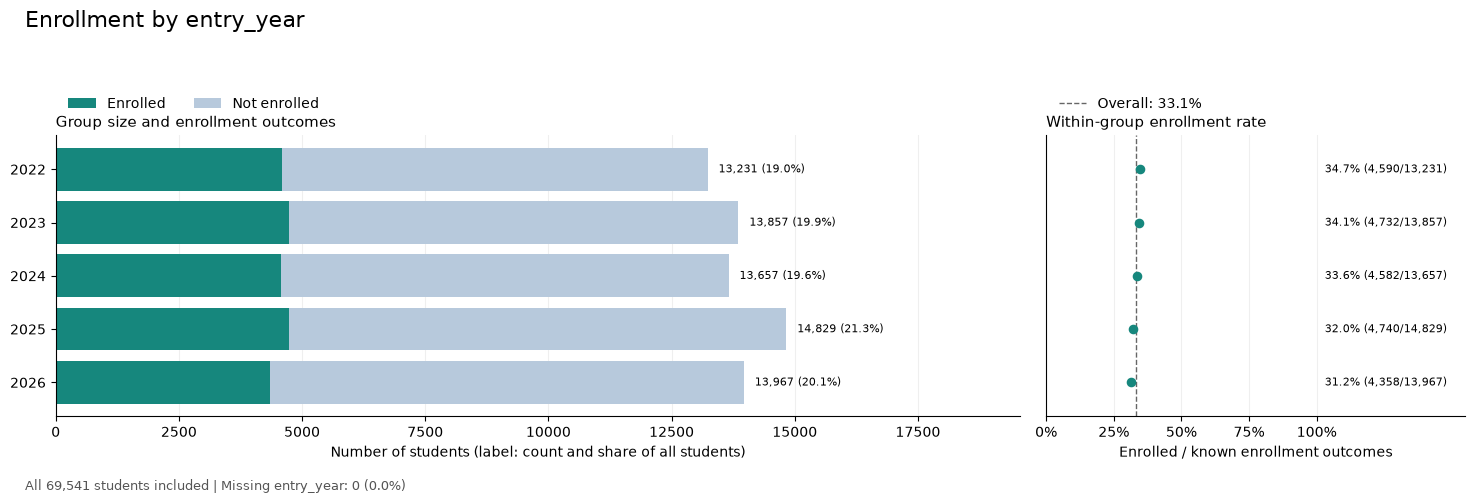

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
2022,4590,8641,0,13231,34.691255
2023,4732,9125,0,13857,34.148806
2024,4582,9075,0,13657,33.550560
2025,4740,10089,0,14829,31.964394
2026,4358,9609,0,13967,31.202119


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\entry_year.png


In [5]:
summary, saved_plot = plot_column(dataset, 'entry_year')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `credit_hrs`


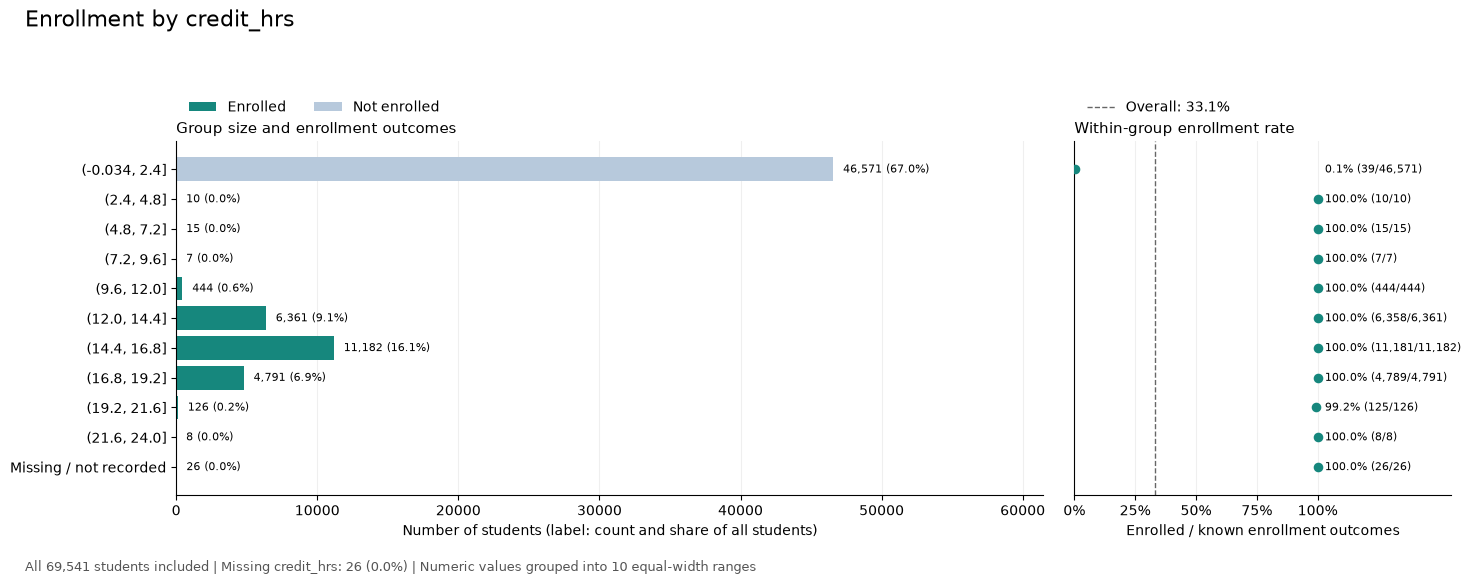

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
"(-0.034, 2.4]",39,46532,0,46571,0.083743
"(2.4, 4.8]",10,0,0,10,100.000000
"(4.8, 7.2]",15,0,0,15,100.000000
"(7.2, 9.6]",7,0,0,7,100.000000
"(9.6, 12.0]",444,0,0,444,100.000000
"(12.0, 14.4]",6358,3,0,6361,99.952838
"(14.4, 16.8]",11181,1,0,11182,99.991057
"(16.8, 19.2]",4789,2,0,4791,99.958255
"(19.2, 21.6]",125,1,0,126,99.206349


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\credit_hrs.png


In [6]:
summary, saved_plot = plot_column(dataset, 'credit_hrs')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `app_dt`


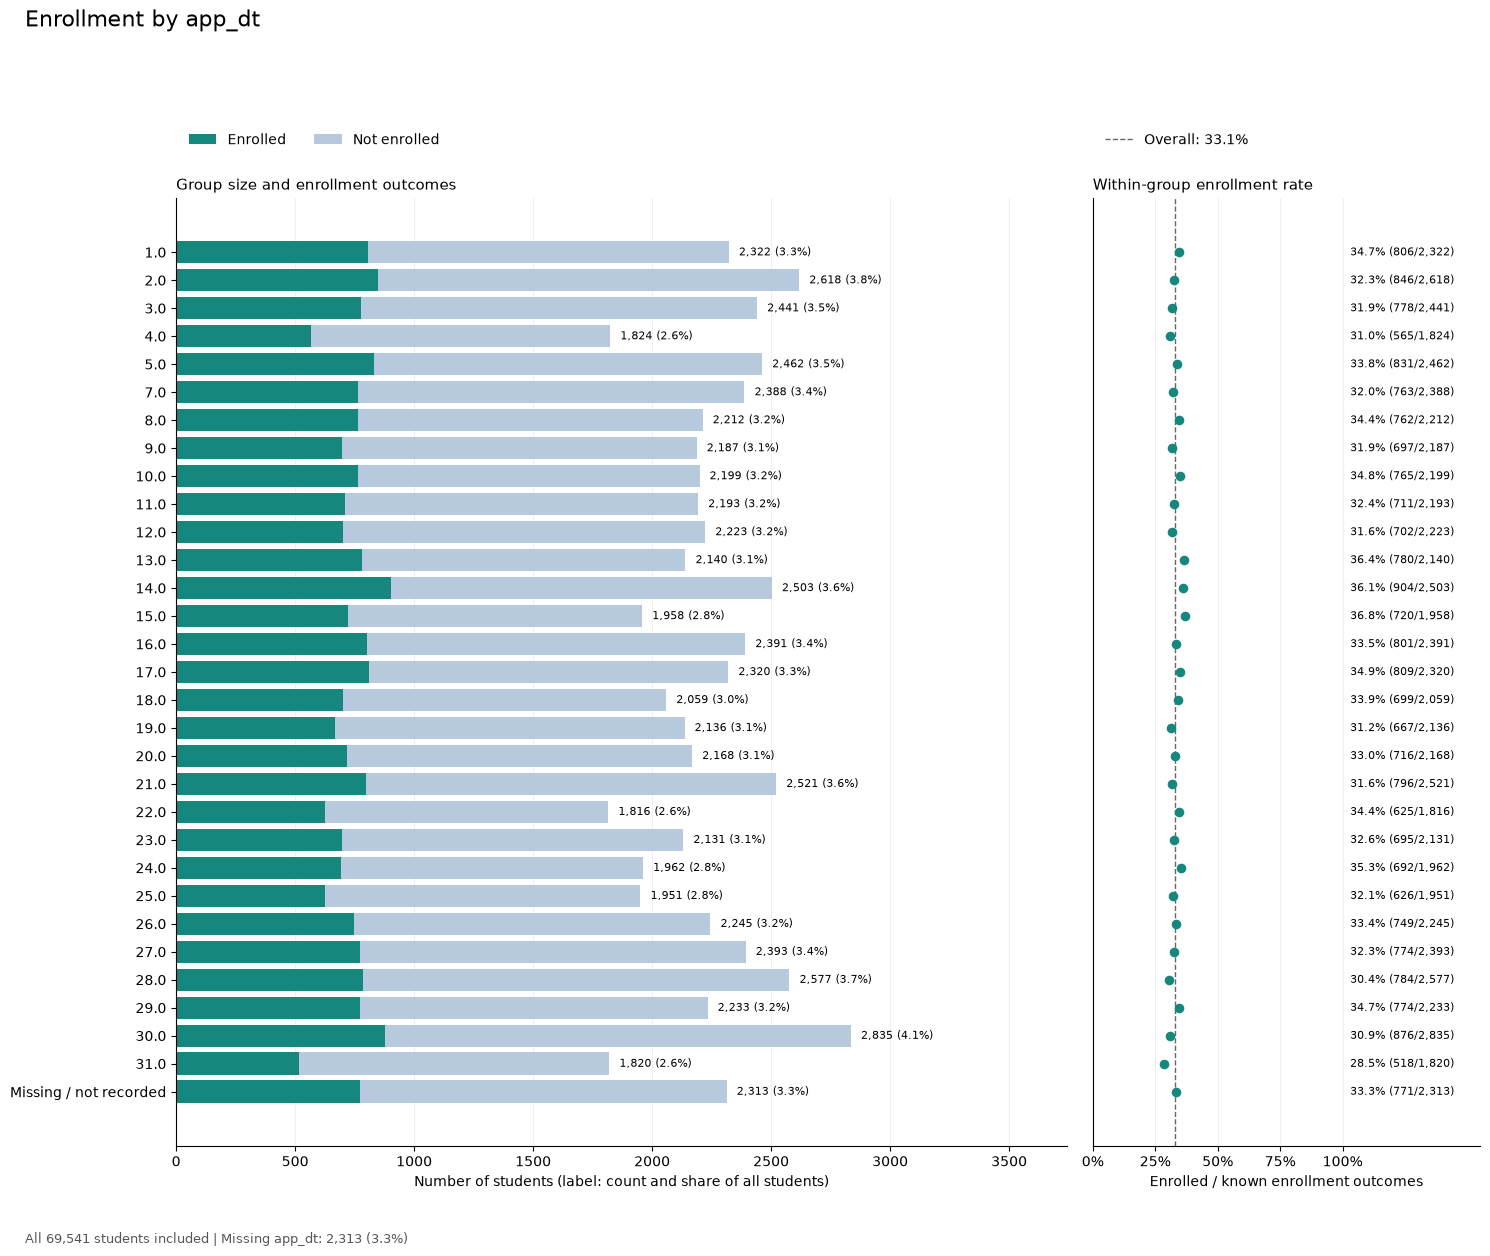

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
1.0,806,1516,0,2322,34.711456
2.0,846,1772,0,2618,32.314744
3.0,778,1663,0,2441,31.872184
4.0,565,1259,0,1824,30.975877
5.0,831,1631,0,2462,33.753046
7.0,763,1625,0,2388,31.951424
8.0,762,1450,0,2212,34.448463
9.0,697,1490,0,2187,31.870142
10.0,765,1434,0,2199,34.788540


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\app_dt.png


In [7]:
summary, saved_plot = plot_column(dataset, 'app_dt')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `app_mo`


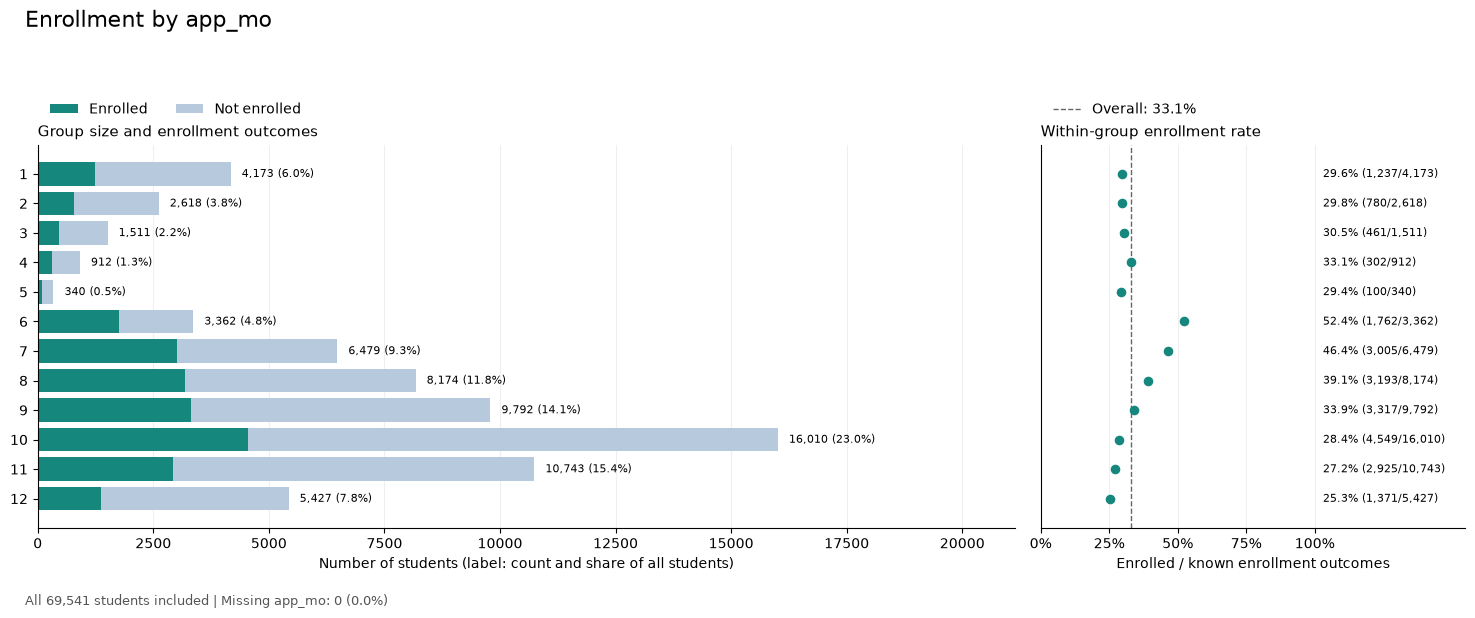

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
1,1237,2936,0,4173,29.642943
2,780,1838,0,2618,29.793736
3,461,1050,0,1511,30.509596
4,302,610,0,912,33.114035
5,100,240,0,340,29.411765
6,1762,1600,0,3362,52.409280
7,3005,3474,0,6479,46.380614
8,3193,4981,0,8174,39.062882
9,3317,6475,0,9792,33.874592


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\app_mo.png


In [8]:
summary, saved_plot = plot_column(dataset, 'app_mo')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `app_yr`


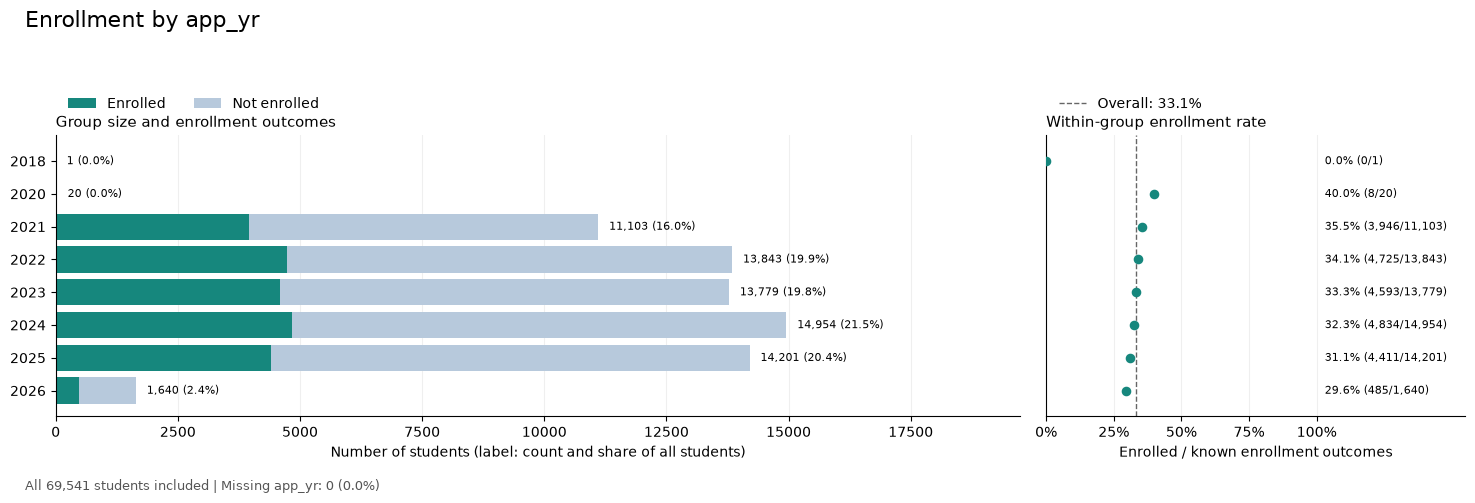

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
2018,0,1,0,1,0.000000
2020,8,12,0,20,40.000000
2021,3946,7157,0,11103,35.539944
2022,4725,9118,0,13843,34.132775
2023,4593,9186,0,13779,33.333333
2024,4834,10120,0,14954,32.325799
2025,4411,9790,0,14201,31.061193
2026,485,1155,0,1640,29.573171


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\app_yr.png


In [9]:
summary, saved_plot = plot_column(dataset, 'app_yr')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `app_fee`


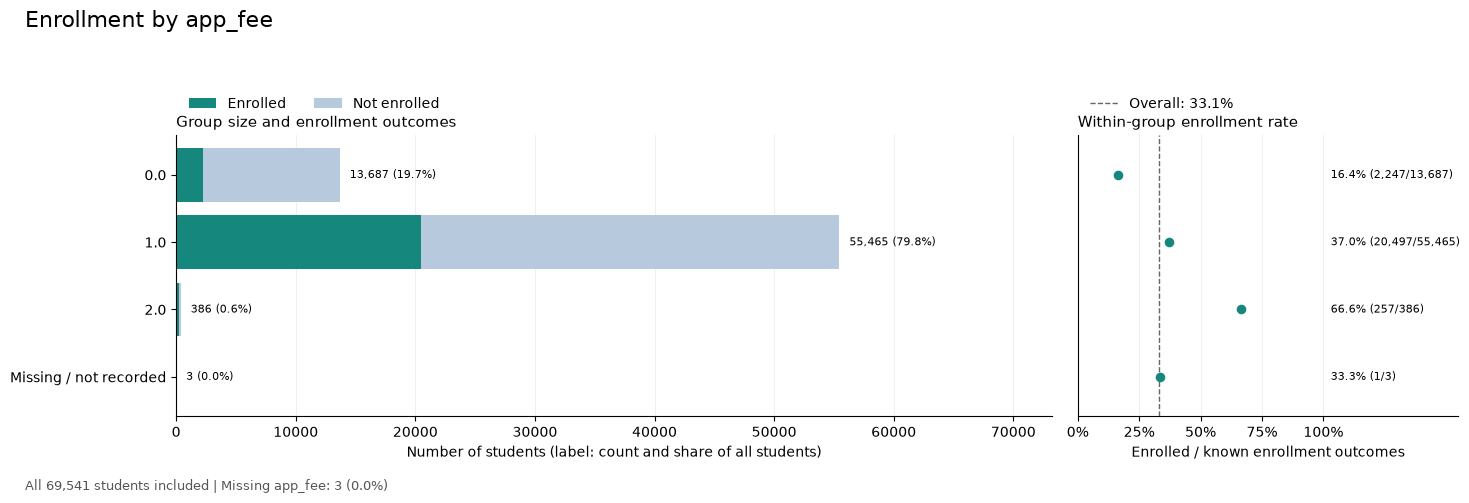

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
0.0,2247,11440,0,13687,16.417038
1.0,20497,34968,0,55465,36.954836
2.0,257,129,0,386,66.580311
Missing / not recorded,1,2,0,3,33.333333


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\app_fee.png


In [10]:
summary, saved_plot = plot_column(dataset, 'app_fee')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `acceptance_fee`


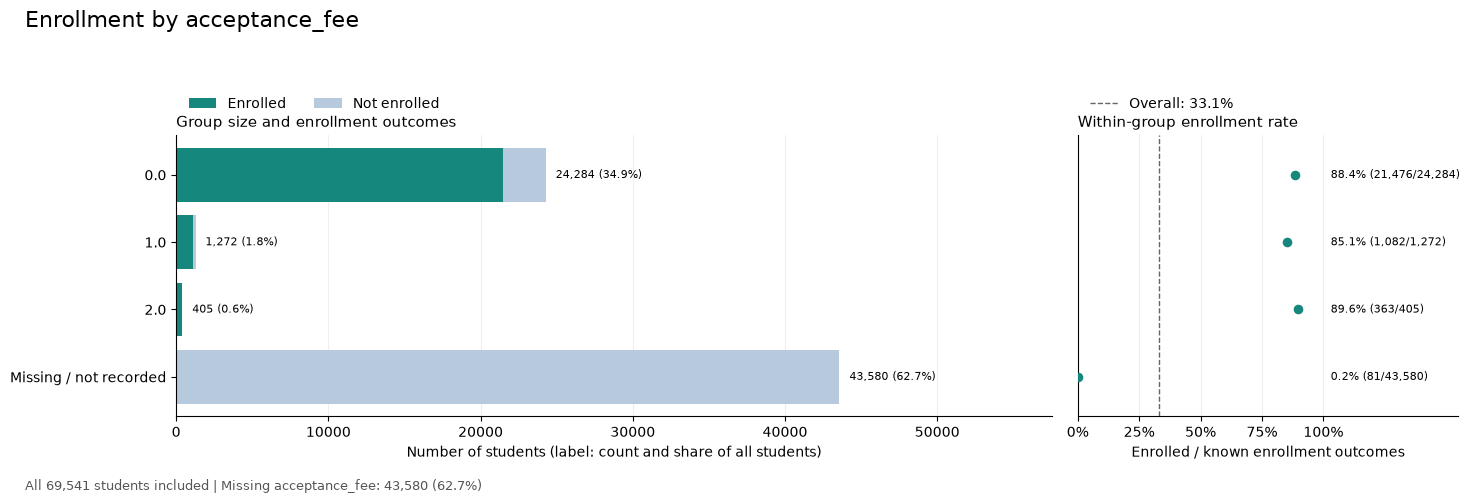

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
0.0,21476,2808,0,24284,88.436831
1.0,1082,190,0,1272,85.062893
2.0,363,42,0,405,89.629630
Missing / not recorded,81,43499,0,43580,0.185865


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\acceptance_fee.png


In [11]:
summary, saved_plot = plot_column(dataset, 'acceptance_fee')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `hs_gpa`


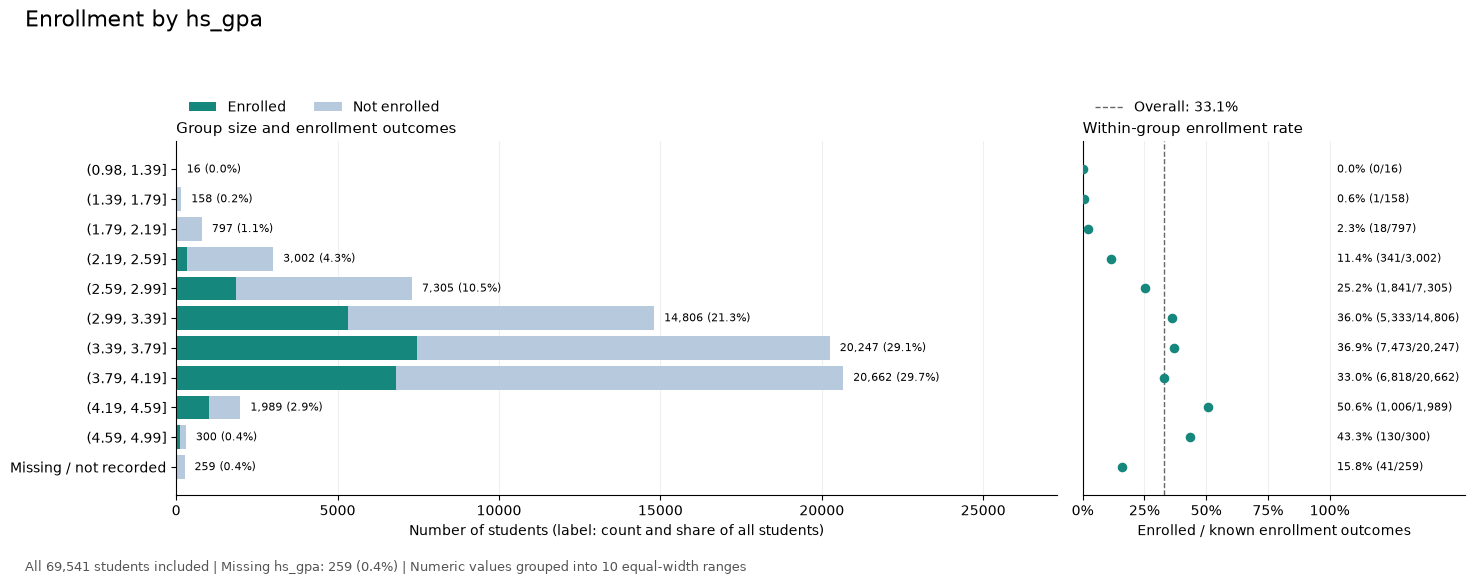

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
"(0.98, 1.39]",0,16,0,16,0.000000
"(1.39, 1.79]",1,157,0,158,0.632911
"(1.79, 2.19]",18,779,0,797,2.258469
"(2.19, 2.59]",341,2661,0,3002,11.359094
"(2.59, 2.99]",1841,5464,0,7305,25.201916
"(2.99, 3.39]",5333,9473,0,14806,36.019181
"(3.39, 3.79]",7473,12774,0,20247,36.909172
"(3.79, 4.19]",6818,13844,0,20662,32.997774
"(4.19, 4.59]",1006,983,0,1989,50.578180


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\hs_gpa.png


In [12]:
summary, saved_plot = plot_column(dataset, 'hs_gpa')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `act_cmpst`


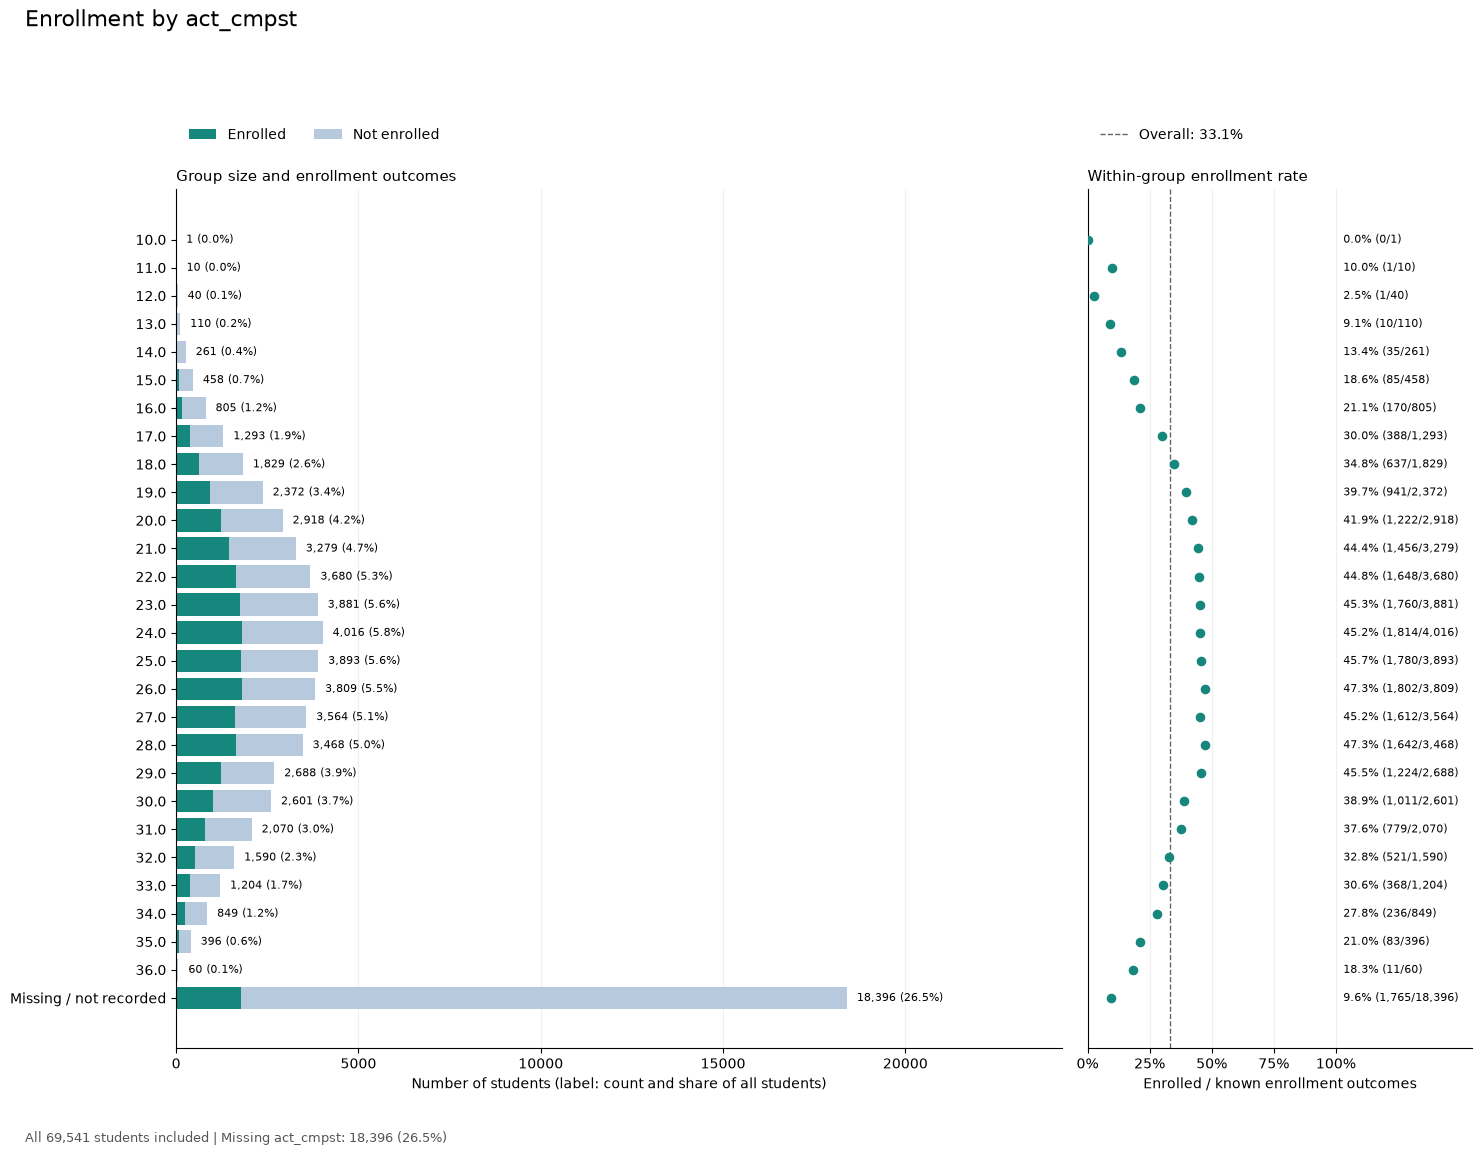

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
10.0,0,1,0,1,0.000000
11.0,1,9,0,10,10.000000
12.0,1,39,0,40,2.500000
13.0,10,100,0,110,9.090909
14.0,35,226,0,261,13.409962
15.0,85,373,0,458,18.558952
16.0,170,635,0,805,21.118012
17.0,388,905,0,1293,30.007734
18.0,637,1192,0,1829,34.827775


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\act_cmpst.png


In [13]:
summary, saved_plot = plot_column(dataset, 'act_cmpst')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `act_engl`


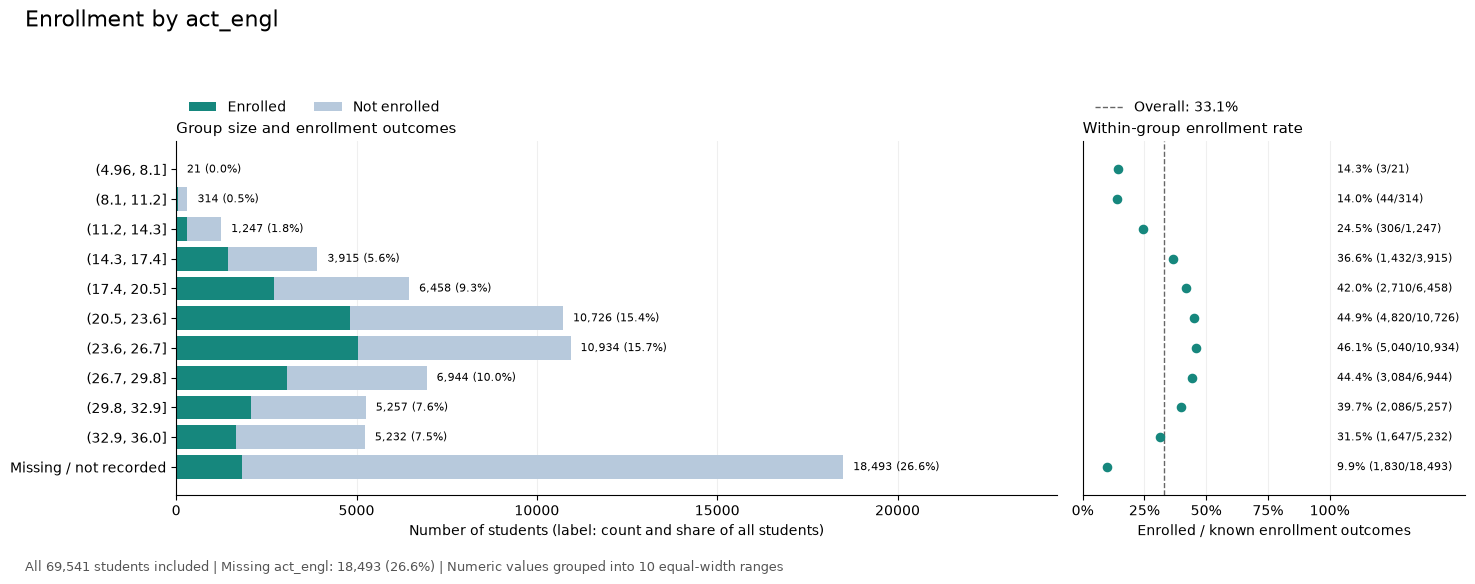

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
"(4.96, 8.1]",3,18,0,21,14.285714
"(8.1, 11.2]",44,270,0,314,14.012739
"(11.2, 14.3]",306,941,0,1247,24.538893
"(14.3, 17.4]",1432,2483,0,3915,36.577267
"(17.4, 20.5]",2710,3748,0,6458,41.963456
"(20.5, 23.6]",4820,5906,0,10726,44.937535
"(23.6, 26.7]",5040,5894,0,10934,46.094750
"(26.7, 29.8]",3084,3860,0,6944,44.412442
"(29.8, 32.9]",2086,3171,0,5257,39.680426


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\act_engl.png


In [14]:
summary, saved_plot = plot_column(dataset, 'act_engl')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `act_math`


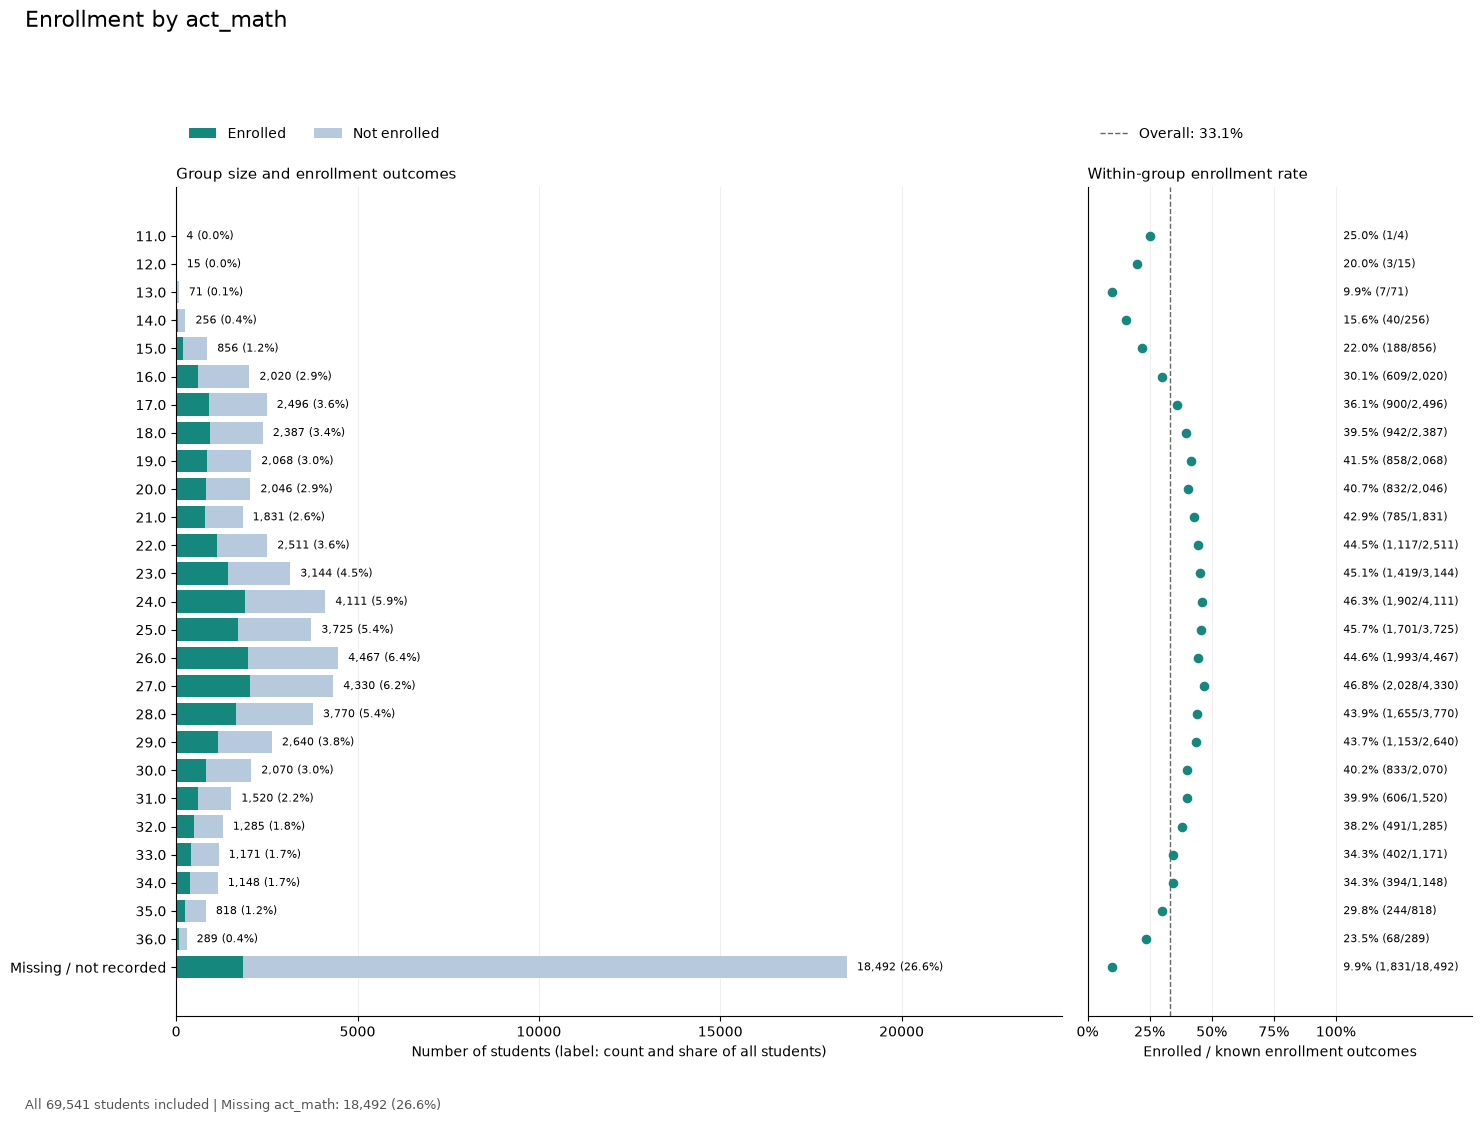

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
11.0,1,3,0,4,25.000000
12.0,3,12,0,15,20.000000
13.0,7,64,0,71,9.859155
14.0,40,216,0,256,15.625000
15.0,188,668,0,856,21.962617
16.0,609,1411,0,2020,30.148515
17.0,900,1596,0,2496,36.057692
18.0,942,1445,0,2387,39.463762
19.0,858,1210,0,2068,41.489362


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\act_math.png


In [15]:
summary, saved_plot = plot_column(dataset, 'act_math')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `sat_comb`


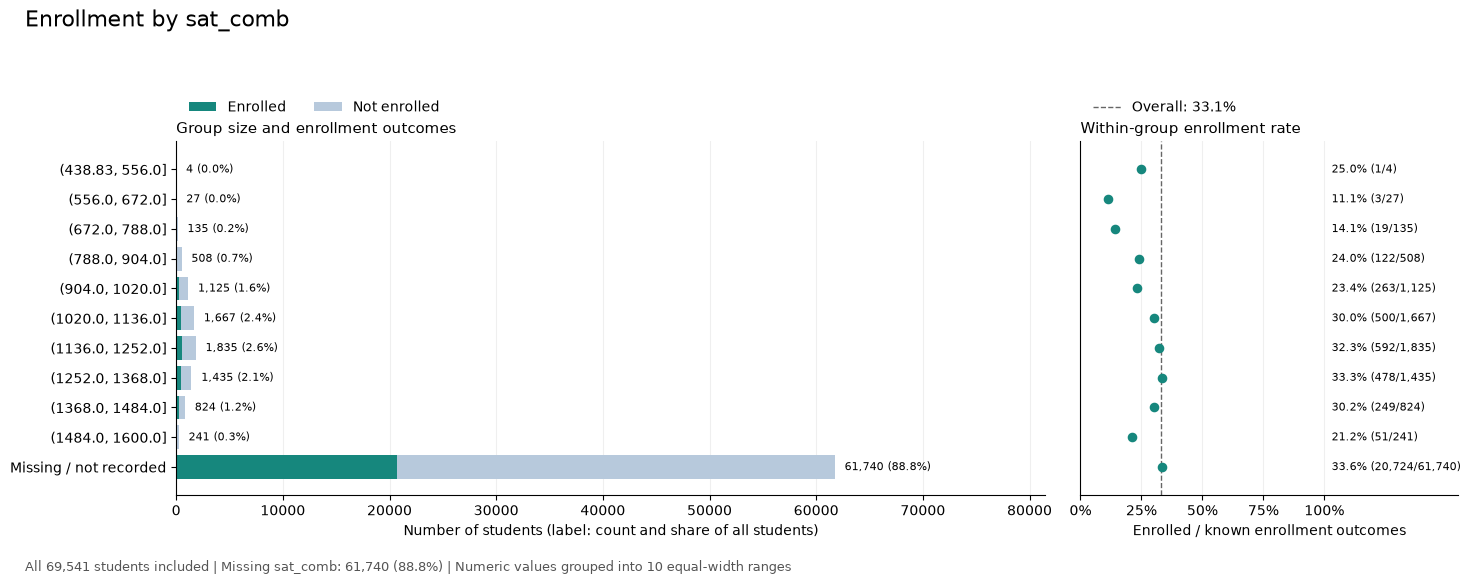

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
"(438.83, 556.0]",1,3,0,4,25.000000
"(556.0, 672.0]",3,24,0,27,11.111111
"(672.0, 788.0]",19,116,0,135,14.074074
"(788.0, 904.0]",122,386,0,508,24.015748
"(904.0, 1020.0]",263,862,0,1125,23.377778
"(1020.0, 1136.0]",500,1167,0,1667,29.994001
"(1136.0, 1252.0]",592,1243,0,1835,32.261580
"(1252.0, 1368.0]",478,957,0,1435,33.310105
"(1368.0, 1484.0]",249,575,0,824,30.218447


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\sat_comb.png


In [16]:
summary, saved_plot = plot_column(dataset, 'sat_comb')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `sat_vrbl`


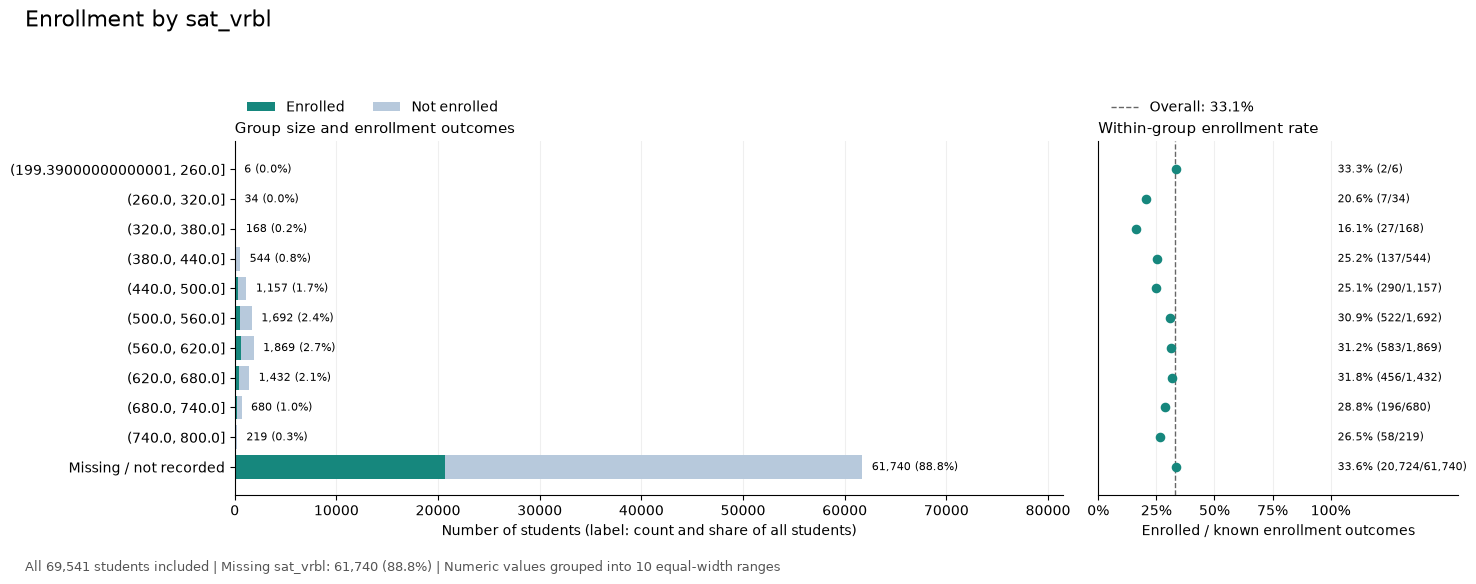

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
"(199.39000000000001, 260.0]",2,4,0,6,33.333333
"(260.0, 320.0]",7,27,0,34,20.588235
"(320.0, 380.0]",27,141,0,168,16.071429
"(380.0, 440.0]",137,407,0,544,25.183824
"(440.0, 500.0]",290,867,0,1157,25.064823
"(500.0, 560.0]",522,1170,0,1692,30.851064
"(560.0, 620.0]",583,1286,0,1869,31.193151
"(620.0, 680.0]",456,976,0,1432,31.843575
"(680.0, 740.0]",196,484,0,680,28.823529


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\sat_vrbl.png


In [17]:
summary, saved_plot = plot_column(dataset, 'sat_vrbl')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `sat_math`


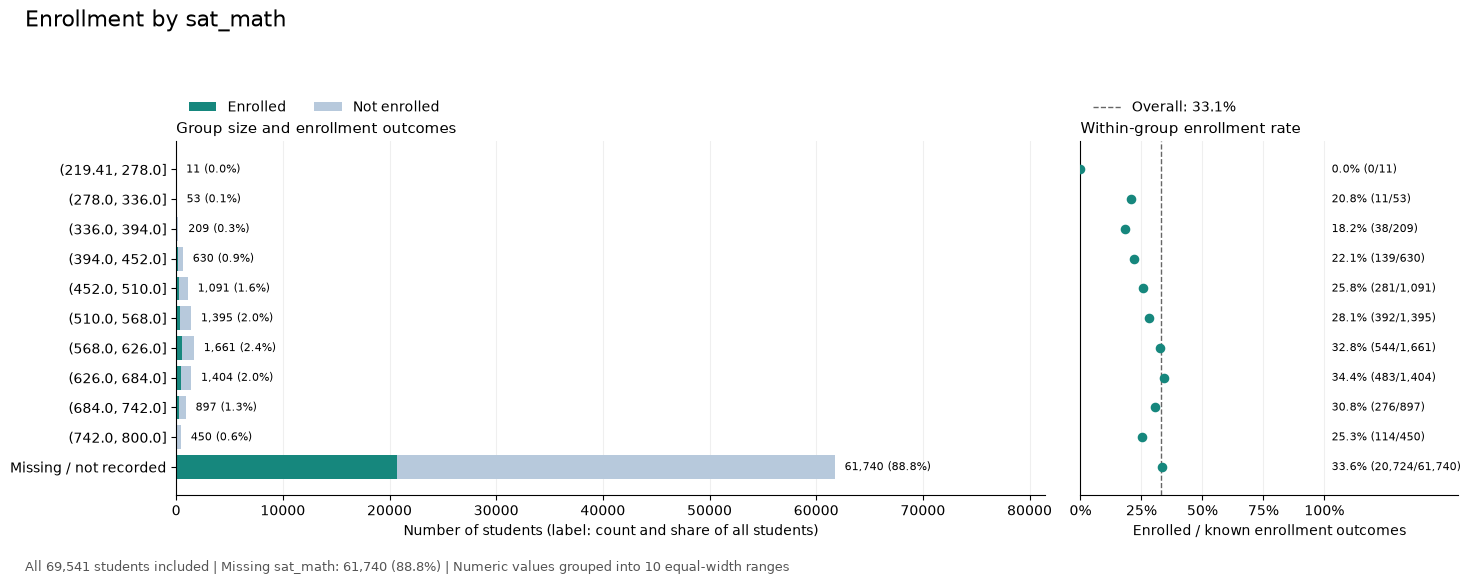

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
"(219.41, 278.0]",0,11,0,11,0.000000
"(278.0, 336.0]",11,42,0,53,20.754717
"(336.0, 394.0]",38,171,0,209,18.181818
"(394.0, 452.0]",139,491,0,630,22.063492
"(452.0, 510.0]",281,810,0,1091,25.756187
"(510.0, 568.0]",392,1003,0,1395,28.100358
"(568.0, 626.0]",544,1117,0,1661,32.751355
"(626.0, 684.0]",483,921,0,1404,34.401709
"(684.0, 742.0]",276,621,0,897,30.769231


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\sat_math.png


In [18]:
summary, saved_plot = plot_column(dataset, 'sat_math')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `deposit_dt`


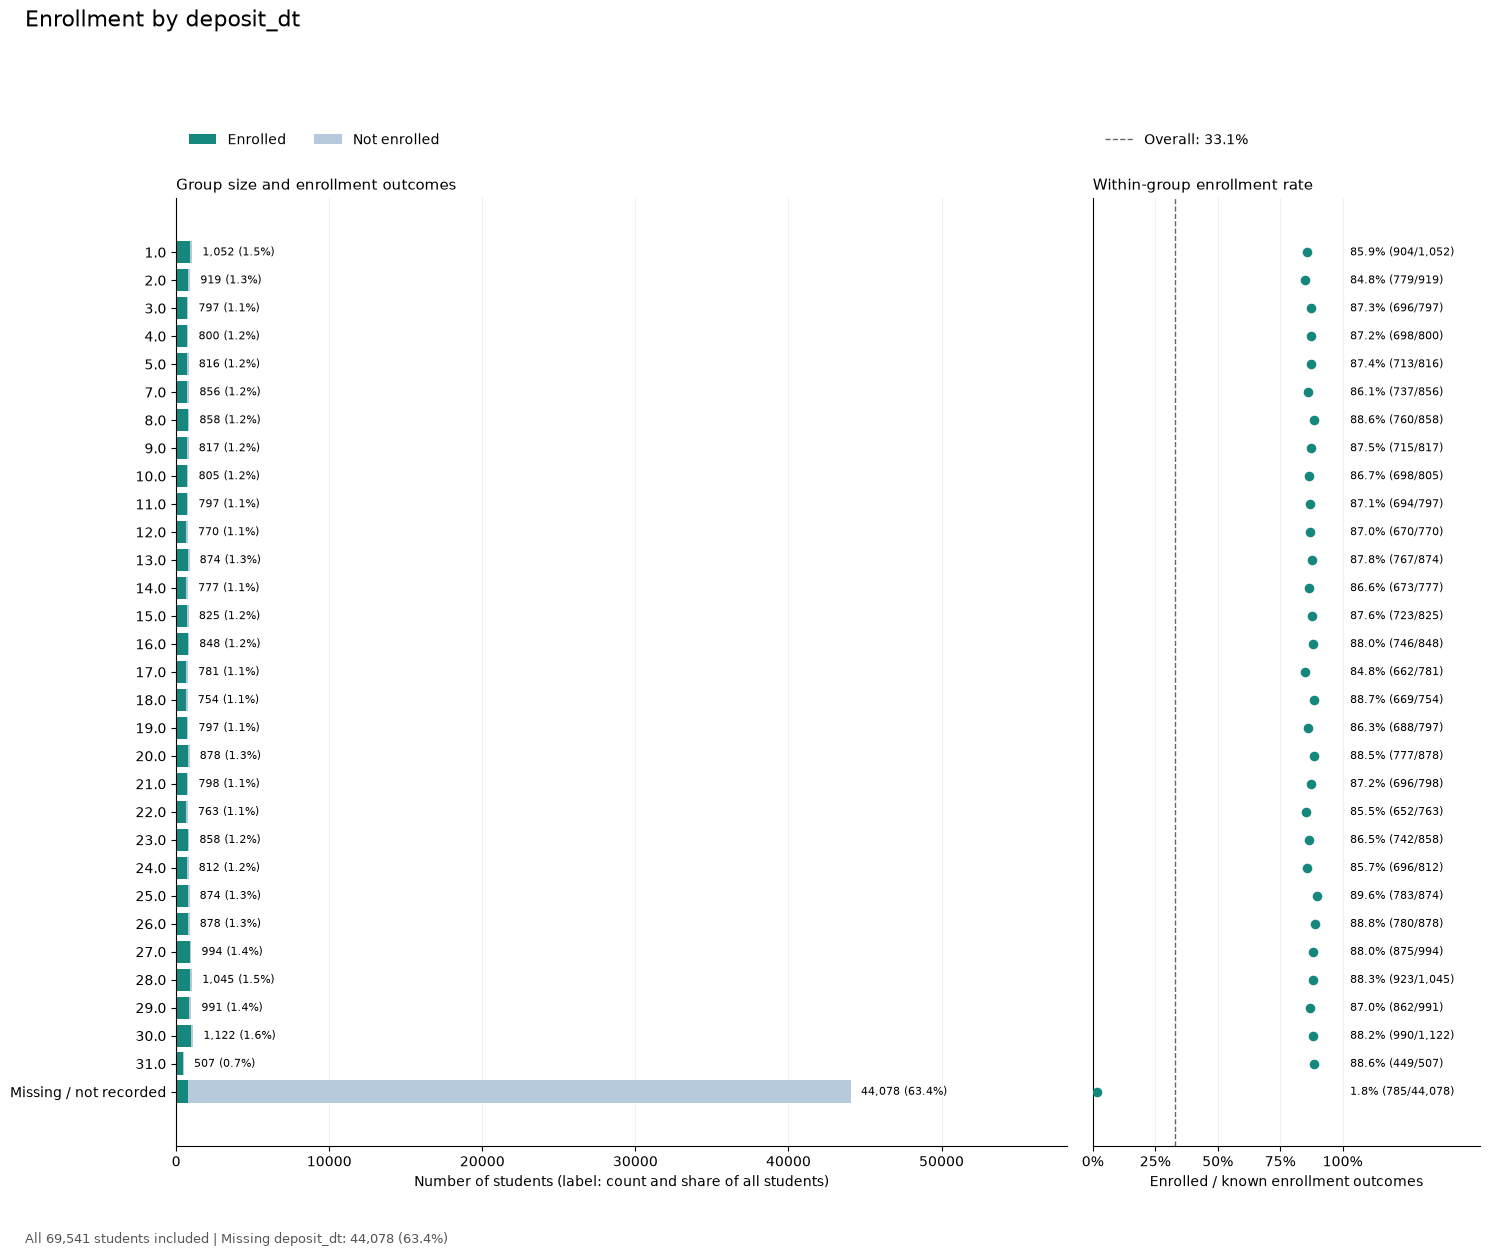

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
1.0,904,148,0,1052,85.931559
2.0,779,140,0,919,84.766050
3.0,696,101,0,797,87.327478
4.0,698,102,0,800,87.250000
5.0,713,103,0,816,87.377451
7.0,737,119,0,856,86.098131
8.0,760,98,0,858,88.578089
9.0,715,102,0,817,87.515300
10.0,698,107,0,805,86.708075


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\deposit_dt.png


In [19]:
summary, saved_plot = plot_column(dataset, 'deposit_dt')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `deposit_mo`


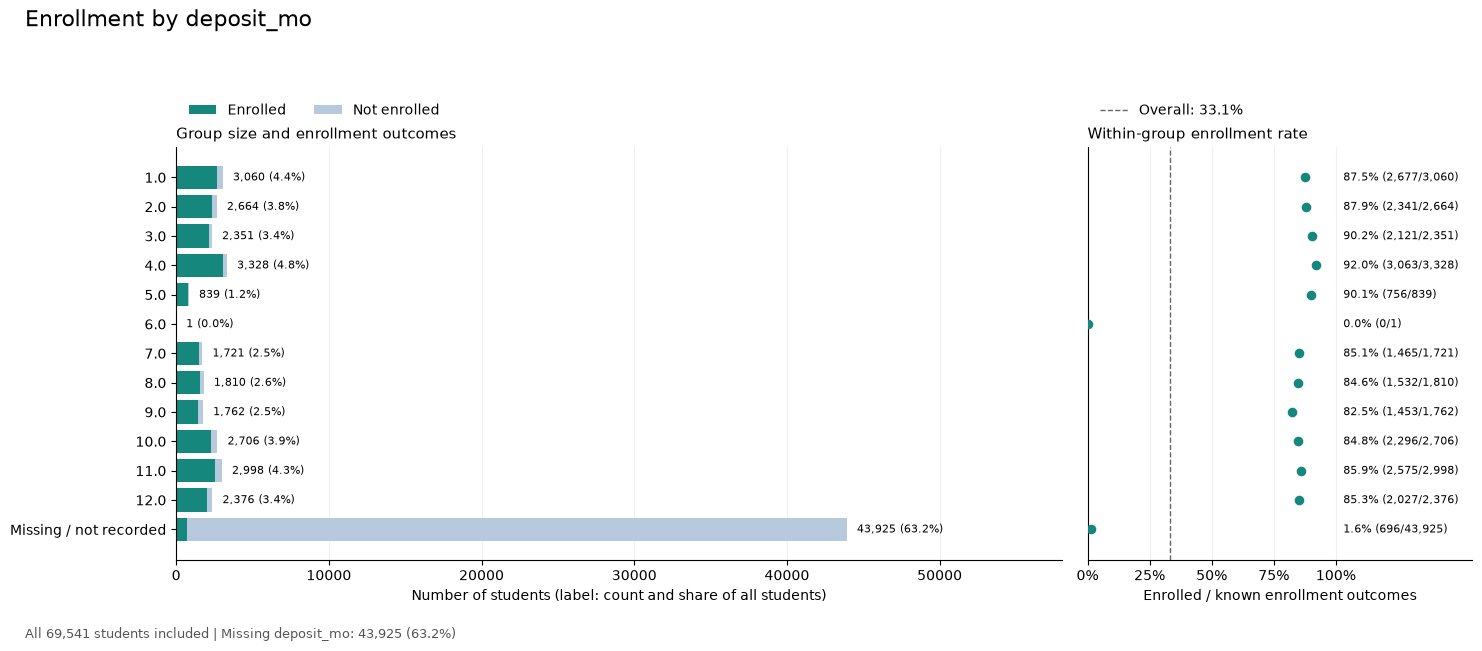

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
1.0,2677,383,0,3060,87.483660
2.0,2341,323,0,2664,87.875375
3.0,2121,230,0,2351,90.216929
4.0,3063,265,0,3328,92.037260
5.0,756,83,0,839,90.107271
6.0,0,1,0,1,0.000000
7.0,1465,256,0,1721,85.124927
8.0,1532,278,0,1810,84.640884
9.0,1453,309,0,1762,82.463110


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\deposit_mo.png


In [20]:
summary, saved_plot = plot_column(dataset, 'deposit_mo')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `deposit_yr`


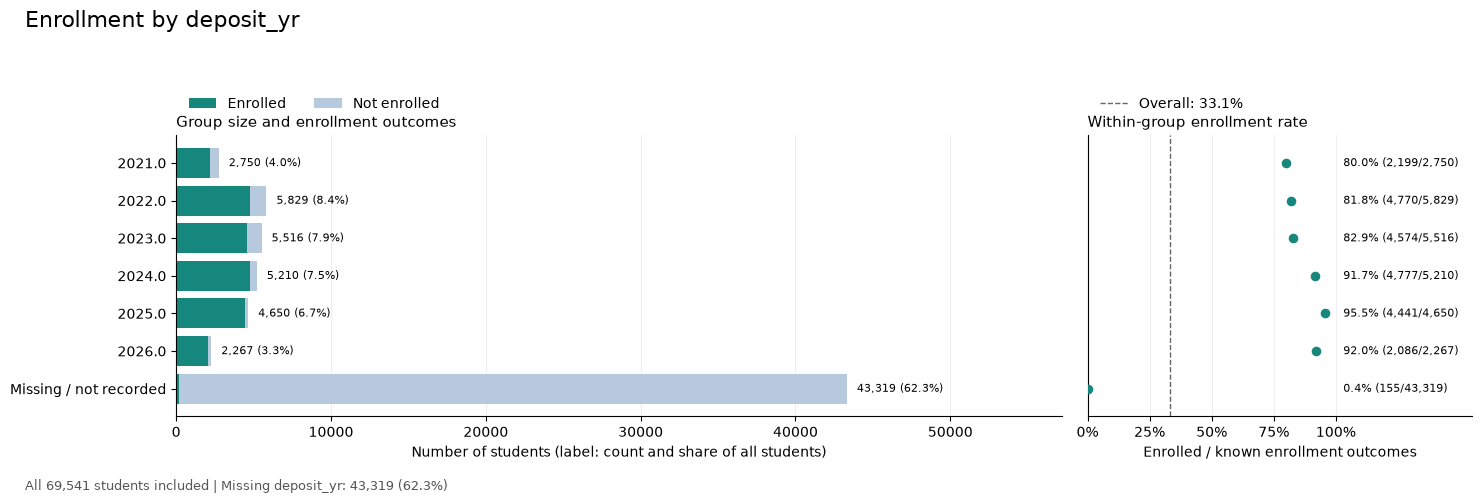

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
2021.0,2199,551,0,2750,79.963636
2022.0,4770,1059,0,5829,81.832218
2023.0,4574,942,0,5516,82.922408
2024.0,4777,433,0,5210,91.689060
2025.0,4441,209,0,4650,95.505376
2026.0,2086,181,0,2267,92.015880
Missing / not recorded,155,43164,0,43319,0.357811


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\deposit_yr.png


In [21]:
summary, saved_plot = plot_column(dataset, 'deposit_yr')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `hs_math`


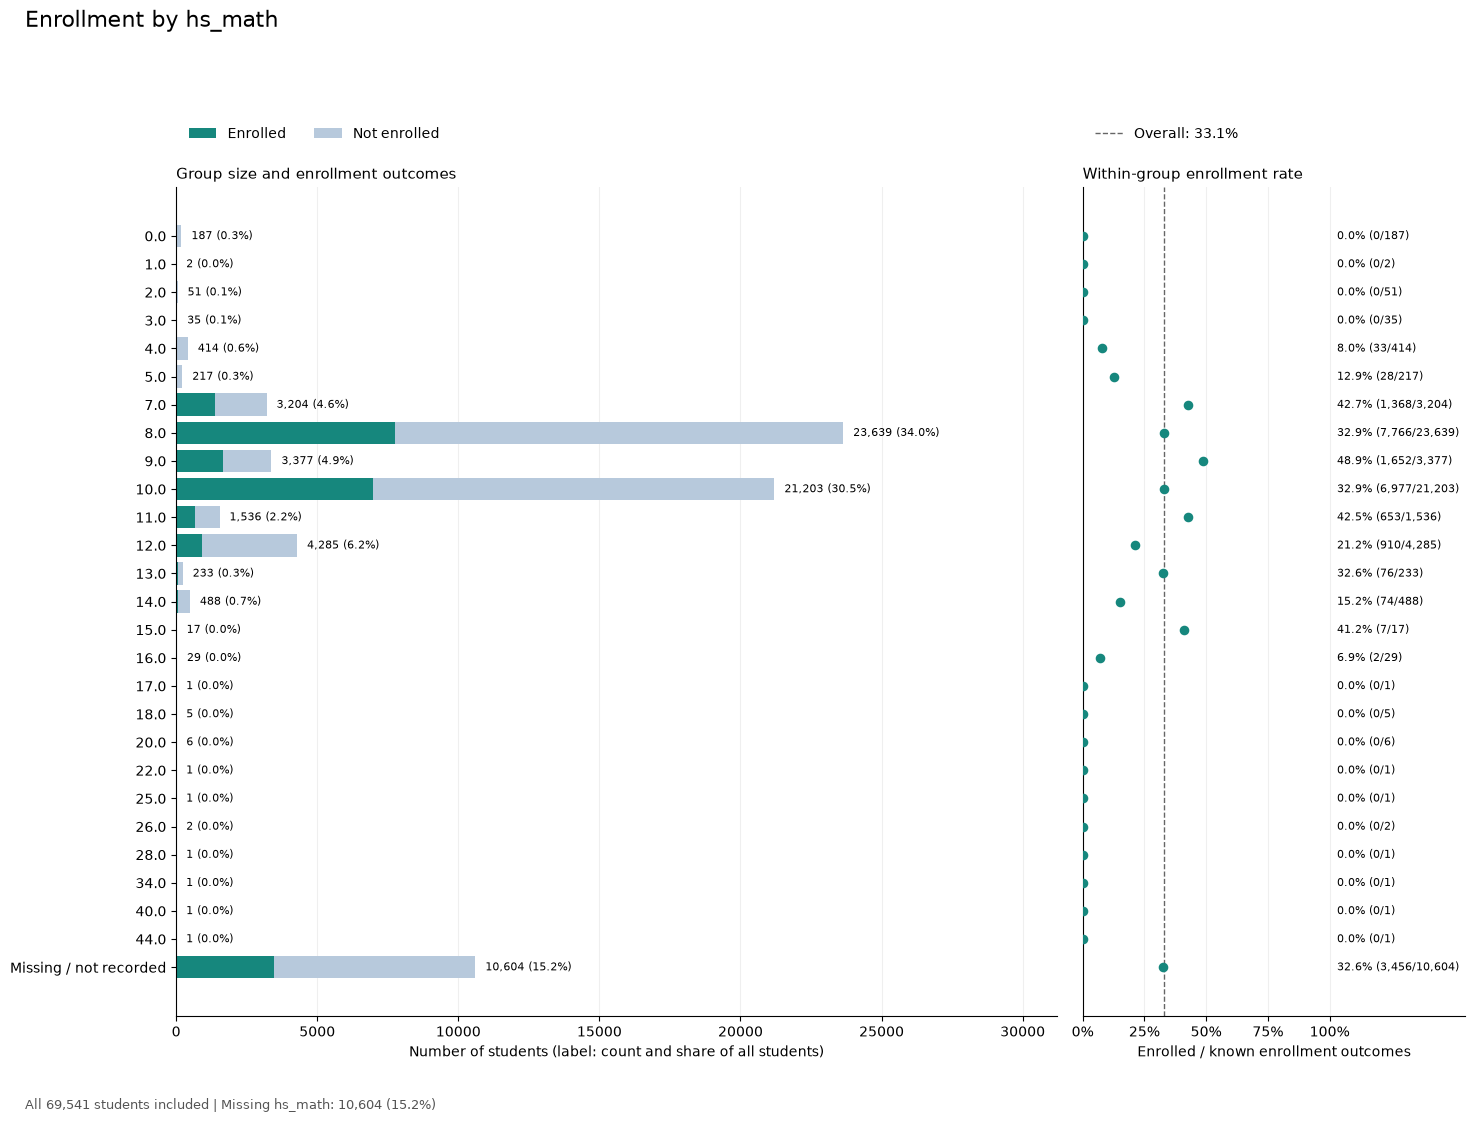

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
0.0,0,187,0,187,0.000000
1.0,0,2,0,2,0.000000
2.0,0,51,0,51,0.000000
3.0,0,35,0,35,0.000000
4.0,33,381,0,414,7.971014
5.0,28,189,0,217,12.903226
7.0,1368,1836,0,3204,42.696629
8.0,7766,15873,0,23639,32.852490
9.0,1652,1725,0,3377,48.919159


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\hs_math.png


In [22]:
summary, saved_plot = plot_column(dataset, 'hs_math')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `hs_sci`


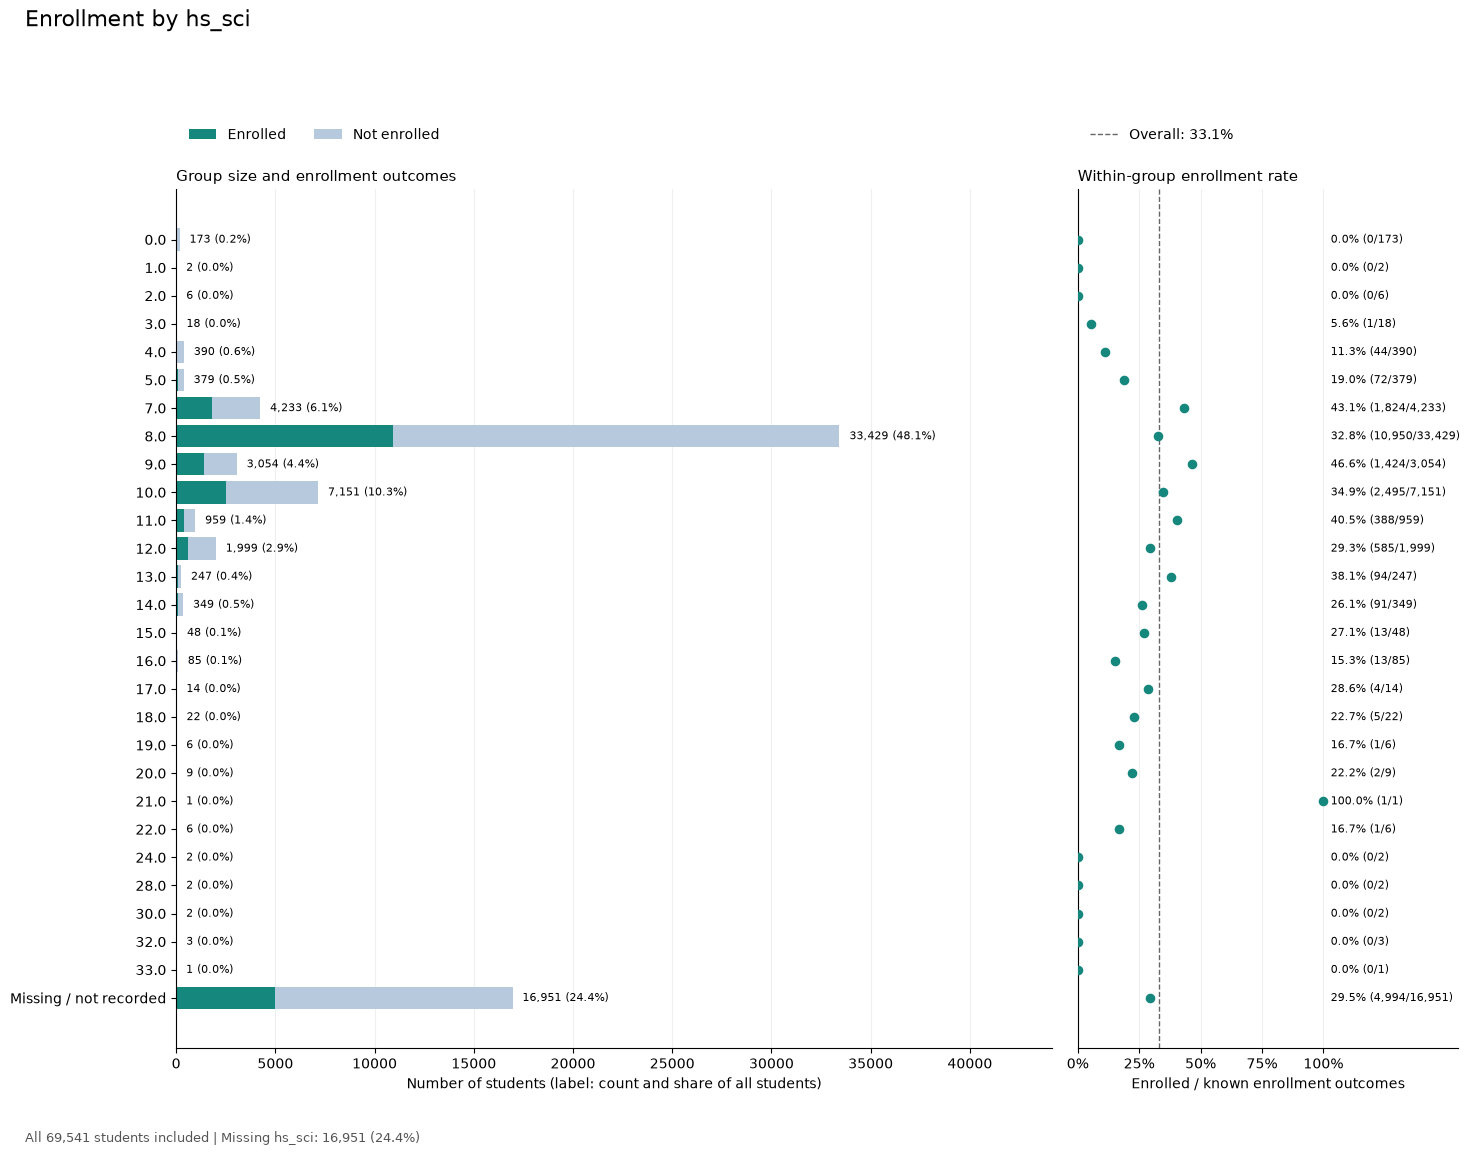

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
0.0,0,173,0,173,0.000000
1.0,0,2,0,2,0.000000
2.0,0,6,0,6,0.000000
3.0,1,17,0,18,5.555556
4.0,44,346,0,390,11.282051
5.0,72,307,0,379,18.997361
7.0,1824,2409,0,4233,43.090007
8.0,10950,22479,0,33429,32.755990
9.0,1424,1630,0,3054,46.627374


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\hs_sci.png


In [23]:
summary, saved_plot = plot_column(dataset, 'hs_sci')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `hs_engl`


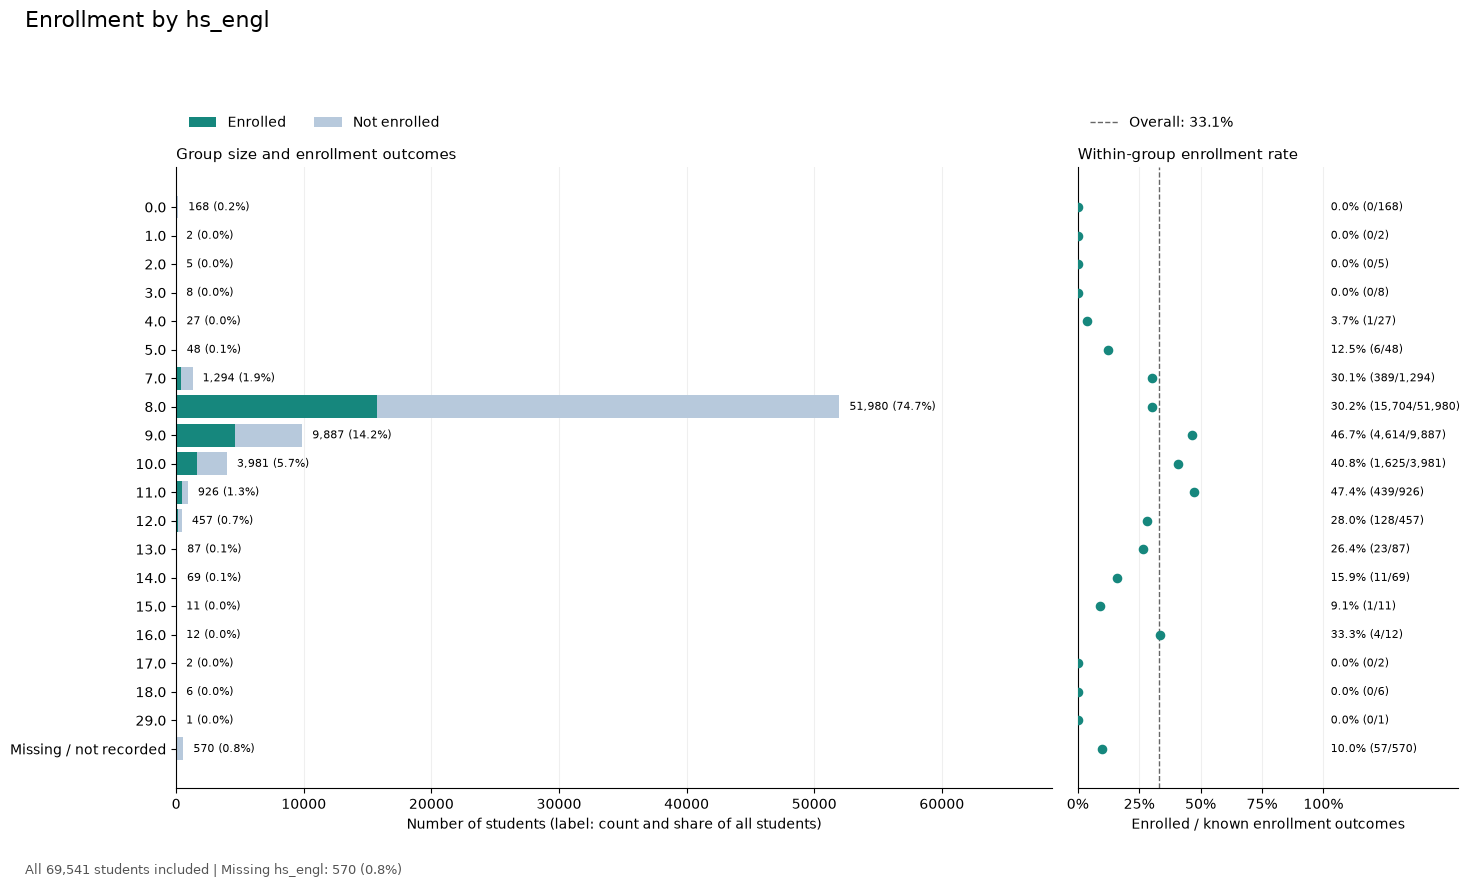

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
0.0,0,168,0,168,0.000000
1.0,0,2,0,2,0.000000
2.0,0,5,0,5,0.000000
3.0,0,8,0,8,0.000000
4.0,1,26,0,27,3.703704
5.0,6,42,0,48,12.500000
7.0,389,905,0,1294,30.061824
8.0,15704,36276,0,51980,30.211620
9.0,4614,5273,0,9887,46.667341


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\hs_engl.png


In [24]:
summary, saved_plot = plot_column(dataset, 'hs_engl')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `hs_ss`


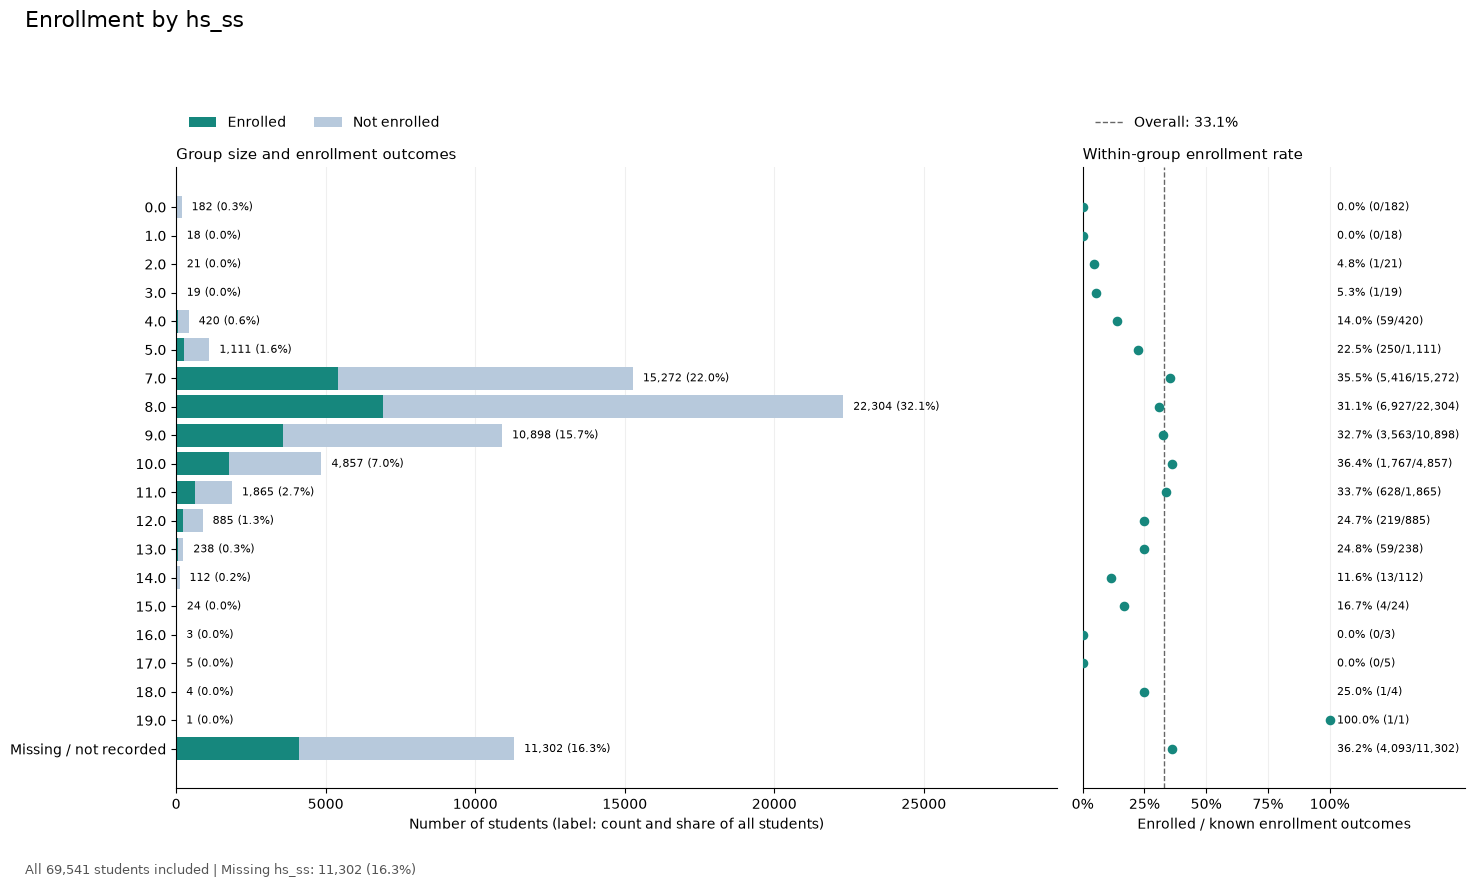

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
0.0,0,182,0,182,0.000000
1.0,0,18,0,18,0.000000
2.0,1,20,0,21,4.761905
3.0,1,18,0,19,5.263158
4.0,59,361,0,420,14.047619
5.0,250,861,0,1111,22.502250
7.0,5416,9856,0,15272,35.463594
8.0,6927,15377,0,22304,31.057209
9.0,3563,7335,0,10898,32.694072


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\hs_ss.png


In [25]:
summary, saved_plot = plot_column(dataset, 'hs_ss')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `hs_flang`


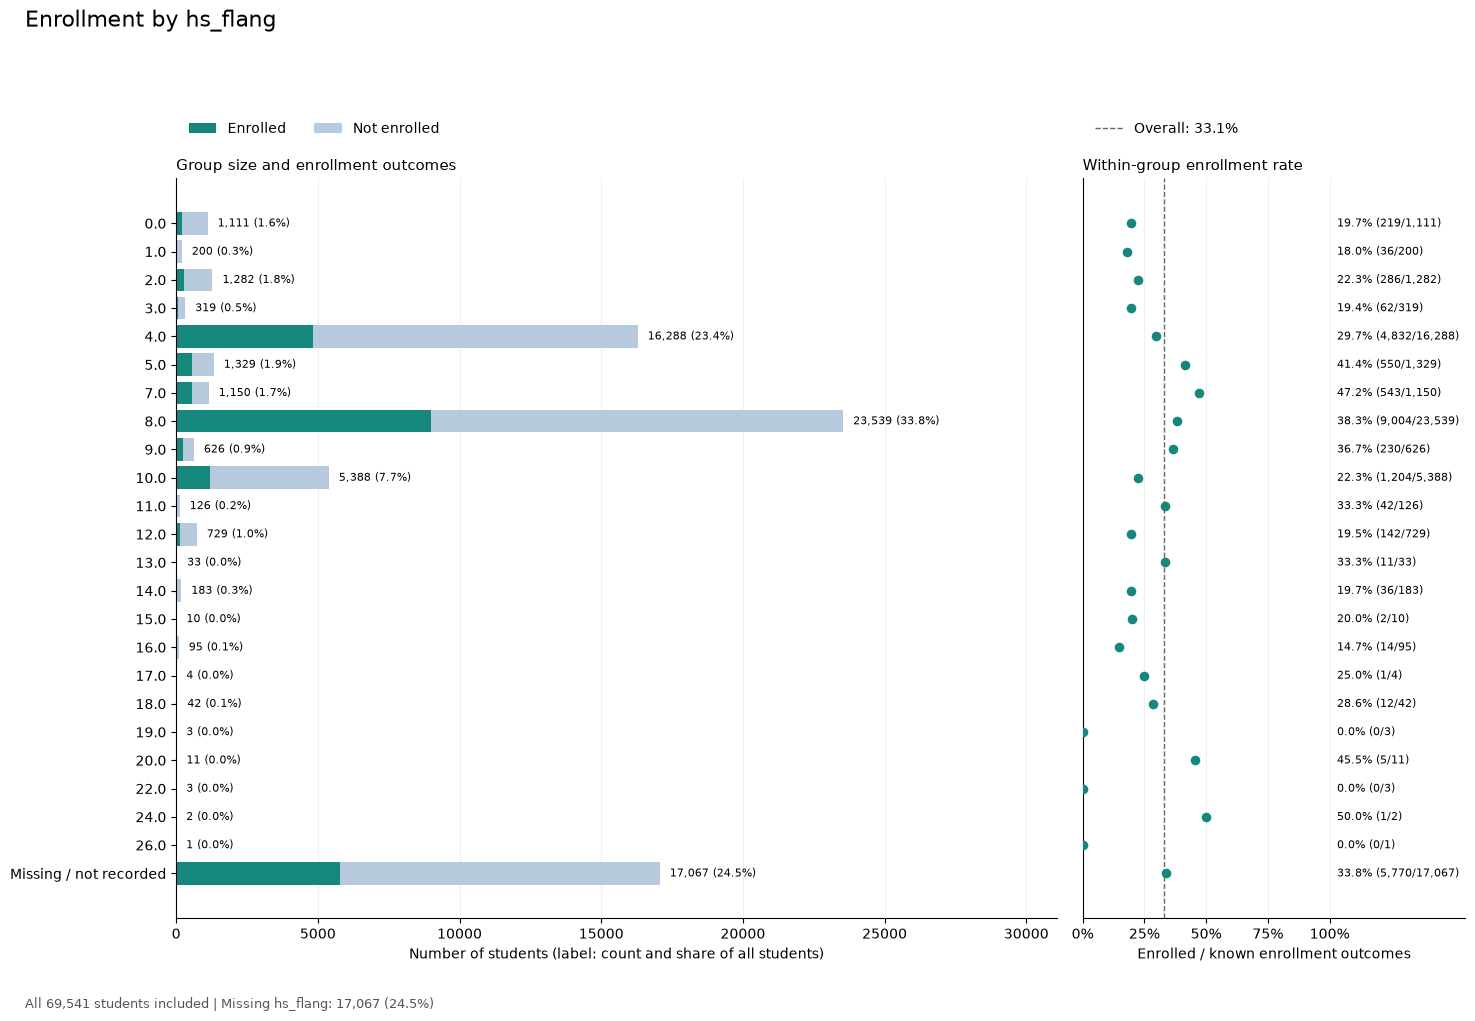

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
0.0,219,892,0,1111,19.711971
1.0,36,164,0,200,18.000000
2.0,286,996,0,1282,22.308892
3.0,62,257,0,319,19.435737
4.0,4832,11456,0,16288,29.666012
5.0,550,779,0,1329,41.384500
7.0,543,607,0,1150,47.217391
8.0,9004,14535,0,23539,38.251413
9.0,230,396,0,626,36.741214


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\hs_flang.png


In [26]:
summary, saved_plot = plot_column(dataset, 'hs_flang')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `residency`


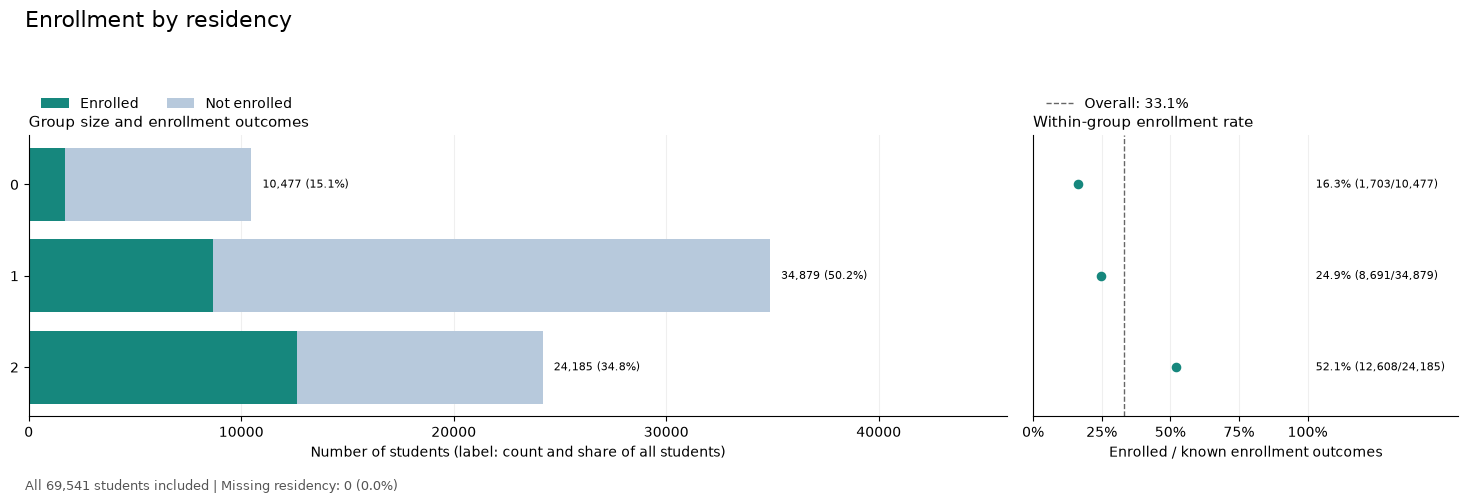

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
0,1703,8774,0,10477,16.254653
1,8691,26188,0,34879,24.917572
2,12608,11577,0,24185,52.131486


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\residency.png


In [27]:
summary, saved_plot = plot_column(dataset, 'residency')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `applied`


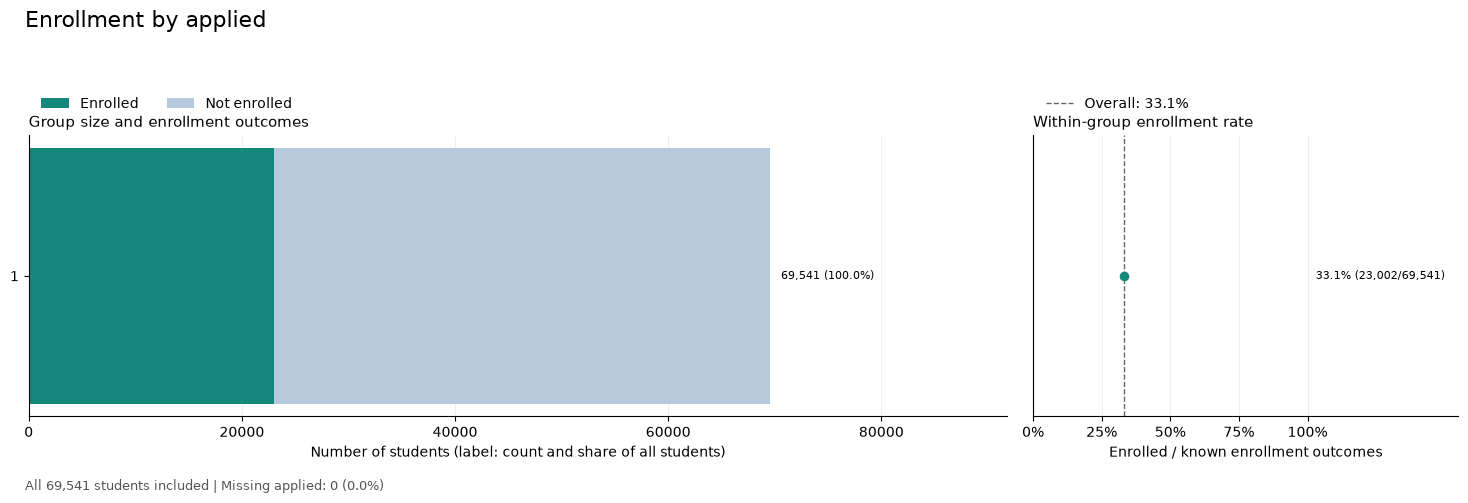

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
1,23002,46539,0,69541,33.07689


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\applied.png


In [28]:
summary, saved_plot = plot_column(dataset, 'applied')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `app_completed`


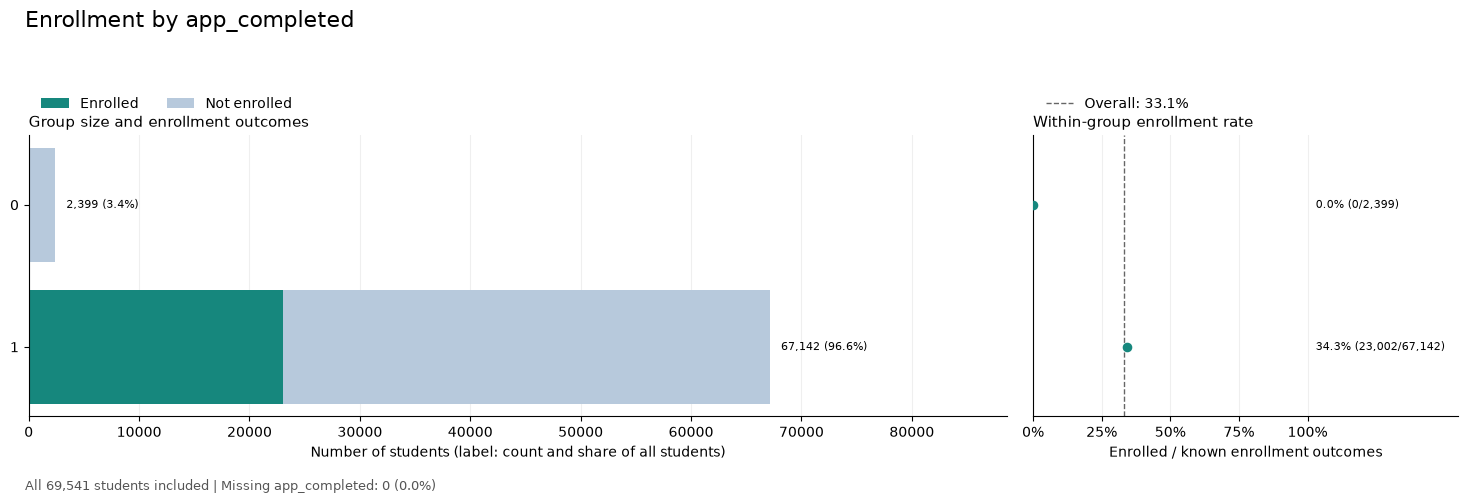

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
0,0,2399,0,2399,0.000000
1,23002,44140,0,67142,34.258735


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\app_completed.png


In [29]:
summary, saved_plot = plot_column(dataset, 'app_completed')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `admitted`


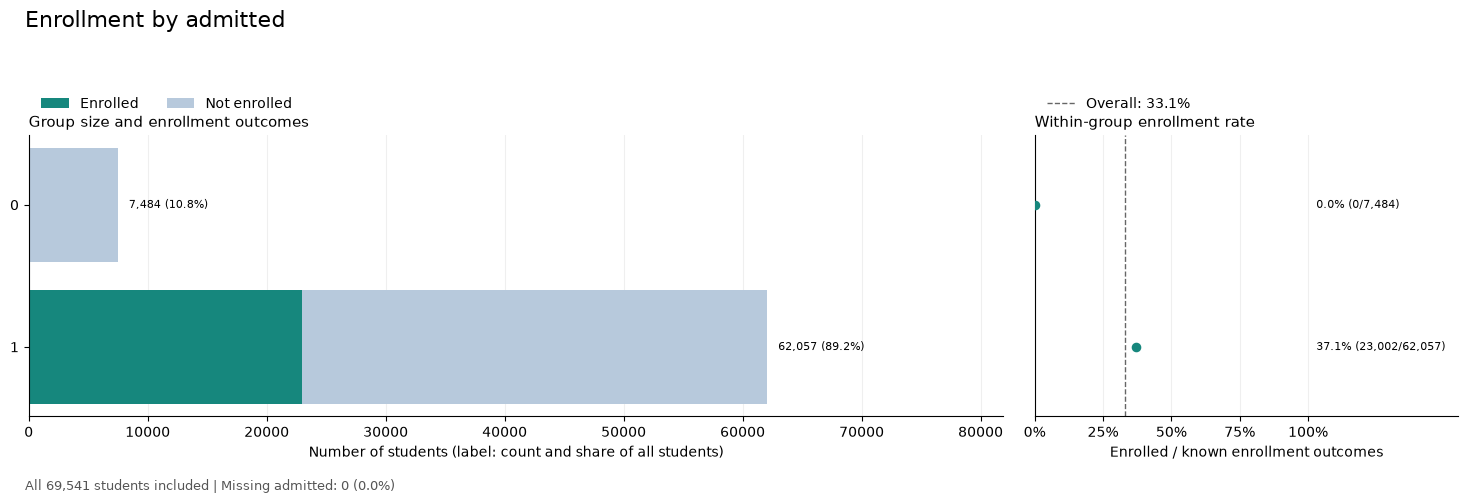

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
0,0,7484,0,7484,0.000000
1,23002,39055,0,62057,37.065923


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\admitted.png


In [30]:
summary, saved_plot = plot_column(dataset, 'admitted')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `deposited`


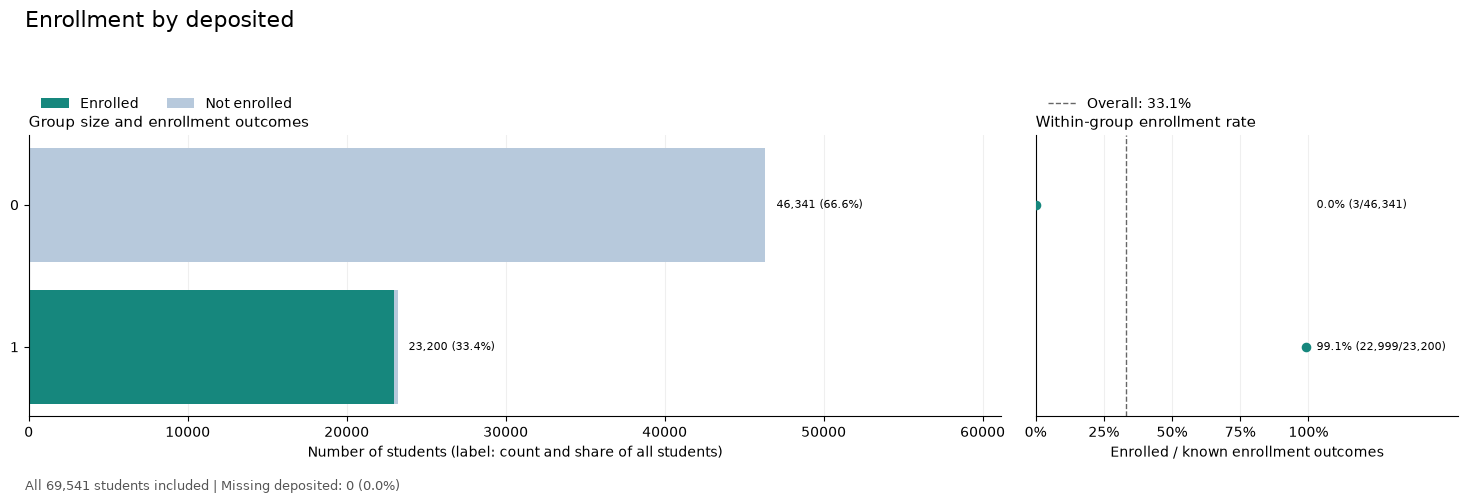

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
0,3,46338,0,46341,0.006474
1,22999,201,0,23200,99.133621


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\deposited.png


In [31]:
summary, saved_plot = plot_column(dataset, 'deposited')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `undecided`


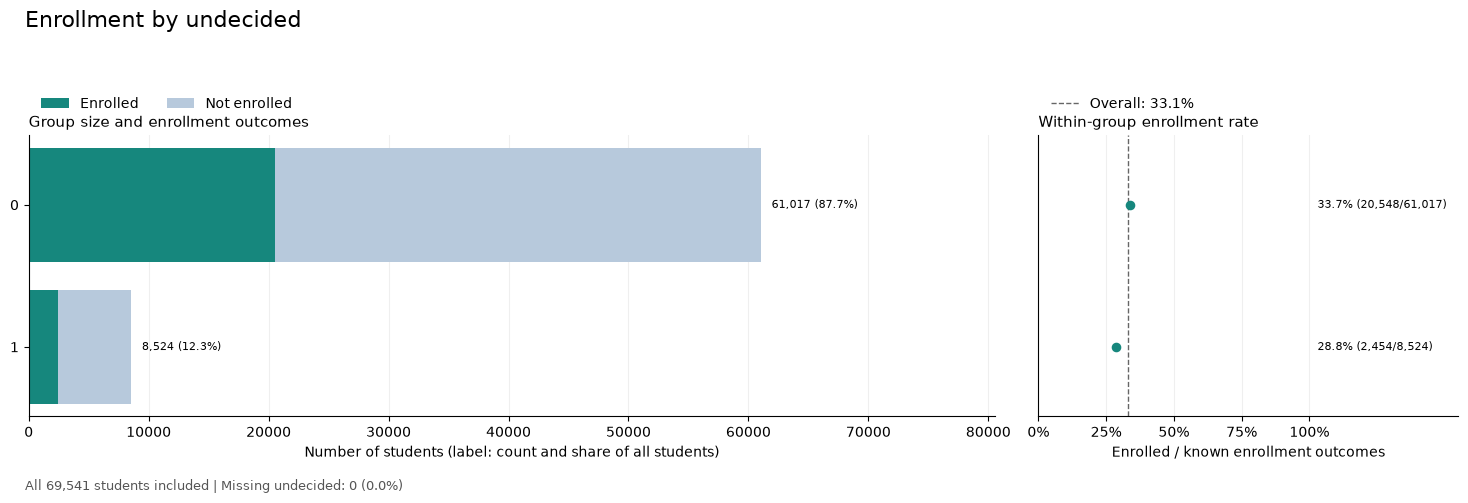

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
0,20548,40469,0,61017,33.675861
1,2454,6070,0,8524,28.789301


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\undecided.png


In [32]:
summary, saved_plot = plot_column(dataset, 'undecided')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `hs_rank`


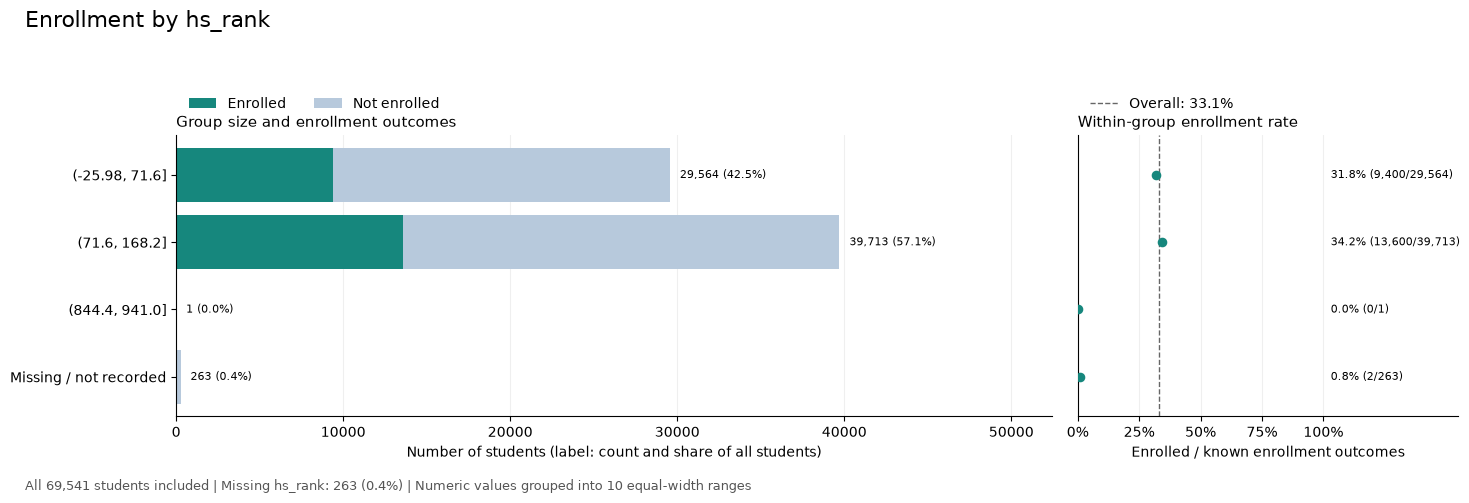

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
"(-25.98, 71.6]",9400,20164,0,29564,31.795427
"(71.6, 168.2]",13600,26113,0,39713,34.245713
"(844.4, 941.0]",0,1,0,1,0.000000
Missing / not recorded,2,261,0,263,0.760456


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\hs_rank.png


In [33]:
summary, saved_plot = plot_column(dataset, 'hs_rank')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `first_generation`


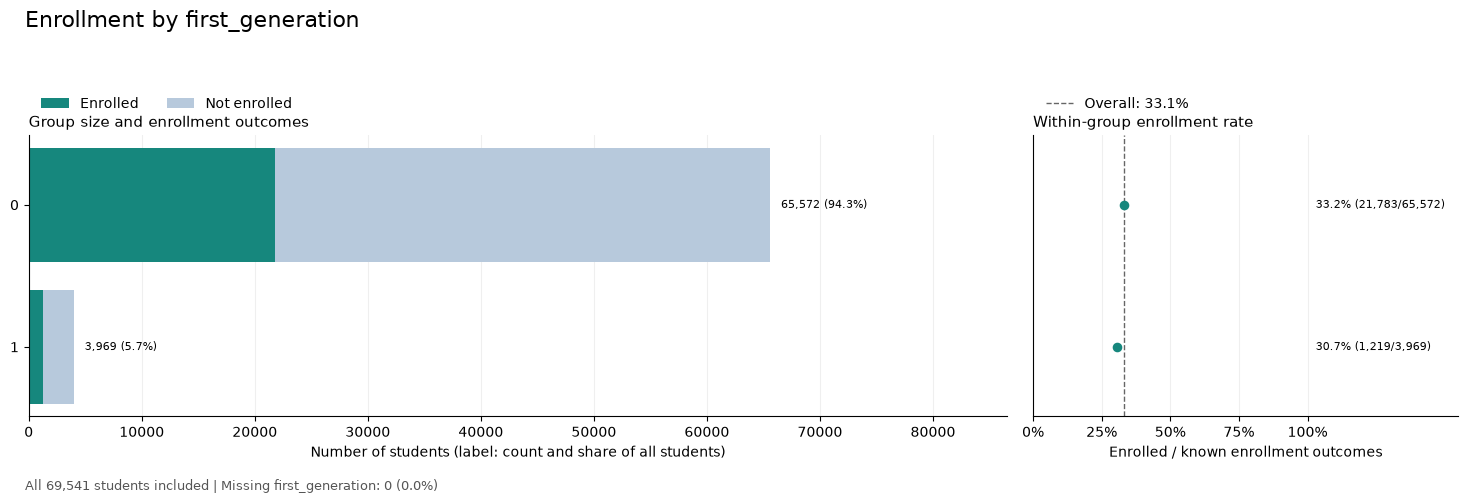

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
0,21783,43789,0,65572,33.219972
1,1219,2750,0,3969,30.713026


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\first_generation.png


In [34]:
summary, saved_plot = plot_column(dataset, 'first_generation')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `legacy`


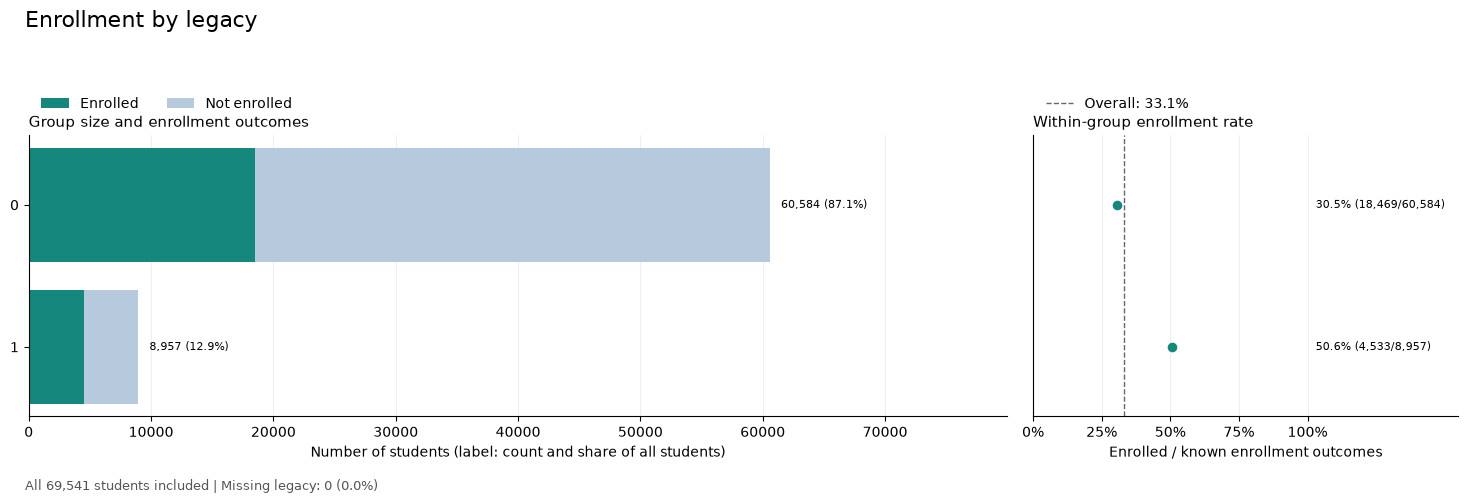

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
0,18469,42115,0,60584,30.484947
1,4533,4424,0,8957,50.608463


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\legacy.png


In [35]:
summary, saved_plot = plot_column(dataset, 'legacy')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `campus_visit_tot`


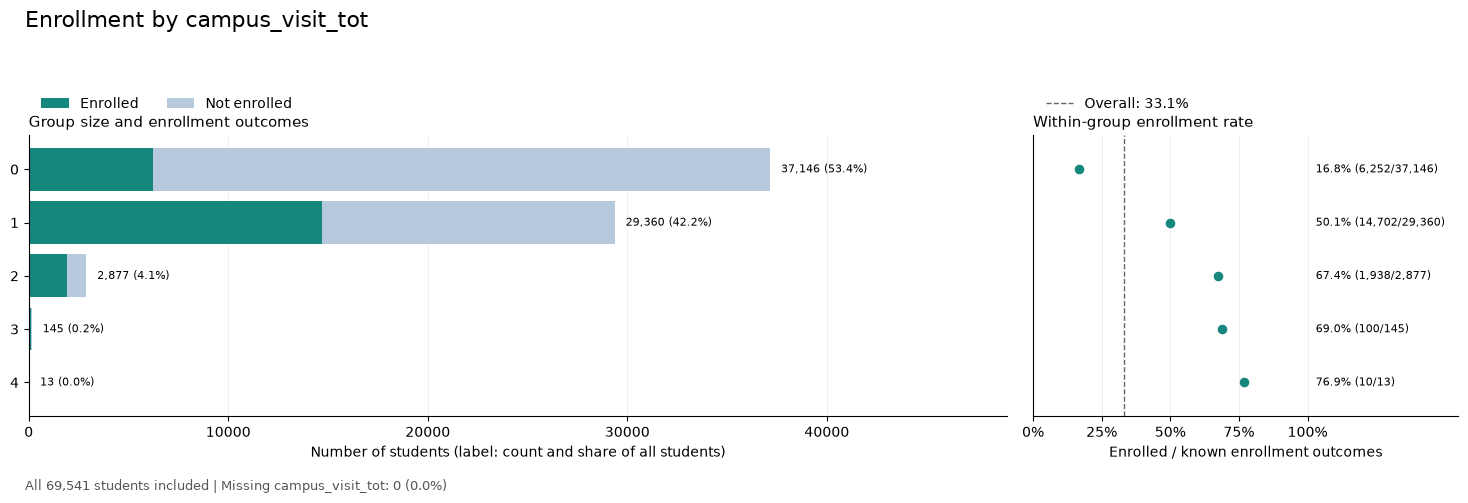

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
0,6252,30894,0,37146,16.830884
1,14702,14658,0,29360,50.074932
2,1938,939,0,2877,67.361835
3,100,45,0,145,68.965517
4,10,3,0,13,76.923077


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\campus_visit_tot.png


In [36]:
summary, saved_plot = plot_column(dataset, 'campus_visit_tot')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `visit_dt`


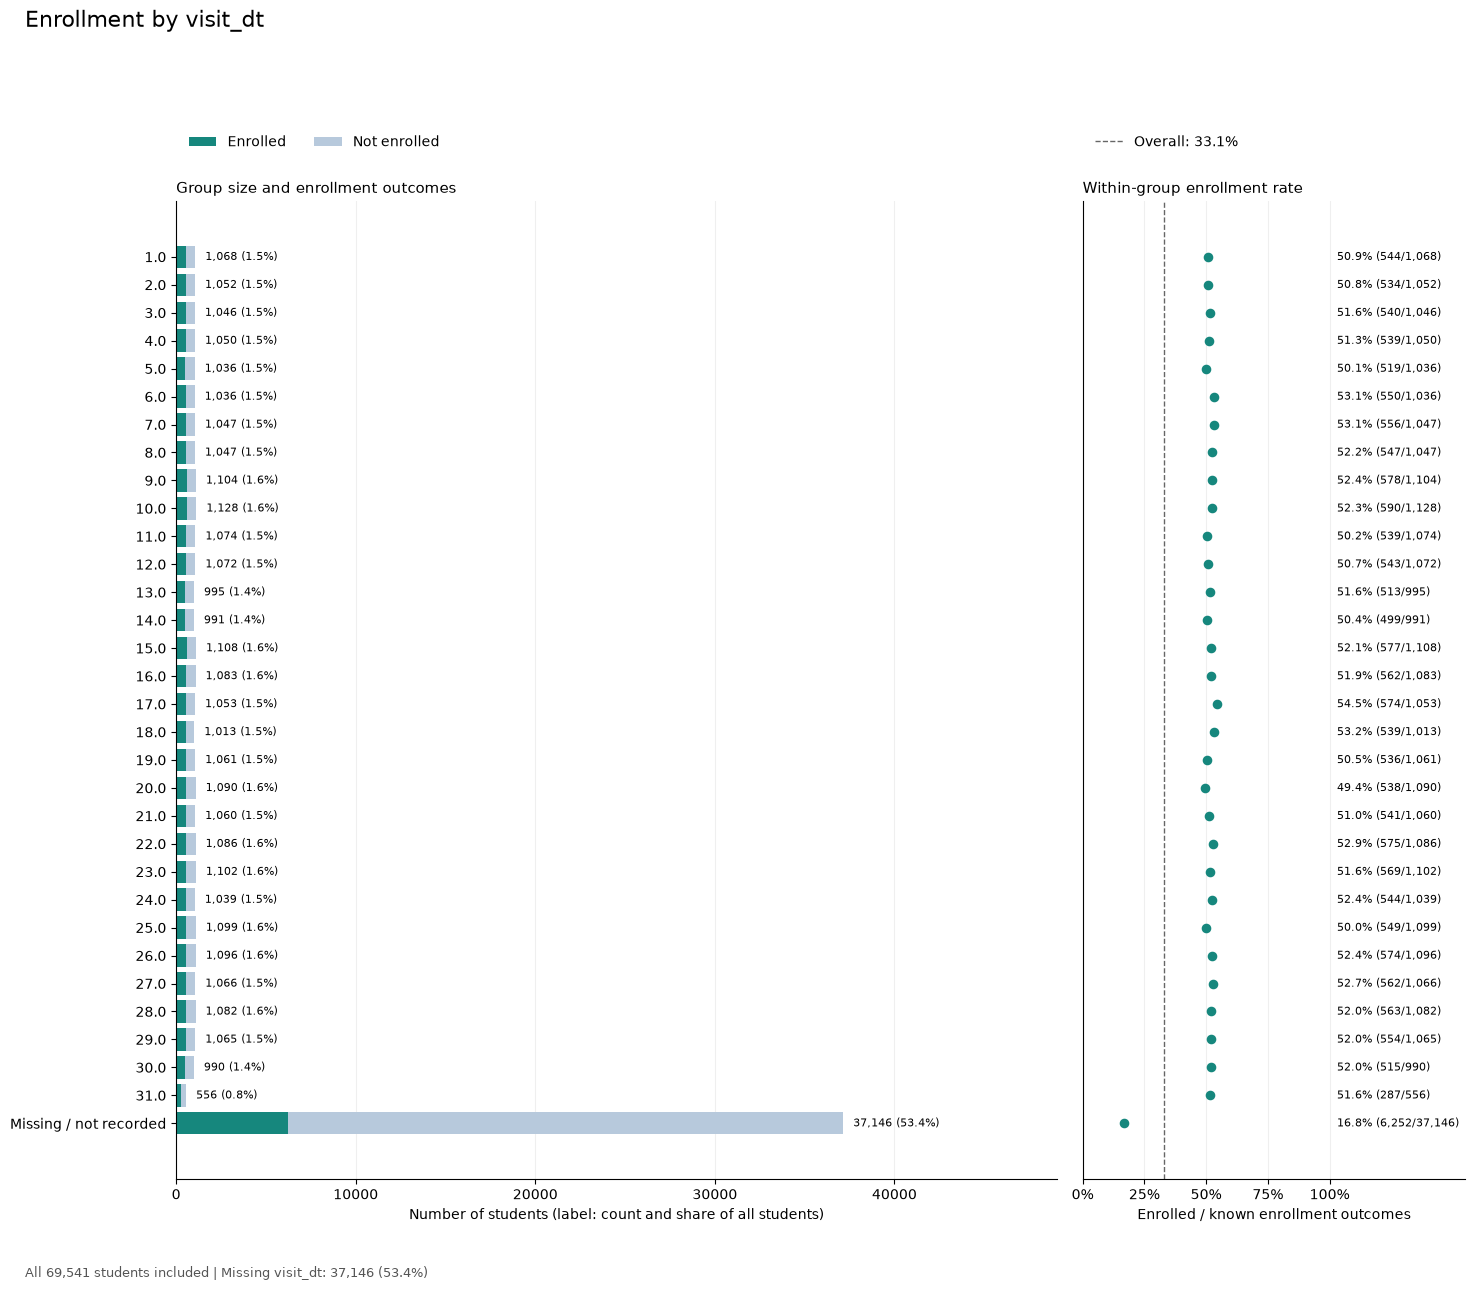

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
1.0,544,524,0,1068,50.936330
2.0,534,518,0,1052,50.760456
3.0,540,506,0,1046,51.625239
4.0,539,511,0,1050,51.333333
5.0,519,517,0,1036,50.096525
6.0,550,486,0,1036,53.088803
7.0,556,491,0,1047,53.104107
8.0,547,500,0,1047,52.244508
9.0,578,526,0,1104,52.355072


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\visit_dt.png


In [37]:
summary, saved_plot = plot_column(dataset, 'visit_dt')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `visit_mo`


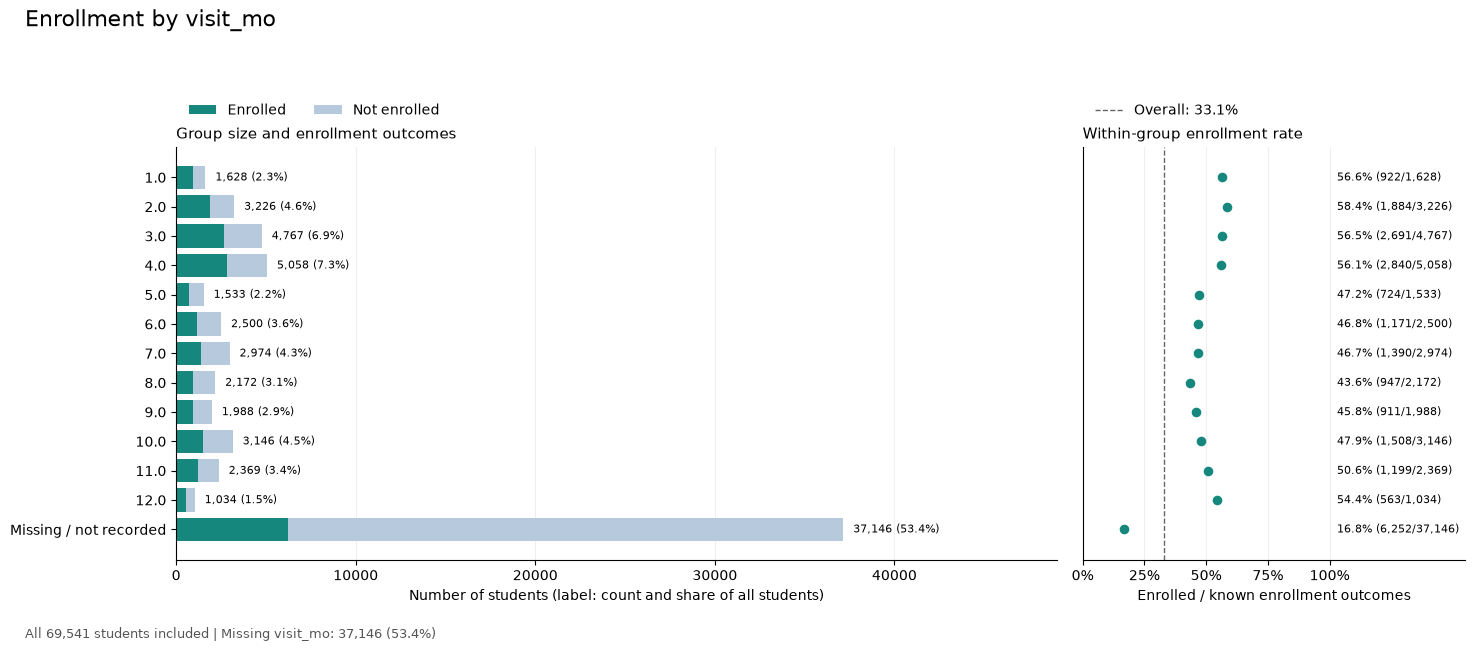

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
1.0,922,706,0,1628,56.633907
2.0,1884,1342,0,3226,58.400496
3.0,2691,2076,0,4767,56.450598
4.0,2840,2218,0,5058,56.148675
5.0,724,809,0,1533,47.227658
6.0,1171,1329,0,2500,46.840000
7.0,1390,1584,0,2974,46.738399
8.0,947,1225,0,2172,43.600368
9.0,911,1077,0,1988,45.824950


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\visit_mo.png


In [38]:
summary, saved_plot = plot_column(dataset, 'visit_mo')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `visit_yr`


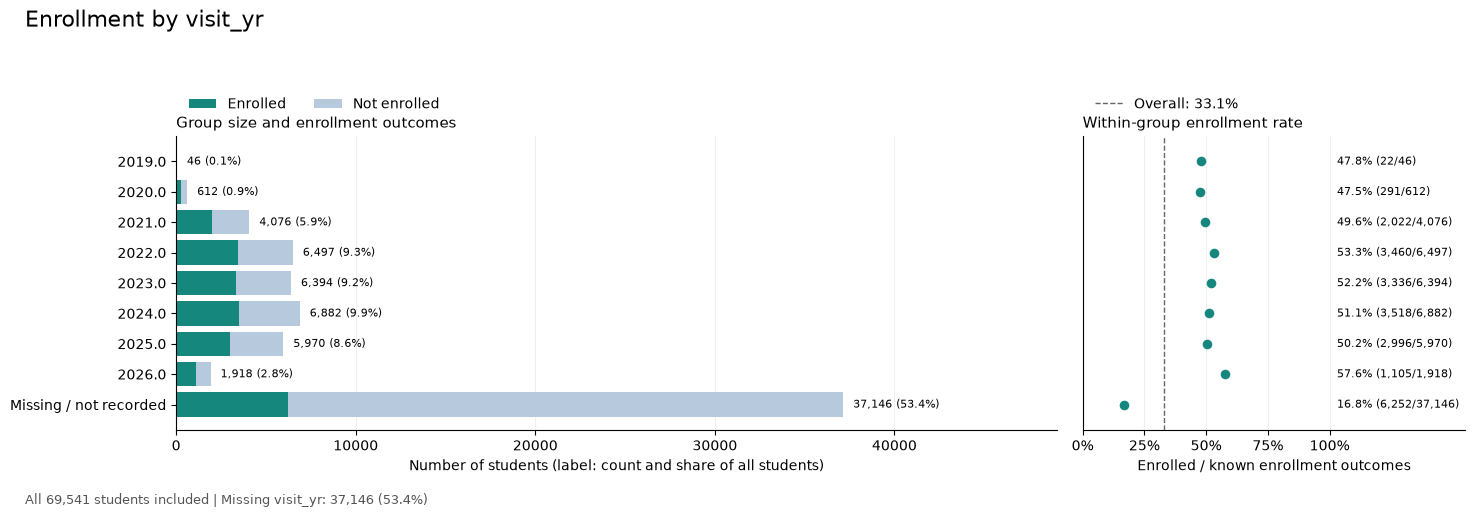

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
2019.0,22,24,0,46,47.826087
2020.0,291,321,0,612,47.549020
2021.0,2022,2054,0,4076,49.607458
2022.0,3460,3037,0,6497,53.255349
2023.0,3336,3058,0,6394,52.173913
2024.0,3518,3364,0,6882,51.118861
2025.0,2996,2974,0,5970,50.184255
2026.0,1105,813,0,1918,57.612096
Missing / not recorded,6252,30894,0,37146,16.830884


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\visit_yr.png


In [39]:
summary, saved_plot = plot_column(dataset, 'visit_yr')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `first_contact_dt`


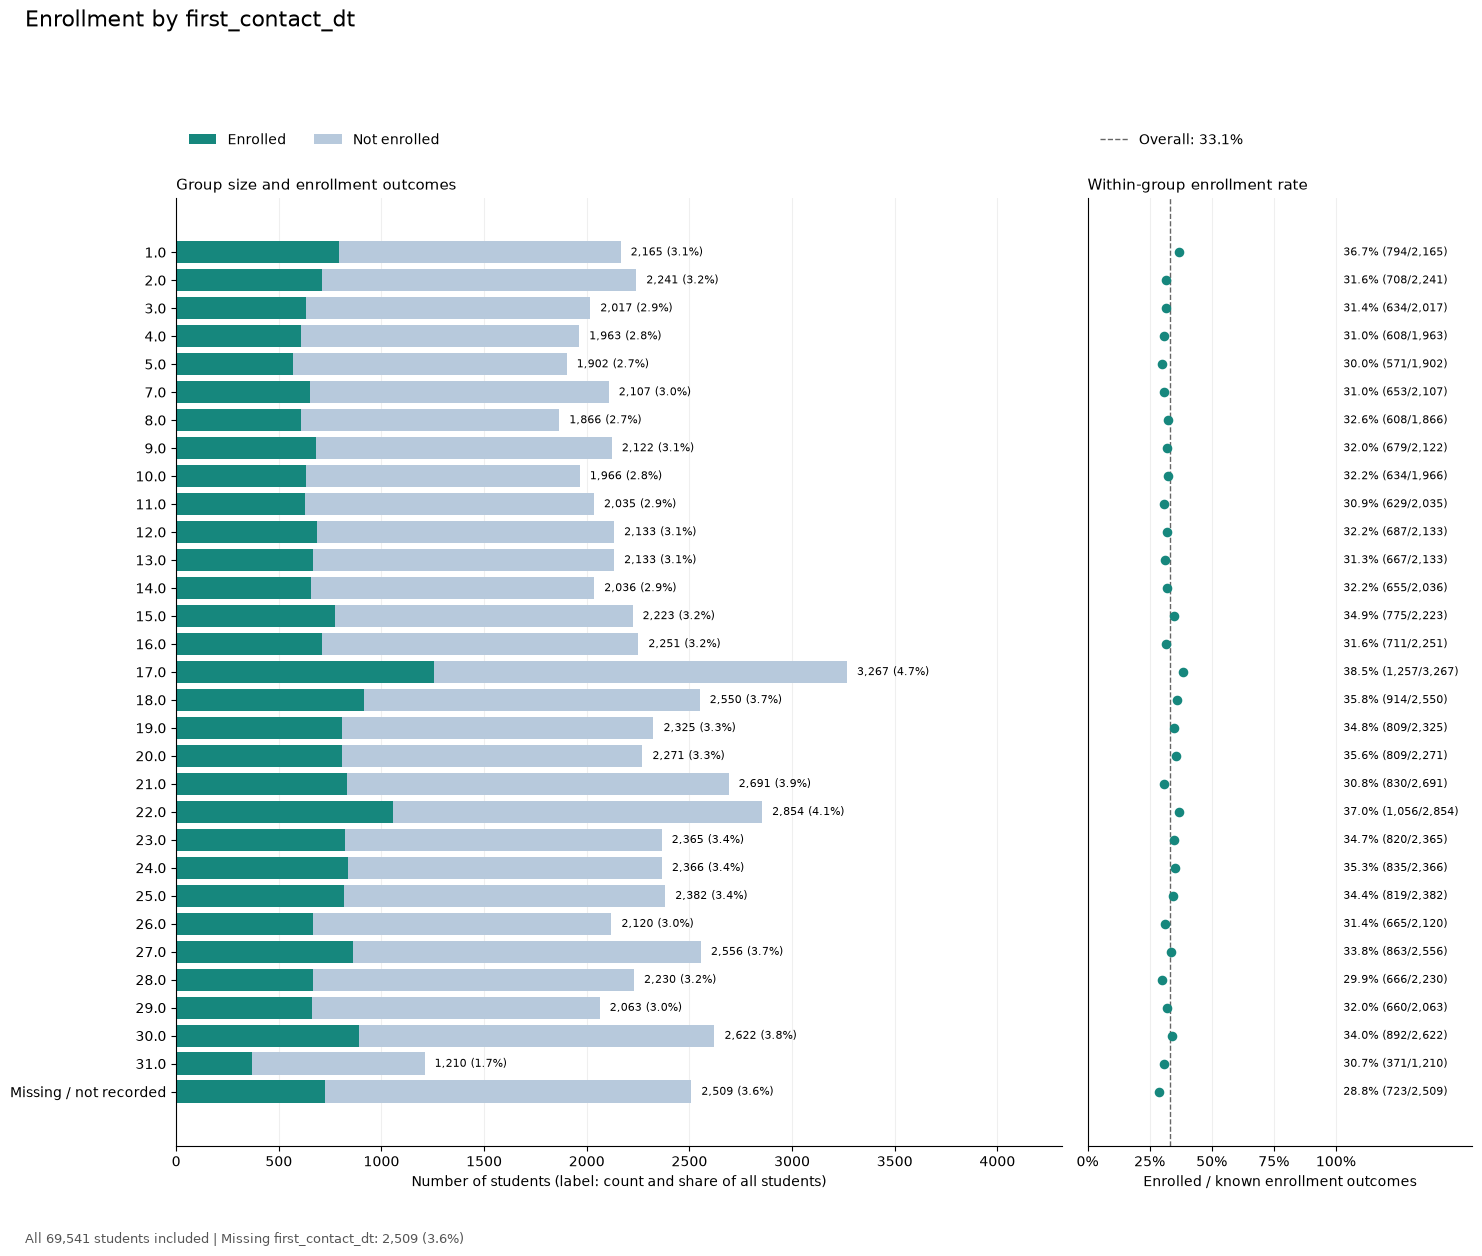

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
1.0,794,1371,0,2165,36.674365
2.0,708,1533,0,2241,31.593039
3.0,634,1383,0,2017,31.432821
4.0,608,1355,0,1963,30.973001
5.0,571,1331,0,1902,30.021030
7.0,653,1454,0,2107,30.991932
8.0,608,1258,0,1866,32.583065
9.0,679,1443,0,2122,31.998115
10.0,634,1332,0,1966,32.248220


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\first_contact_dt.png


In [40]:
summary, saved_plot = plot_column(dataset, 'first_contact_dt')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `first_contact_mo`


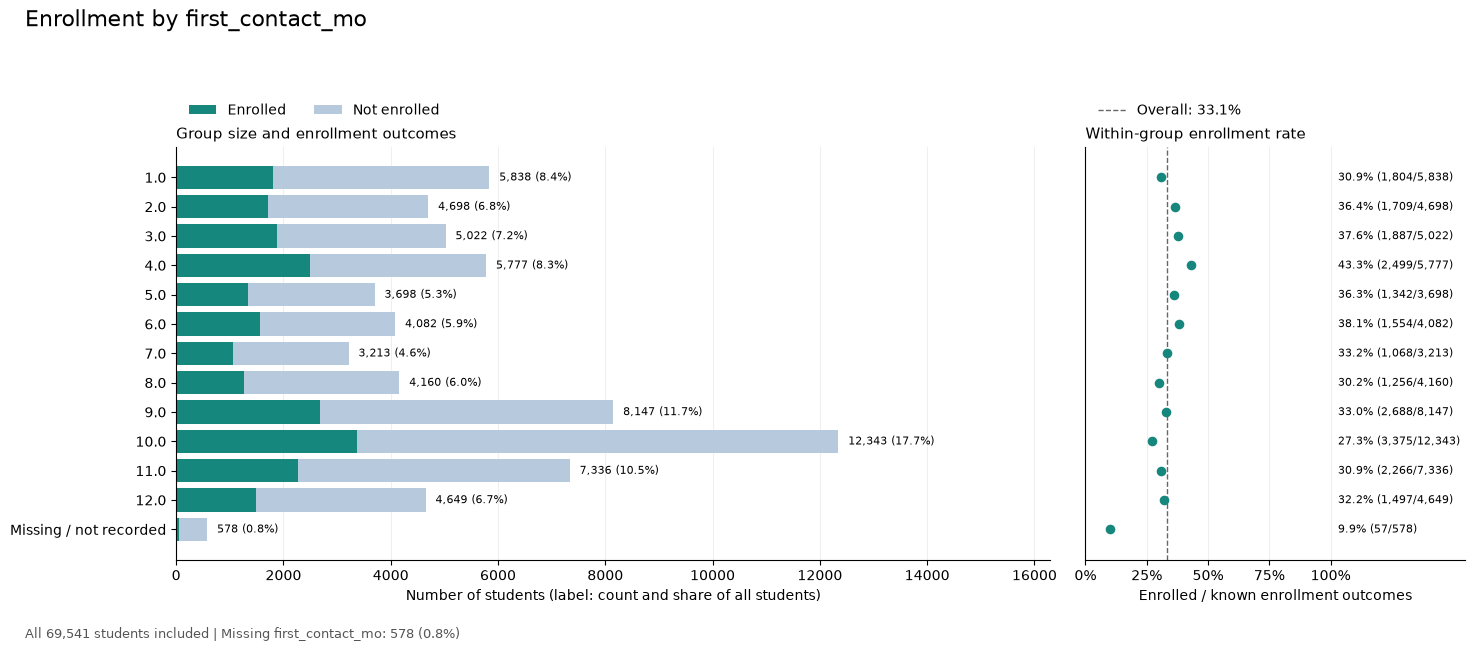

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
1.0,1804,4034,0,5838,30.900993
2.0,1709,2989,0,4698,36.377182
3.0,1887,3135,0,5022,37.574671
4.0,2499,3278,0,5777,43.257746
5.0,1342,2356,0,3698,36.289886
6.0,1554,2528,0,4082,38.069574
7.0,1068,2145,0,3213,33.239963
8.0,1256,2904,0,4160,30.192308
9.0,2688,5459,0,8147,32.993740


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\first_contact_mo.png


In [41]:
summary, saved_plot = plot_column(dataset, 'first_contact_mo')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `first_contact_yr`


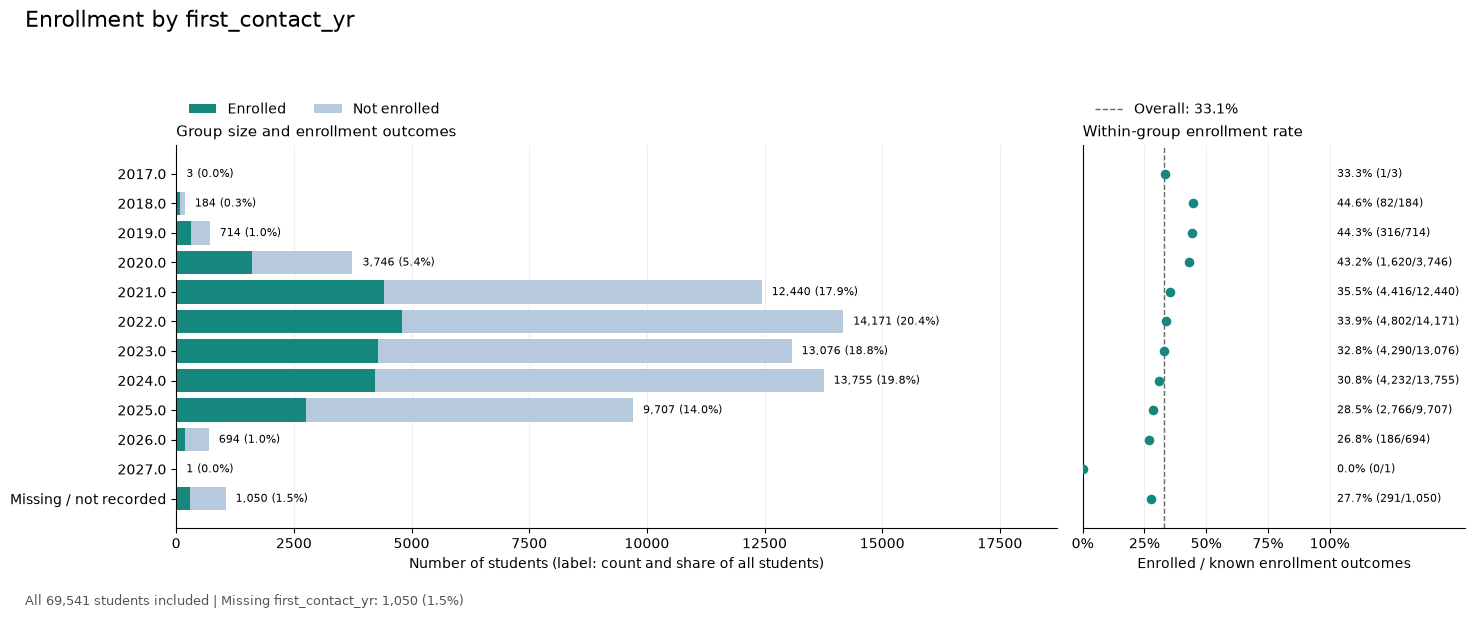

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
2017.0,1,2,0,3,33.333333
2018.0,82,102,0,184,44.565217
2019.0,316,398,0,714,44.257703
2020.0,1620,2126,0,3746,43.246129
2021.0,4416,8024,0,12440,35.498392
2022.0,4802,9369,0,14171,33.886105
2023.0,4290,8786,0,13076,32.808198
2024.0,4232,9523,0,13755,30.766994
2025.0,2766,6941,0,9707,28.494901


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\first_contact_yr.png


In [42]:
summary, saved_plot = plot_column(dataset, 'first_contact_yr')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `stealth`


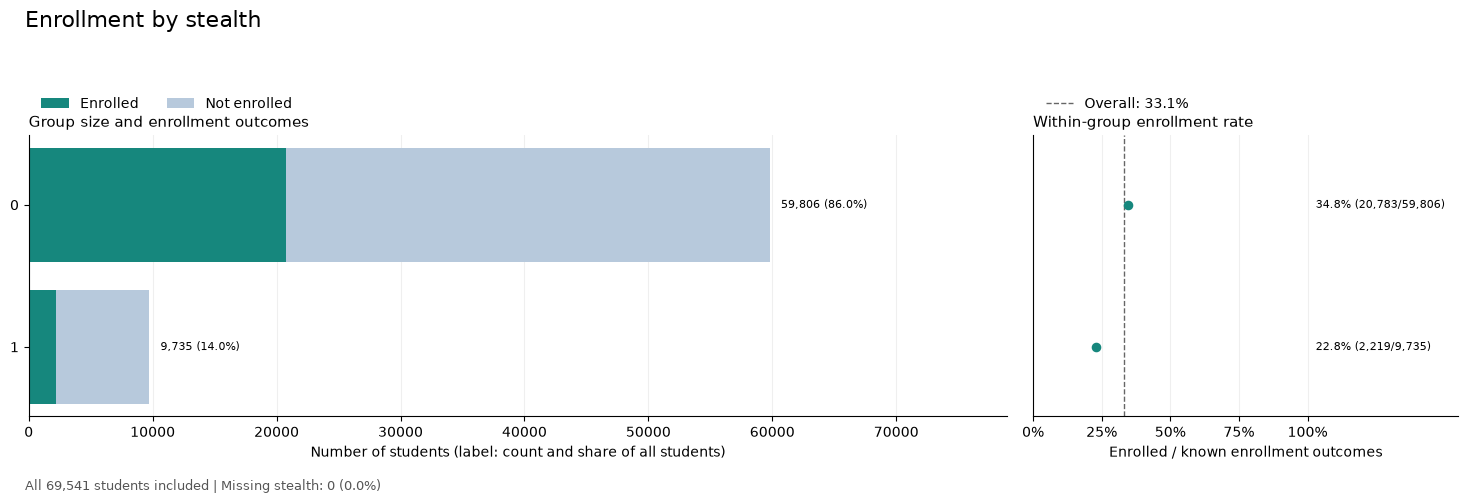

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
0,20783,39023,0,59806,34.750694
1,2219,7516,0,9735,22.794042


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\stealth.png


In [43]:
summary, saved_plot = plot_column(dataset, 'stealth')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `grad_expct`


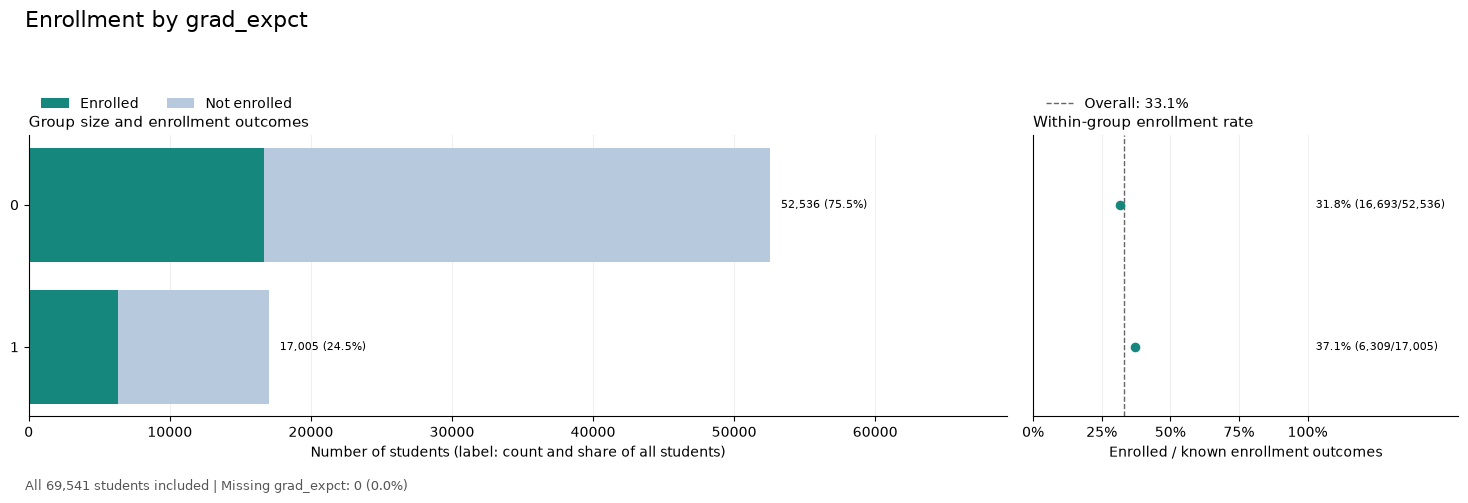

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
0,16693,35843,0,52536,31.774402
1,6309,10696,0,17005,37.100853


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\grad_expct.png


In [44]:
summary, saved_plot = plot_column(dataset, 'grad_expct')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `ed_plan_asst`


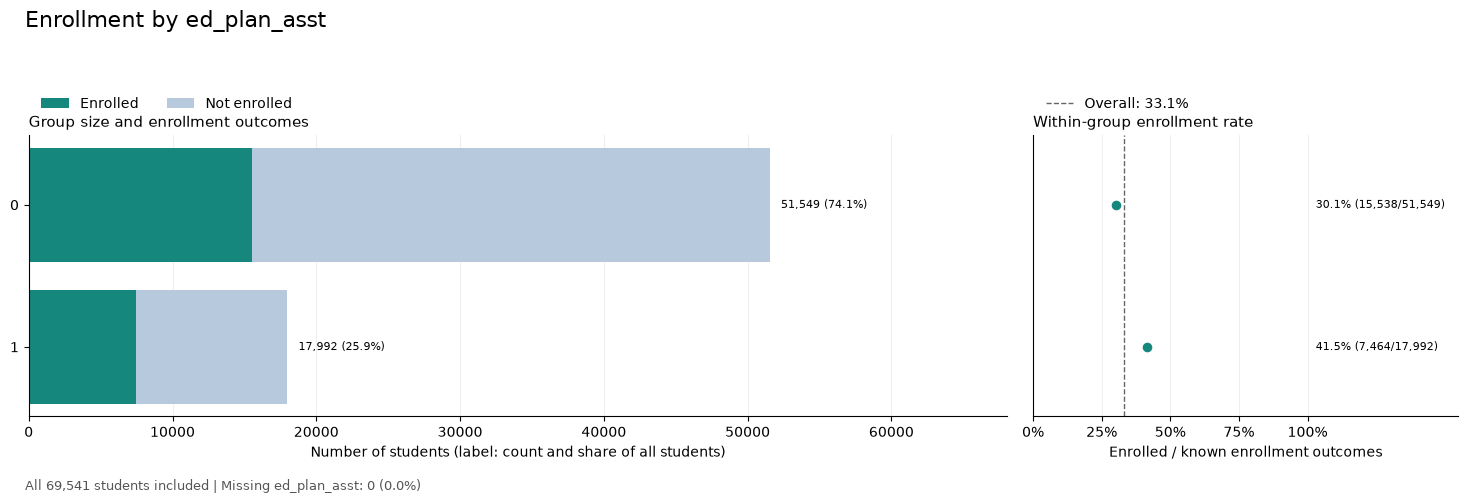

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
0,15538,36011,0,51549,30.142195
1,7464,10528,0,17992,41.485104


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\ed_plan_asst.png


In [45]:
summary, saved_plot = plot_column(dataset, 'ed_plan_asst')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `wrtng_asst`


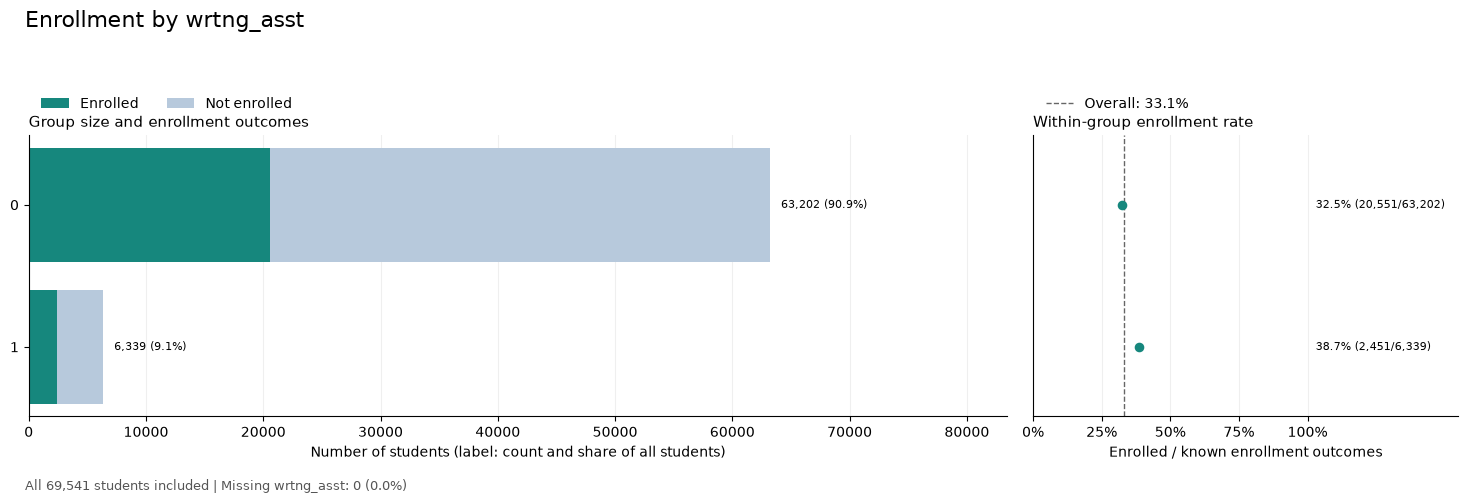

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
0,20551,42651,0,63202,32.516376
1,2451,3888,0,6339,38.665405


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\wrtng_asst.png


In [46]:
summary, saved_plot = plot_column(dataset, 'wrtng_asst')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `read_asst`


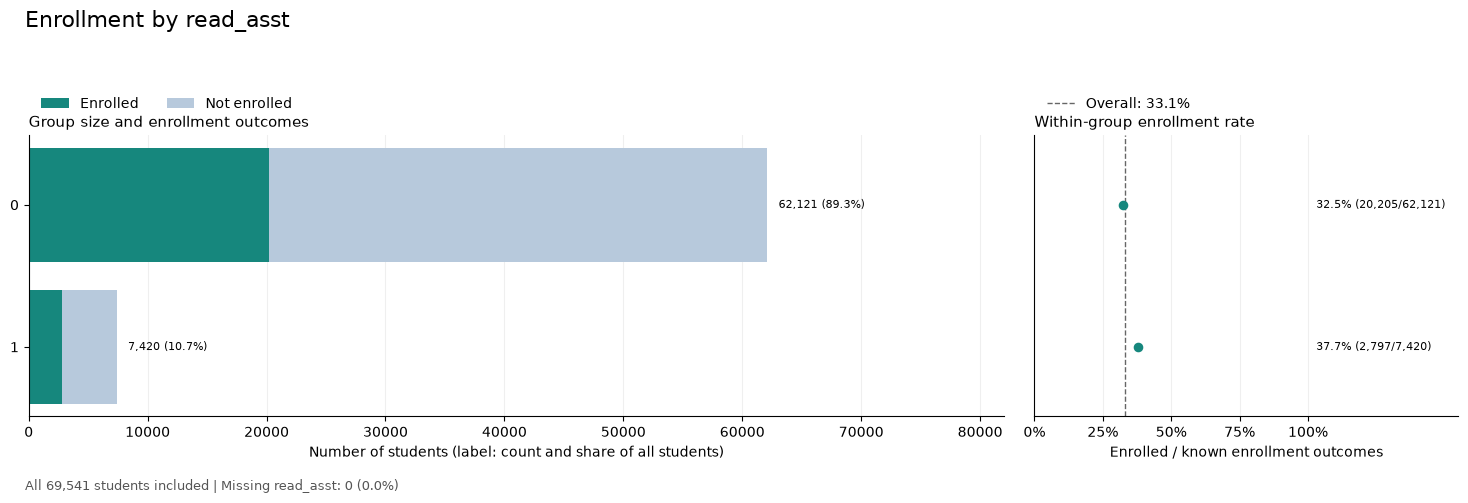

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
0,20205,41916,0,62121,32.525233
1,2797,4623,0,7420,37.695418


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\read_asst.png


In [47]:
summary, saved_plot = plot_column(dataset, 'read_asst')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `study_skll_asst`


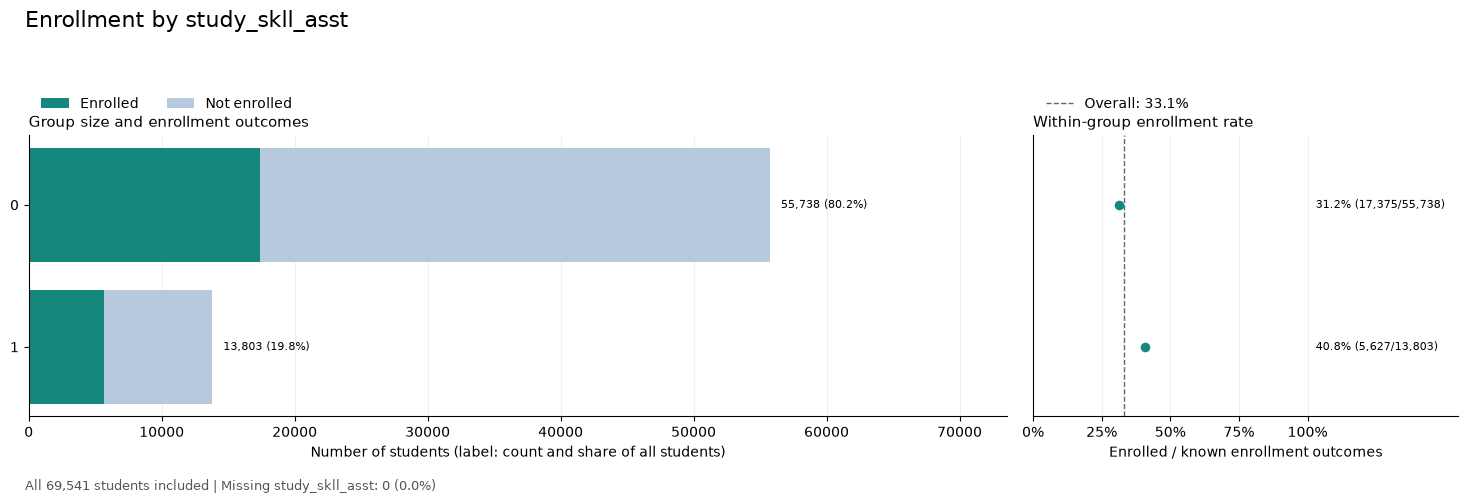

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
0,17375,38363,0,55738,31.172629
1,5627,8176,0,13803,40.766500


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\study_skll_asst.png


In [48]:
summary, saved_plot = plot_column(dataset, 'study_skll_asst')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `math_asst`


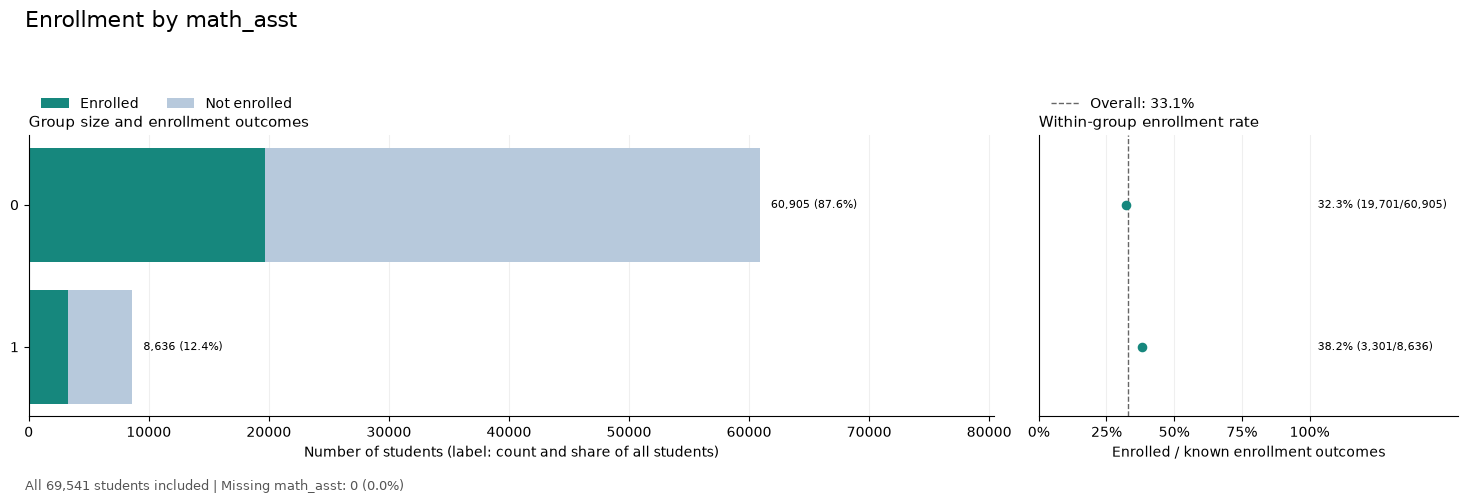

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
0,19701,41204,0,60905,32.347098
1,3301,5335,0,8636,38.223715


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\math_asst.png


In [49]:
summary, saved_plot = plot_column(dataset, 'math_asst')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `hs_algbr_cr`


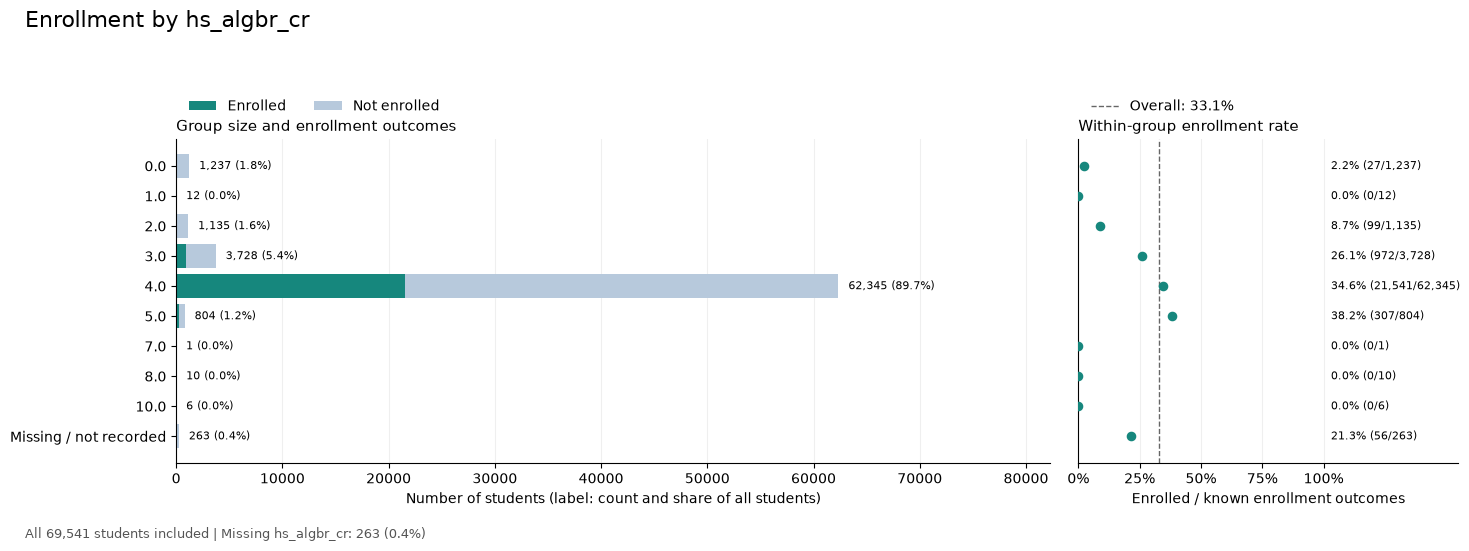

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
0.0,27,1210,0,1237,2.182700
1.0,0,12,0,12,0.000000
2.0,99,1036,0,1135,8.722467
3.0,972,2756,0,3728,26.072961
4.0,21541,40804,0,62345,34.551287
5.0,307,497,0,804,38.184080
7.0,0,1,0,1,0.000000
8.0,0,10,0,10,0.000000
10.0,0,6,0,6,0.000000


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\hs_algbr_cr.png


In [50]:
summary, saved_plot = plot_column(dataset, 'hs_algbr_cr')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `hs_geom_cr`


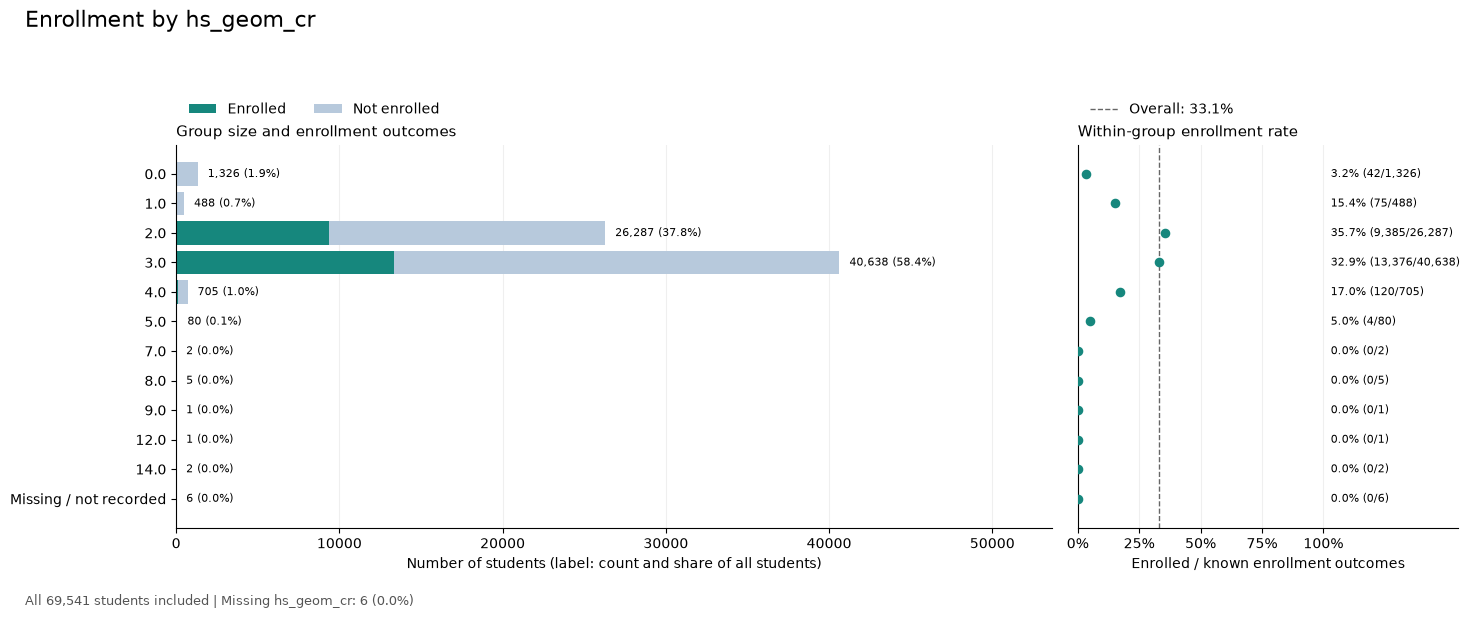

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
0.0,42,1284,0,1326,3.167421
1.0,75,413,0,488,15.368852
2.0,9385,16902,0,26287,35.702058
3.0,13376,27262,0,40638,32.915006
4.0,120,585,0,705,17.021277
5.0,4,76,0,80,5.000000
7.0,0,2,0,2,0.000000
8.0,0,5,0,5,0.000000
9.0,0,1,0,1,0.000000


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\hs_geom_cr.png


In [51]:
summary, saved_plot = plot_column(dataset, 'hs_geom_cr')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `hs_trig_cr`


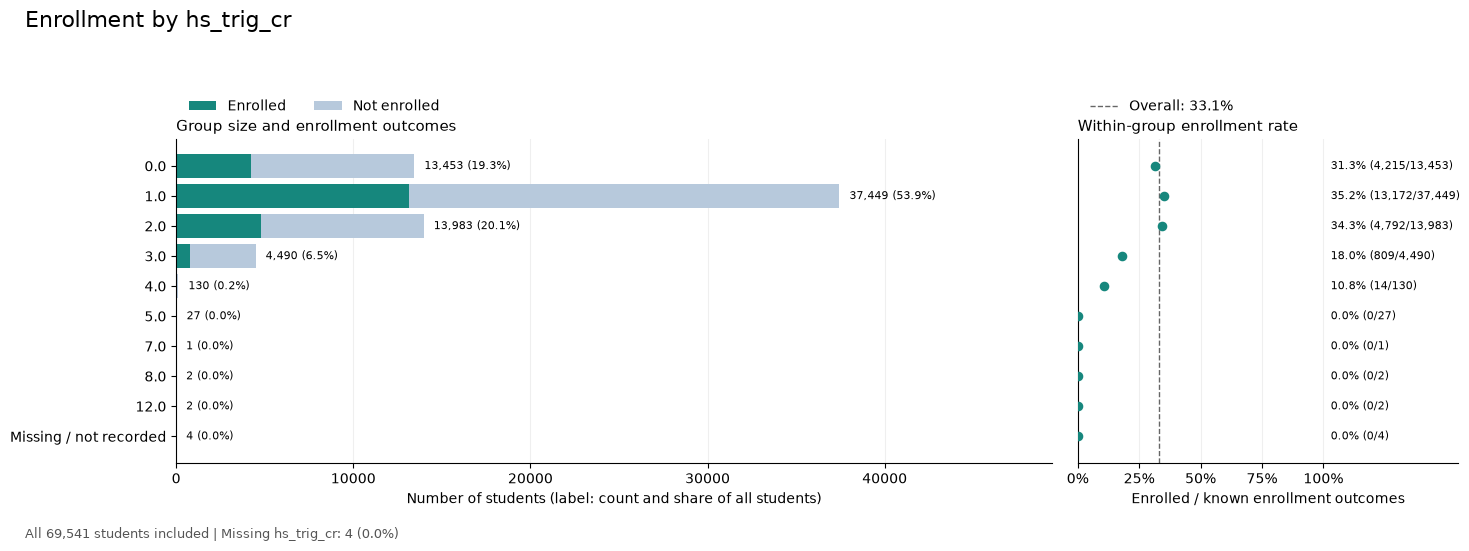

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
0.0,4215,9238,0,13453,31.331302
1.0,13172,24277,0,37449,35.173169
2.0,4792,9191,0,13983,34.270185
3.0,809,3681,0,4490,18.017817
4.0,14,116,0,130,10.769231
5.0,0,27,0,27,0.000000
7.0,0,1,0,1,0.000000
8.0,0,2,0,2,0.000000
12.0,0,2,0,2,0.000000


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\hs_trig_cr.png


In [52]:
summary, saved_plot = plot_column(dataset, 'hs_trig_cr')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `hs_calc_cr`


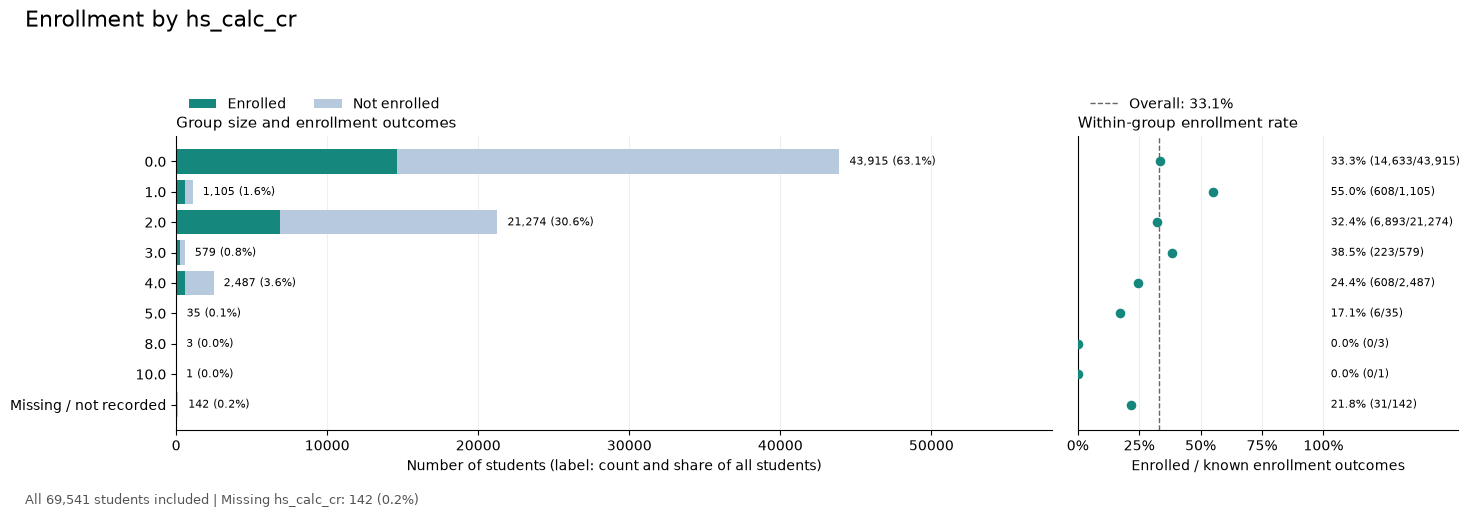

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
0.0,14633,29282,0,43915,33.321189
1.0,608,497,0,1105,55.022624
2.0,6893,14381,0,21274,32.401053
3.0,223,356,0,579,38.514680
4.0,608,1879,0,2487,24.447125
5.0,6,29,0,35,17.142857
8.0,0,3,0,3,0.000000
10.0,0,1,0,1,0.000000
Missing / not recorded,31,111,0,142,21.830986


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\hs_calc_cr.png


In [53]:
summary, saved_plot = plot_column(dataset, 'hs_calc_cr')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `coll_algbr_cr`


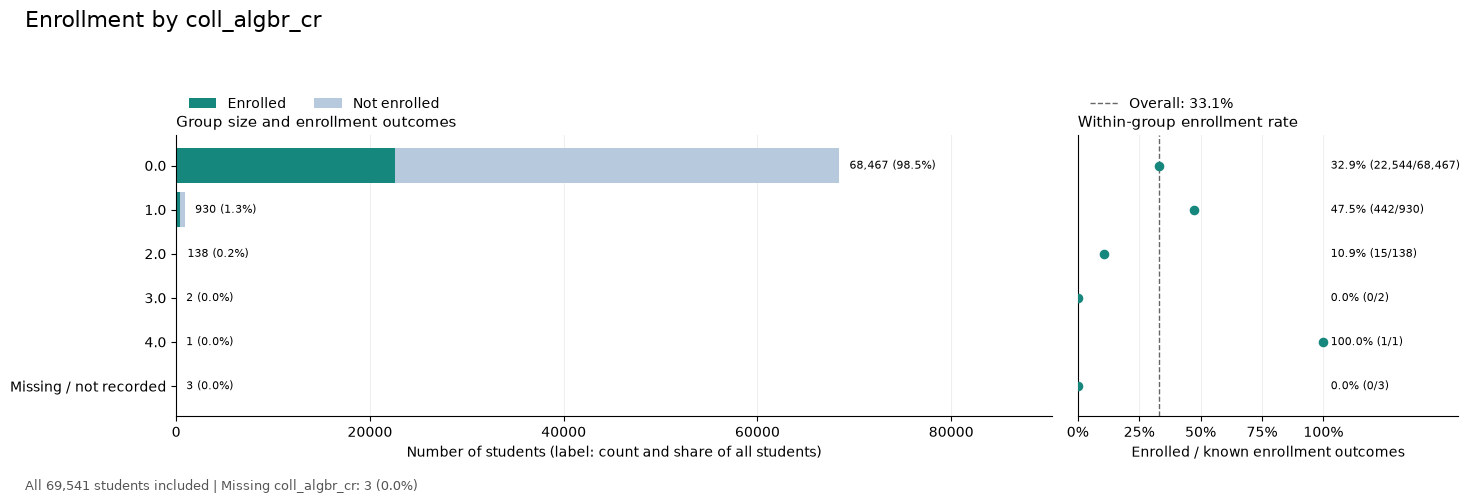

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
0.0,22544,45923,0,68467,32.926811
1.0,442,488,0,930,47.526882
2.0,15,123,0,138,10.869565
3.0,0,2,0,2,0.000000
4.0,1,0,0,1,100.000000
Missing / not recorded,0,3,0,3,0.000000


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\coll_algbr_cr.png


In [54]:
summary, saved_plot = plot_column(dataset, 'coll_algbr_cr')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `coll_geom_cr`


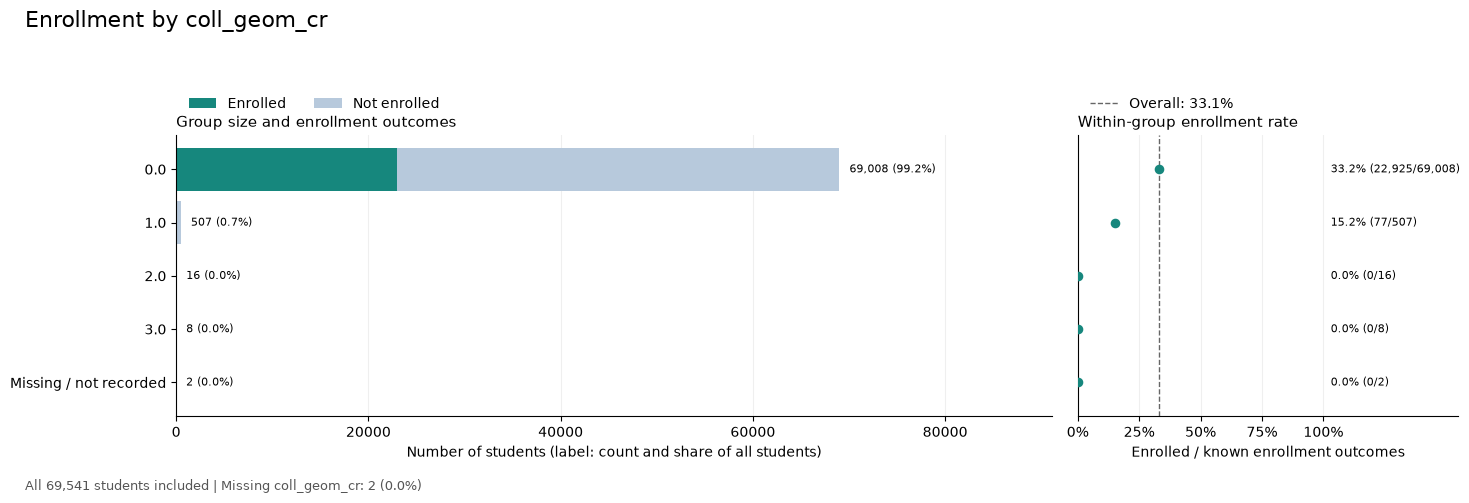

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
0.0,22925,46083,0,69008,33.220786
1.0,77,430,0,507,15.187377
2.0,0,16,0,16,0.000000
3.0,0,8,0,8,0.000000
Missing / not recorded,0,2,0,2,0.000000


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\coll_geom_cr.png


In [55]:
summary, saved_plot = plot_column(dataset, 'coll_geom_cr')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `coll_trig_cr`


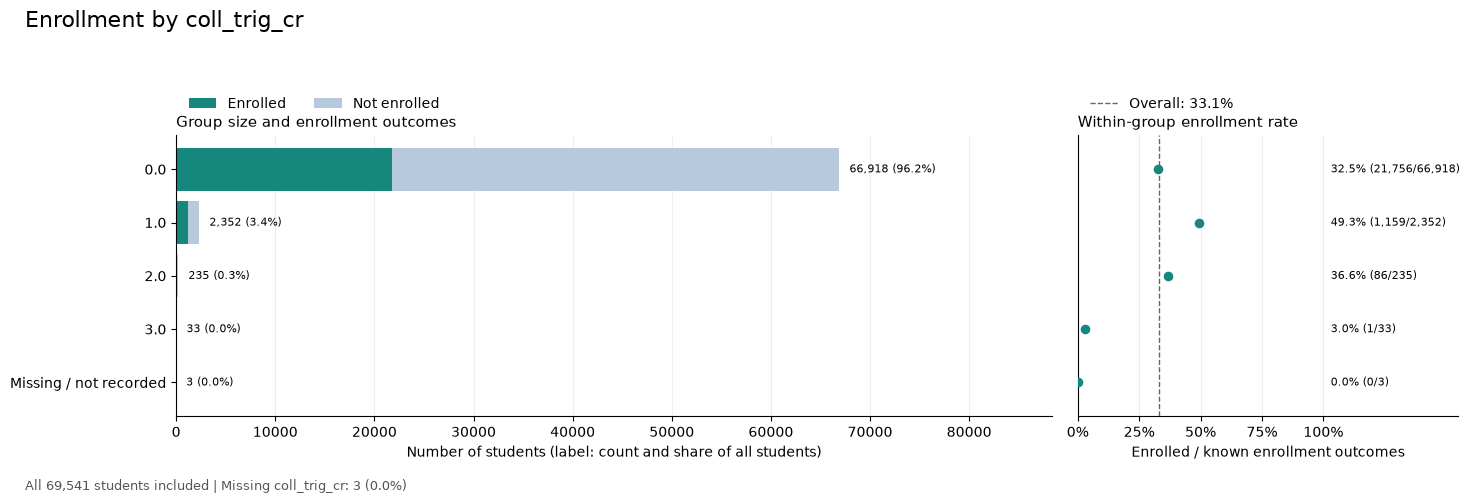

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
0.0,21756,45162,0,66918,32.511432
1.0,1159,1193,0,2352,49.277211
2.0,86,149,0,235,36.595745
3.0,1,32,0,33,3.030303
Missing / not recorded,0,3,0,3,0.000000


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\coll_trig_cr.png


In [56]:
summary, saved_plot = plot_column(dataset, 'coll_trig_cr')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `coll_calc_cr`


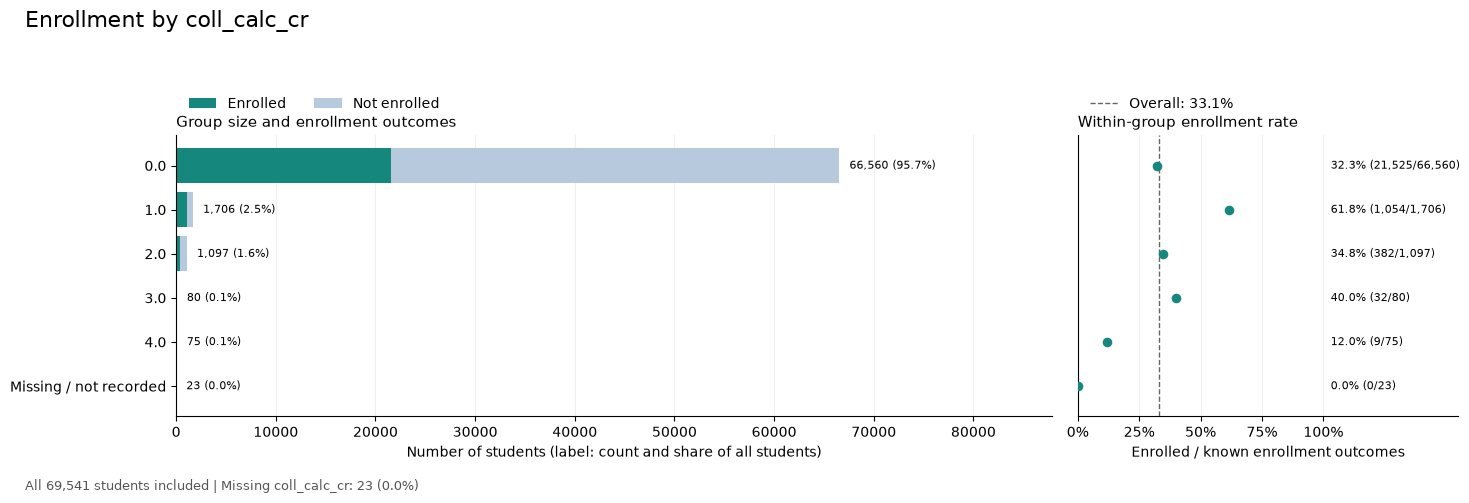

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
0.0,21525,45035,0,66560,32.339243
1.0,1054,652,0,1706,61.781946
2.0,382,715,0,1097,34.822242
3.0,32,48,0,80,40.000000
4.0,9,66,0,75,12.000000
Missing / not recorded,0,23,0,23,0.000000


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\coll_calc_cr.png


In [57]:
summary, saved_plot = plot_column(dataset, 'coll_calc_cr')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `coll_math`


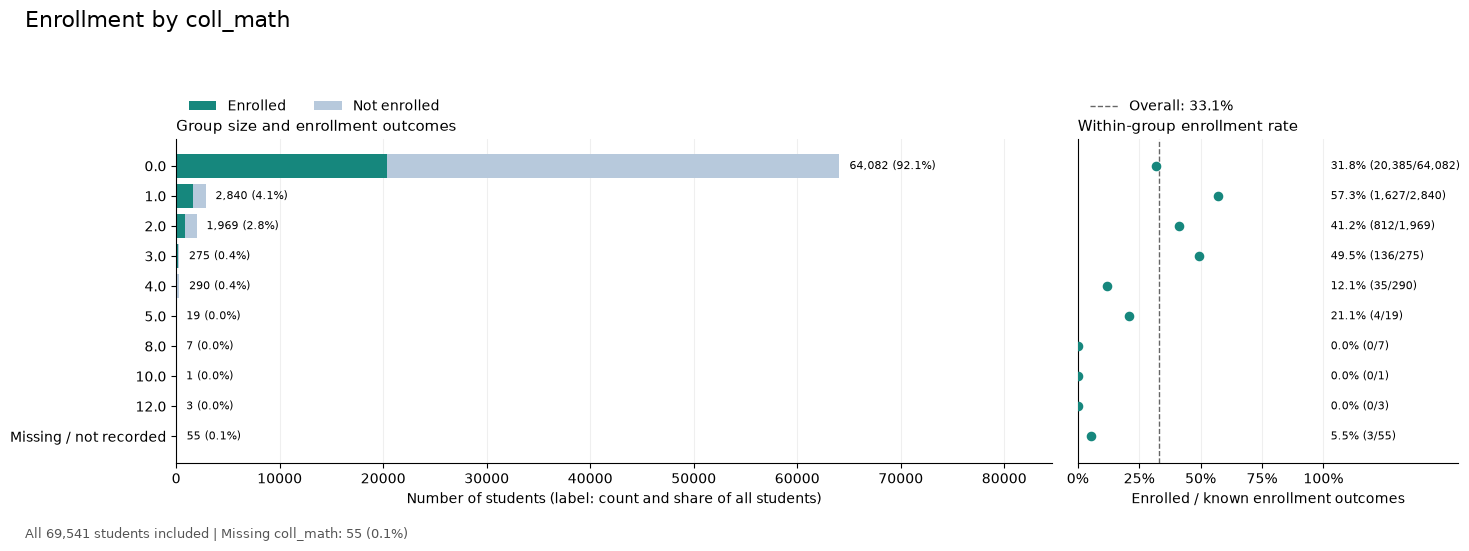

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
0.0,20385,43697,0,64082,31.810805
1.0,1627,1213,0,2840,57.288732
2.0,812,1157,0,1969,41.239208
3.0,136,139,0,275,49.454545
4.0,35,255,0,290,12.068966
5.0,4,15,0,19,21.052632
8.0,0,7,0,7,0.000000
10.0,0,1,0,1,0.000000
12.0,0,3,0,3,0.000000


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\coll_math.png


In [58]:
summary, saved_plot = plot_column(dataset, 'coll_math')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `coll_sci`


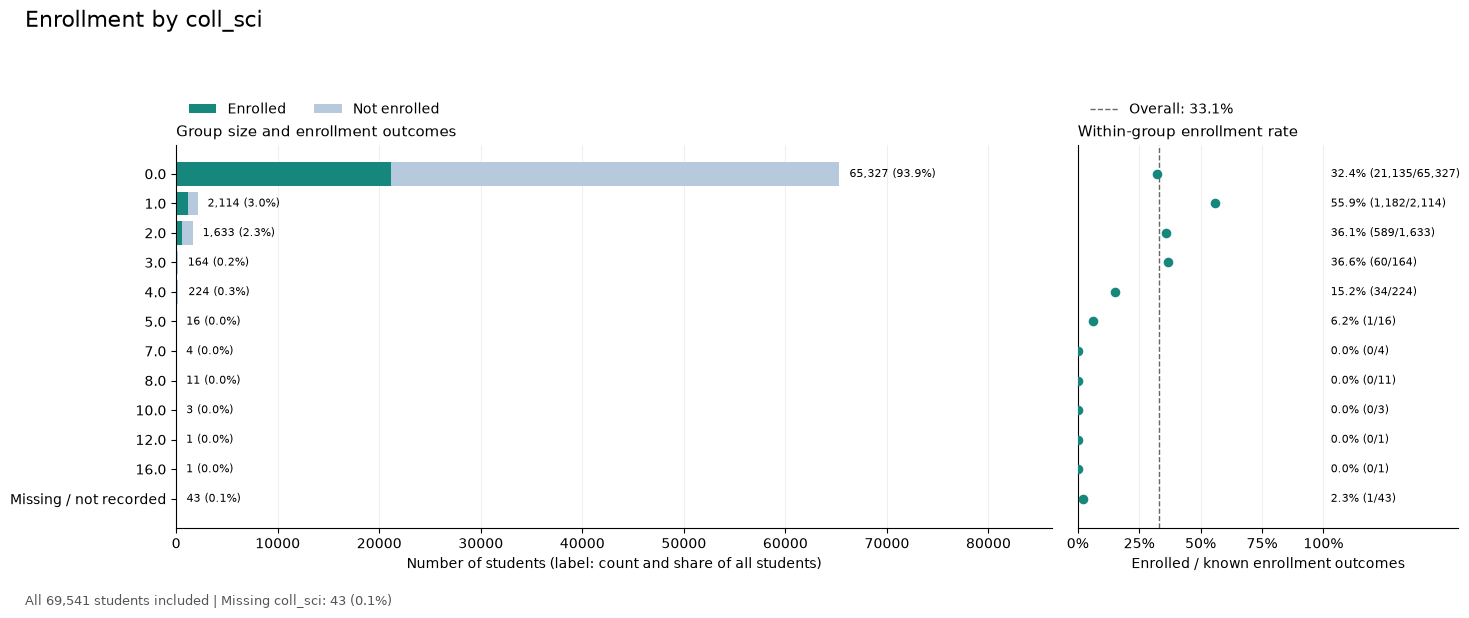

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
0.0,21135,44192,0,65327,32.352626
1.0,1182,932,0,2114,55.912961
2.0,589,1044,0,1633,36.068585
3.0,60,104,0,164,36.585366
4.0,34,190,0,224,15.178571
5.0,1,15,0,16,6.250000
7.0,0,4,0,4,0.000000
8.0,0,11,0,11,0.000000
10.0,0,3,0,3,0.000000


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\coll_sci.png


In [59]:
summary, saved_plot = plot_column(dataset, 'coll_sci')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `hs_only_math`


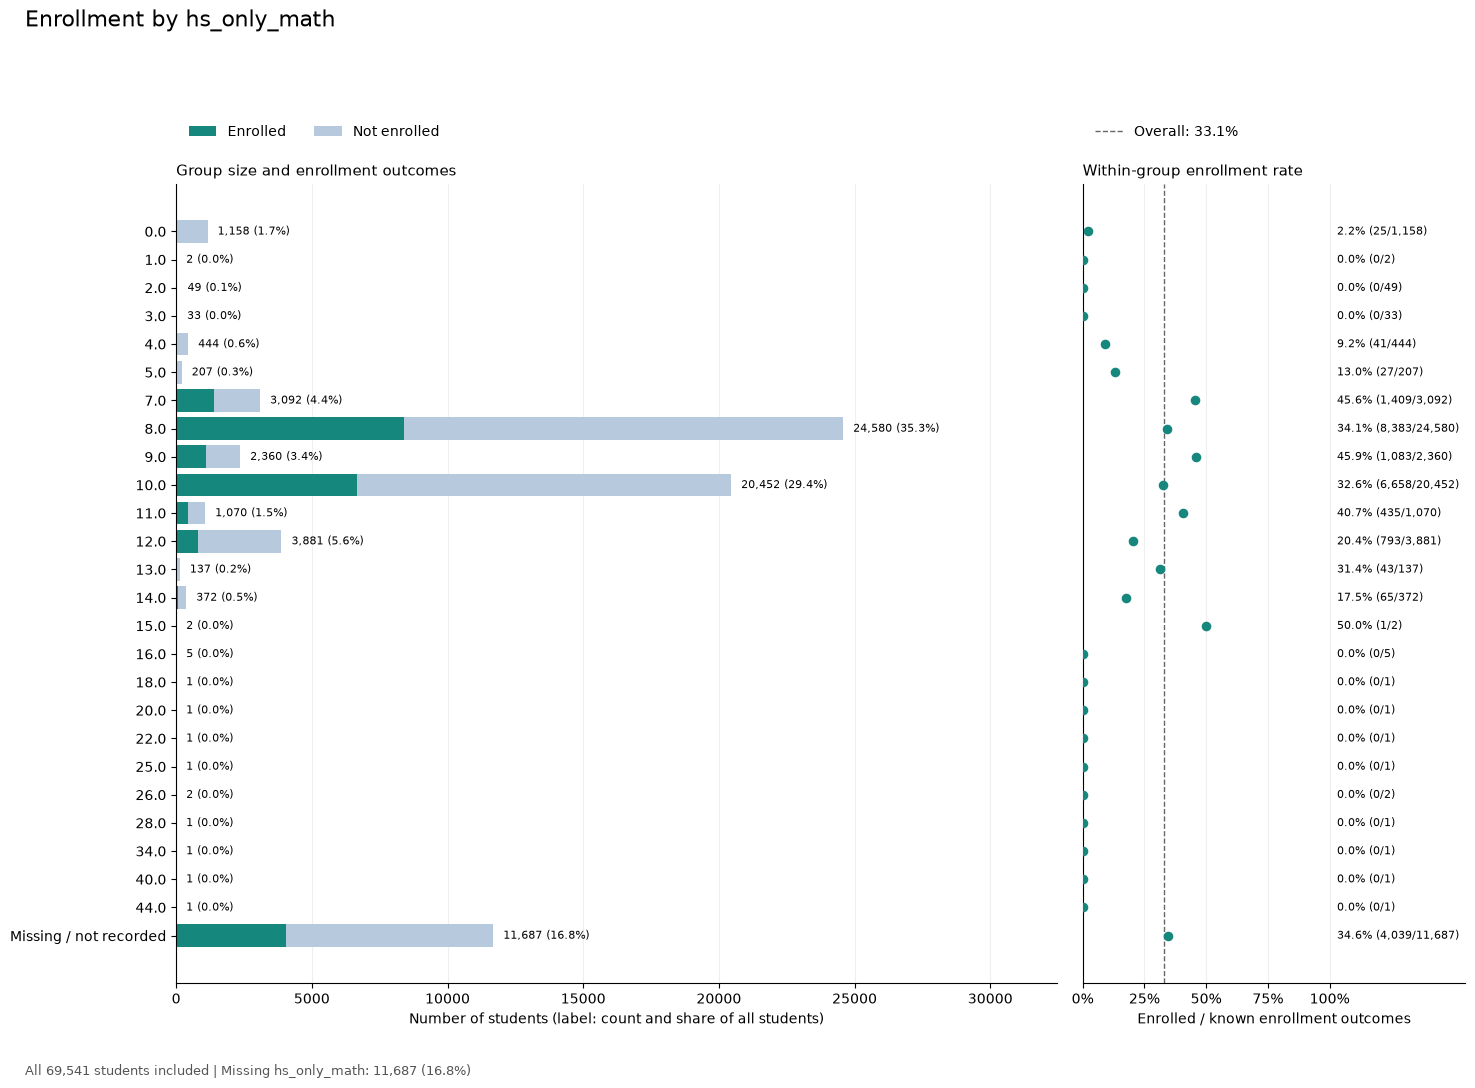

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
0.0,25,1133,0,1158,2.158895
1.0,0,2,0,2,0.000000
2.0,0,49,0,49,0.000000
3.0,0,33,0,33,0.000000
4.0,41,403,0,444,9.234234
5.0,27,180,0,207,13.043478
7.0,1409,1683,0,3092,45.569211
8.0,8383,16197,0,24580,34.104963
9.0,1083,1277,0,2360,45.889831


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\hs_only_math.png


In [60]:
summary, saved_plot = plot_column(dataset, 'hs_only_math')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `hs_only_sci`


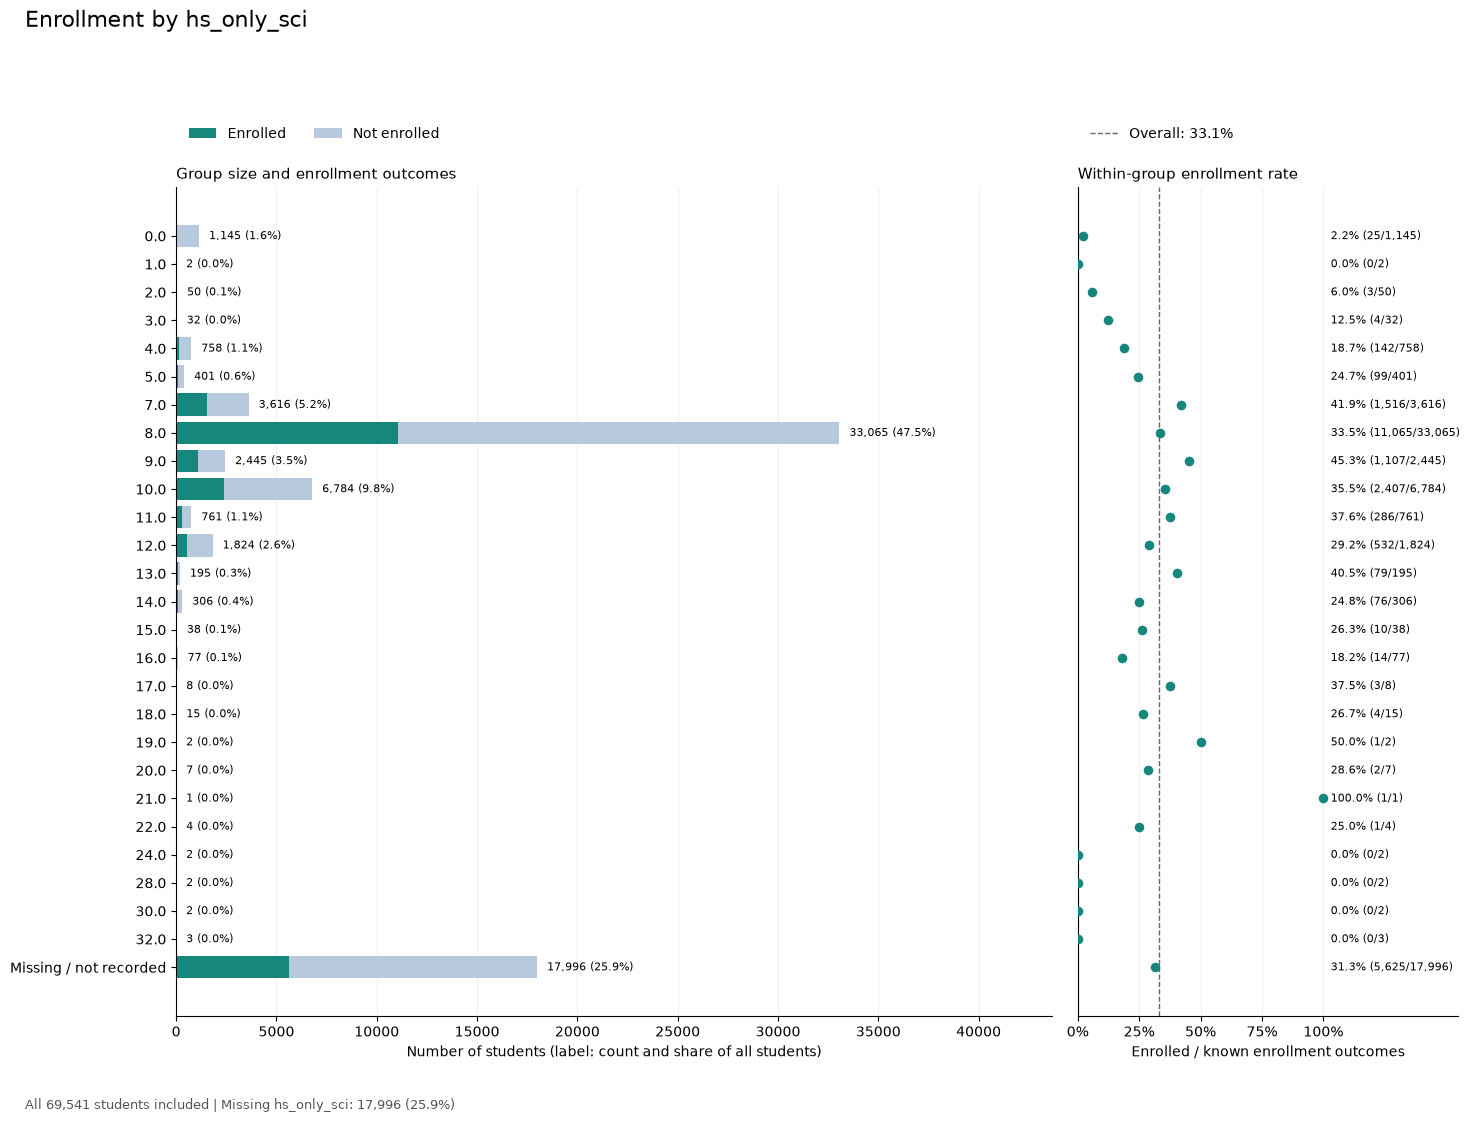

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
0.0,25,1120,0,1145,2.183406
1.0,0,2,0,2,0.000000
2.0,3,47,0,50,6.000000
3.0,4,28,0,32,12.500000
4.0,142,616,0,758,18.733509
5.0,99,302,0,401,24.688279
7.0,1516,2100,0,3616,41.924779
8.0,11065,22000,0,33065,33.464388
9.0,1107,1338,0,2445,45.276074


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\hs_only_sci.png


In [61]:
summary, saved_plot = plot_column(dataset, 'hs_only_sci')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `rotc_interest`


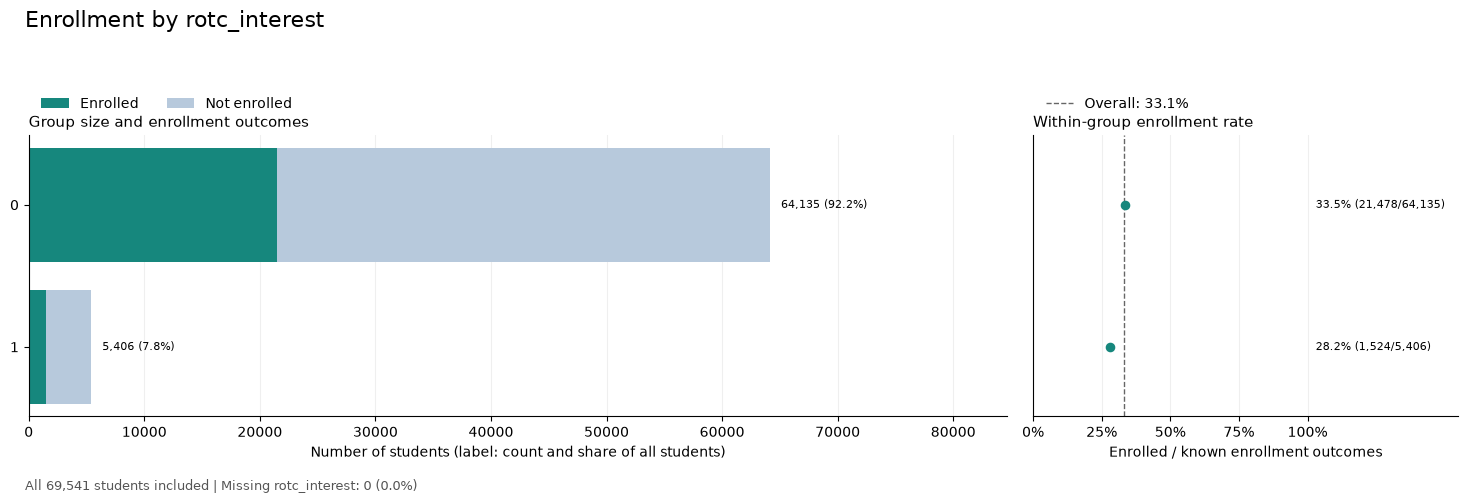

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
0,21478,42657,0,64135,33.488735
1,1524,3882,0,5406,28.190899


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\rotc_interest.png


In [62]:
summary, saved_plot = plot_column(dataset, 'rotc_interest')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `miles_from_campus`


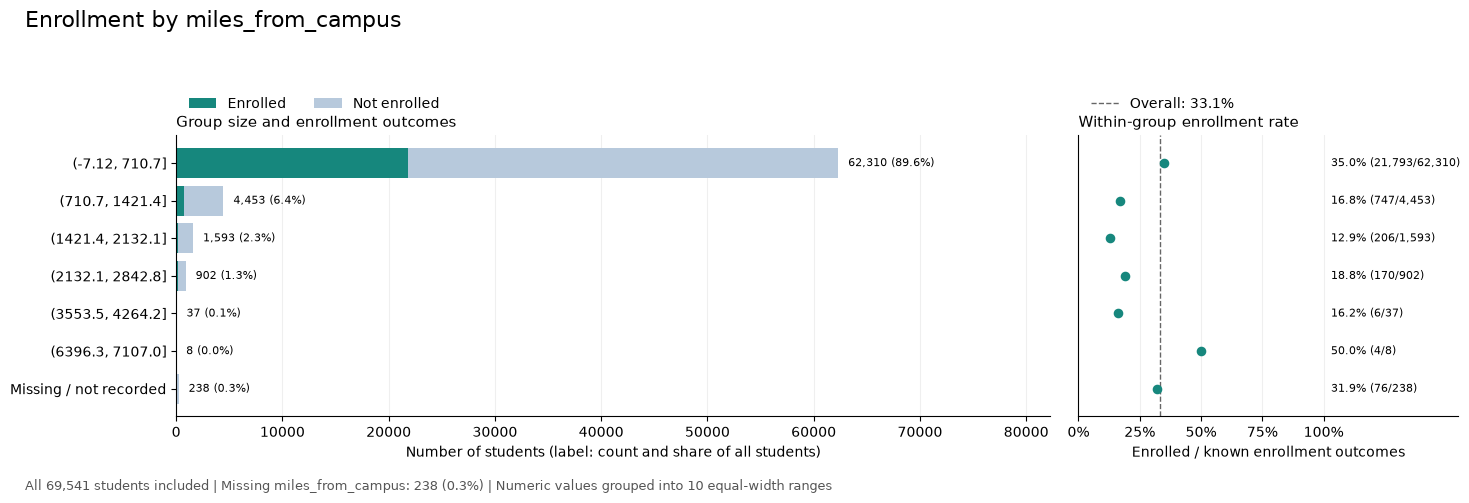

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
"(-7.12, 710.7]",21793,40517,0,62310,34.975124
"(710.7, 1421.4]",747,3706,0,4453,16.775208
"(1421.4, 2132.1]",206,1387,0,1593,12.931576
"(2132.1, 2842.8]",170,732,0,902,18.847007
"(3553.5, 4264.2]",6,31,0,37,16.216216
"(6396.3, 7107.0]",4,4,0,8,50.000000
Missing / not recorded,76,162,0,238,31.932773


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\miles_from_campus.png


In [63]:
summary, saved_plot = plot_column(dataset, 'miles_from_campus')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `veteran`


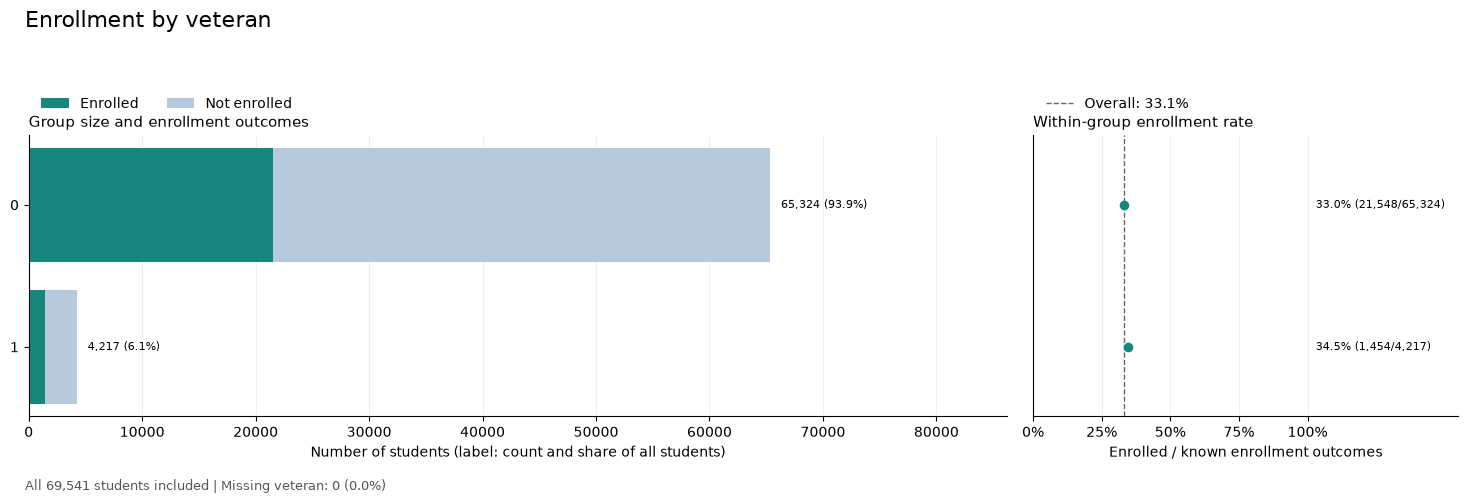

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
0,21548,43776,0,65324,32.986345
1,1454,2763,0,4217,34.479488


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\veteran.png


In [64]:
summary, saved_plot = plot_column(dataset, 'veteran')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `age`


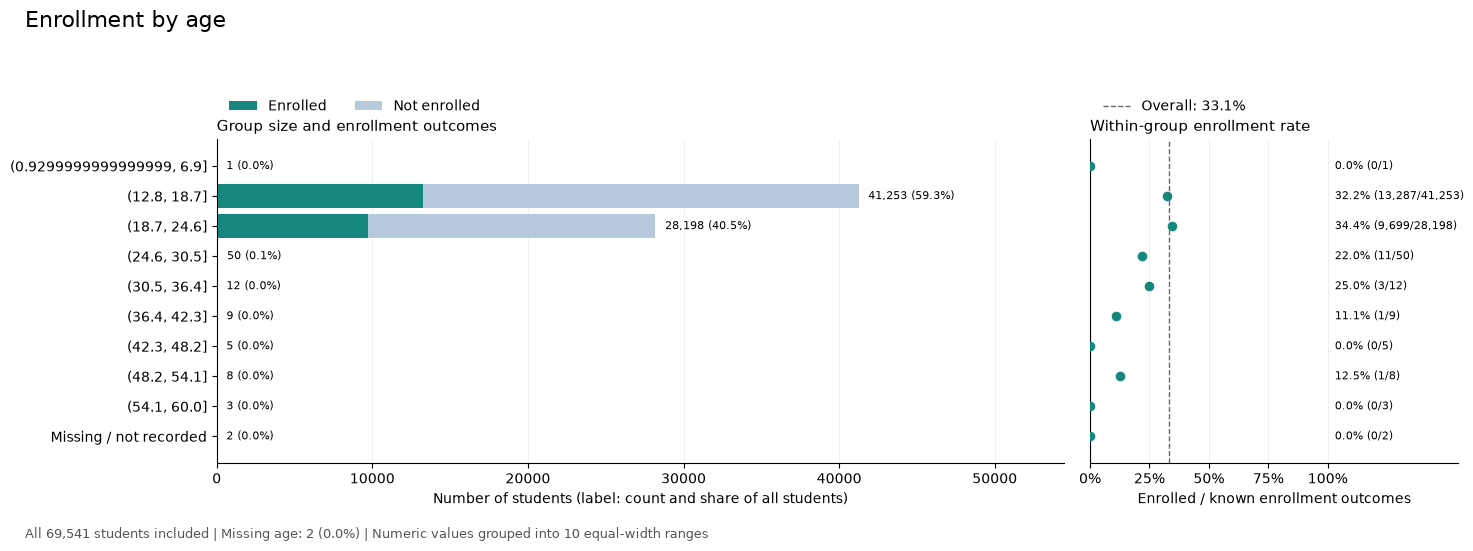

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
"(0.9299999999999999, 6.9]",0,1,0,1,0.000000
"(12.8, 18.7]",13287,27966,0,41253,32.208567
"(18.7, 24.6]",9699,18499,0,28198,34.396056
"(24.6, 30.5]",11,39,0,50,22.000000
"(30.5, 36.4]",3,9,0,12,25.000000
"(36.4, 42.3]",1,8,0,9,11.111111
"(42.3, 48.2]",0,5,0,5,0.000000
"(48.2, 54.1]",1,7,0,8,12.500000
"(54.1, 60.0]",0,3,0,3,0.000000


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\age.png


In [65]:
summary, saved_plot = plot_column(dataset, 'age')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `stem_major`


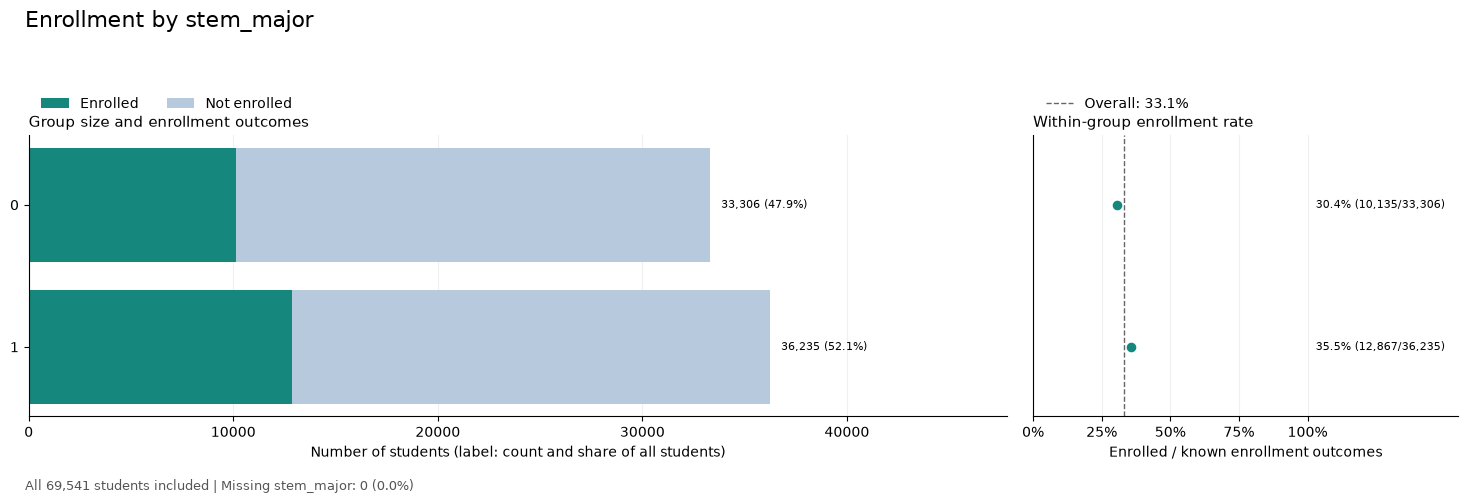

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
0,10135,23171,0,33306,30.429953
1,12867,23368,0,36235,35.509866


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\stem_major.png


In [66]:
summary, saved_plot = plot_column(dataset, 'stem_major')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `urm`


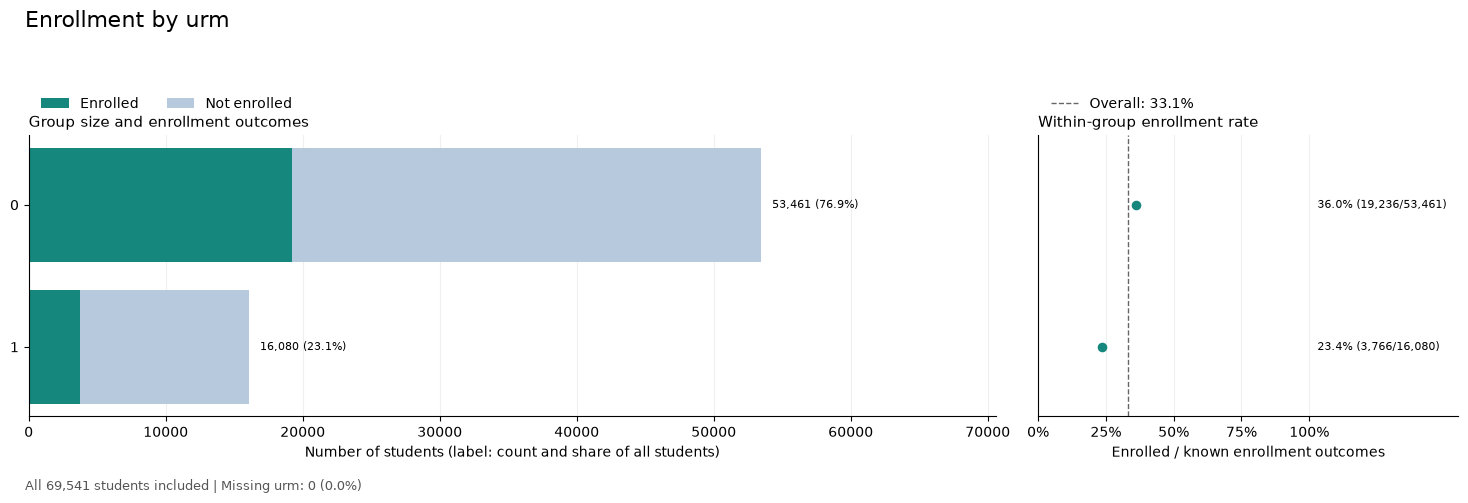

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
0,19236,34225,0,53461,35.981370
1,3766,12314,0,16080,23.420398


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\urm.png


In [67]:
summary, saved_plot = plot_column(dataset, 'urm')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `sex`


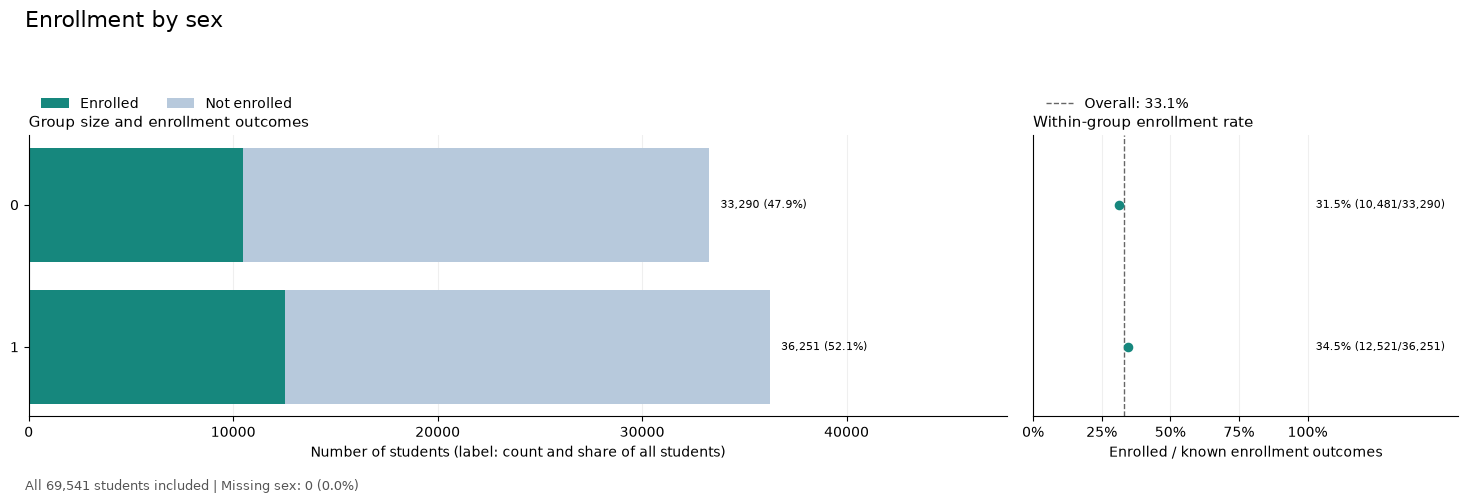

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
0,10481,22809,0,33290,31.483929
1,12521,23730,0,36251,34.539737


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\sex.png


In [68]:
summary, saved_plot = plot_column(dataset, 'sex')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


### Enrollment by `college`


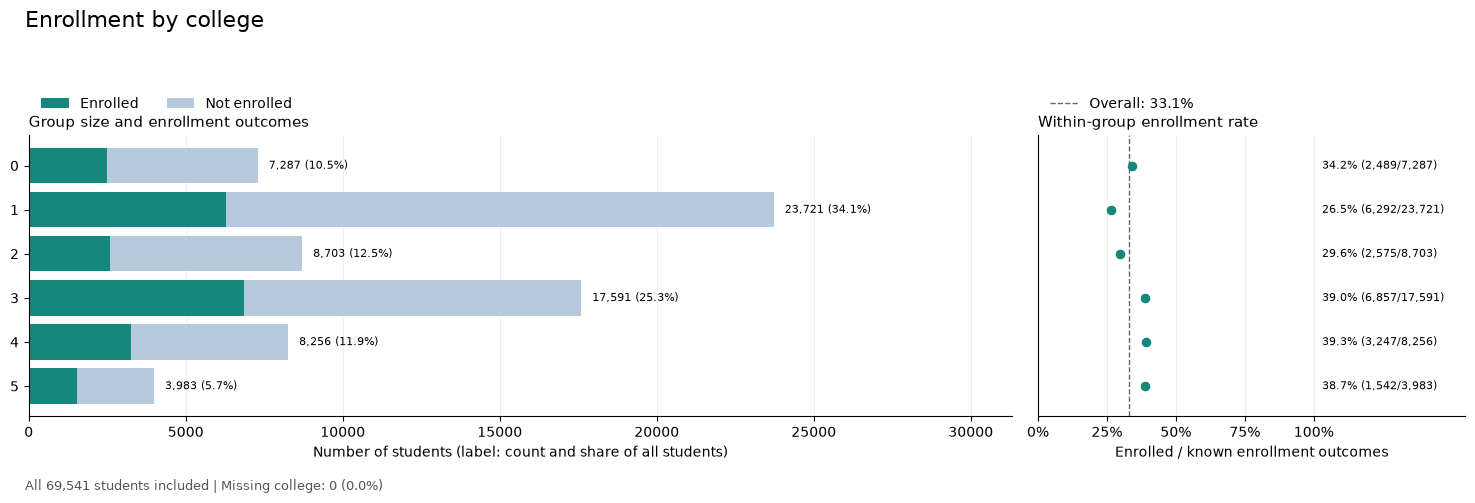

,enrolled,not_enrolled,unknown,total,enrollment_rate_percent
category,,,,,
0,2489,4798,0,7287,34.156717
1,6292,17429,0,23721,26.525020
2,2575,6128,0,8703,29.587499
3,6857,10734,0,17591,38.980160
4,3247,5009,0,8256,39.328973
5,1542,2441,0,3983,38.714537


Saved: c:\Users\Grcar\Documents\datathon\preliminary_plots\college.png


In [69]:
summary, saved_plot = plot_column(dataset, 'college')
display(summary.rename(columns={"rate": "enrollment_rate_percent"}))
print(f"Saved: {saved_plot}")


## 4. Review the saved charts


In [70]:
plot_files = sorted(OUTPUT_DIR.glob("*.png"))
display(pd.DataFrame({"saved_chart": [path.name for path in plot_files]}))


,saved_chart
0,acceptance_fee.png
1,act_cmpst.png
2,act_engl.png
3,act_math.png
4,admitted.png
...,...
60,veteran.png
61,visit_dt.png
62,visit_mo.png
63,visit_yr.png
